# 03 - Machine Learning Models

## Objectif du notebook

Dans ce notebook, nous préparons les données pour la partie Machine Learning.

Nous utilisons le fichier produit dans le notebook précédent :

`data/processed/features_clean.csv`

Ce fichier contient les trajectoires :

- nettoyées ;
- resamplées à 10 secondes ;
- enrichies avec des features temporelles et géométriques.

Dans cette première partie du notebook, nous allons :

1. charger le fichier `features_clean.csv` ;
2. créer les targets futures à prédire ;
3. créer les colonnes génériques `lat_future`, `lon_future`, `altitude_future`, `intent_future` selon l'horizon choisi ;
4. **sauvegarder le fichier avec les targets futures** ;
5. supprimer les lignes sans targets futures ;
6. choisir les features `X` et les targets `y` ;
7. séparer les données en train, validation et test ;
8. sauvegarder les datasets ML et les splits.

La normalisation et la PCA seront faites après le split afin d’éviter toute fuite de données.


# 1. Initialisation

Nous commençons par monter Google Drive, importer les bibliothèques nécessaires et définir les chemins du projet.

**Important :** dans Colab, il faut exécuter cette section avant toutes les autres cellules, sinon des erreurs comme `NameError: Path is not defined` peuvent apparaître.


In [ ]:
# Monter Google Drive + imports principaux
from google.colab import drive

drive.mount("/content/drive")

from pathlib import Path
import gc

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

print("Initialisation terminée.")


In [ ]:
# Configuration d'affichage
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 100)

In [ ]:
# Chemin principal du projet
# Ce chemin fonctionne si le dossier partagé est ajouté comme raccourci dans Mon Drive.
PROJECT_DIR = Path("/content/drive/MyDrive/aircraft-trajectory-prediction")

# Dossiers du projet
DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
INTERIM_DIR = DATA_DIR / "interim"
PROCESSED_DIR = DATA_DIR / "processed"

RESULTS_DIR = PROJECT_DIR / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
MODELS_DIR = PROJECT_DIR / "models" / "ml"
ML_SPLITS_DIR = PROCESSED_DIR / "ml_splits"

# Création des dossiers si nécessaire
for folder in [DATA_DIR, RAW_DIR, INTERIM_DIR, PROCESSED_DIR, RESULTS_DIR, METRICS_DIR, MODELS_DIR, ML_SPLITS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Vérification des chemins
print("Projet existe :", PROJECT_DIR.exists())
print("Dossier data existe :", DATA_DIR.exists())
print("Dossier raw existe :", RAW_DIR.exists())
print("Dossier interim existe :", INTERIM_DIR.exists())
print("Dossier processed existe :", PROCESSED_DIR.exists())
print("Dossier metrics existe :", METRICS_DIR.exists())
print("Dossier models/ml existe :", MODELS_DIR.exists())
print("Dossier ml_splits existe :", ML_SPLITS_DIR.exists())

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        "Le dossier du projet est introuvable. "
        "Ajoute le dossier partagé aircraft-trajectory-prediction comme raccourci dans Mon Drive."
    )


# 2. Chargement d’un échantillon représentatif de trajectoires

Le fichier `features_clean.csv` est volumineux.

Au lieu de charger simplement les premières lignes du fichier, nous sélectionnons un échantillon aléatoire de `trajectory_id`.

Cette méthode est plus correcte car elle permet de conserver des trajectoires complètes.

La logique est la suivante :

1. lire uniquement la colonne `trajectory_id` ;
2. sélectionner aléatoirement un nombre de trajectoires ;
3. relire le fichier par chunks ;
4. garder seulement les lignes appartenant aux trajectoires sélectionnées.

Cette méthode évite de charger tout le fichier en mémoire et limite le biais lié aux premières lignes du fichier.

In [ ]:
# Chemin du fichier features
features_path = PROCESSED_DIR / "features_clean.csv"

print("Chemin du fichier features :", features_path)
print("Fichier existe :", features_path.exists())

if not features_path.exists():
    raise FileNotFoundError("Le fichier features_clean.csv est introuvable.")

In [ ]:
# Lire uniquement l'en-tête du fichier pour connaître les colonnes disponibles
available_columns = pd.read_csv(features_path, nrows=0).columns.tolist()

print("Nombre de colonnes disponibles :", len(available_columns))
print("Colonnes disponibles :")

for col in available_columns:
    print("-", col)

Nous définissons maintenant les colonnes nécessaires pour la partie ML.

Nous gardons :

- les identifiants nécessaires au split ;
- les variables de position et mouvement ;
- les features créées dans le notebook précédent ;
- la colonne `flight_phase`, qui servira à créer la target de classification d’intention.

In [ ]:
# Colonnes que nous voulons utiliser si elles existent dans le fichier
candidate_columns = [
    # Identifiants et temps
    "datetime",
    "icao24",
    "trajectory_id",

    # Position et mouvement de base
    "lat",
    "lon",
    "altitude",
    "velocity",
    "heading",
    "vertrate",

    # Features cinématiques
    "ground_speed_ms",
    "vertical_rate_fpm",
    "acceleration",
    "turn_rate",

    # Features de direction
    "vx_ms",
    "vy_ms",
    "vz_ms",
    "heading_sin",
    "heading_cos",

    # Features géométriques
    "distance_step_m",
    "distance_traveled_m",
    "trajectory_angle",
    "distance_destination_m",
    "elapsed_time_sec",

    # Rolling features
    "roll_mean_velocity",
    "roll_std_velocity",
    "roll_mean_altitude",
    "roll_std_altitude",
    "roll_mean_vertrate",
    "roll_std_vertrate",
    "roll_mean_acceleration",
    "roll_std_acceleration",
    "roll_mean_turn_rate",
    "roll_std_turn_rate",
    "roll_mean_distance_step_m",
    "roll_std_distance_step_m",

    # Phase de vol estimée
    "flight_phase"
]

# Garder seulement les colonnes réellement présentes dans le fichier
columns_to_load = [
    col for col in candidate_columns
    if col in available_columns
]

print("Nombre de colonnes chargées :", len(columns_to_load))
print("Colonnes chargées :")

for col in columns_to_load:
    print("-", col)

# Vérification des colonnes indispensables
required_columns = [
    "datetime",
    "icao24",
    "trajectory_id",
    "lat",
    "lon",
    "altitude",
    "flight_phase"
]

missing_required_columns = [
    col for col in required_columns
    if col not in columns_to_load
]

if len(missing_required_columns) == 0:
    print("OK : toutes les colonnes indispensables sont présentes.")
else:
    raise ValueError(f"Colonnes indispensables manquantes : {missing_required_columns}")

In [ ]:
# Lire uniquement la colonne trajectory_id par chunks.
# Cela évite de charger tout le fichier features_clean.csv en mémoire.

CHUNK_SIZE = 500_000

trajectory_id_set = set()

print("Lecture des trajectory_id disponibles...")

for i, chunk in enumerate(
    pd.read_csv(
        features_path,
        usecols=["trajectory_id"],
        chunksize=CHUNK_SIZE
    ),
    start=1
):
    # Convertir en string pour éviter les problèmes de type
    trajectory_ids_chunk = (
        chunk["trajectory_id"]
        .astype("string")
        .dropna()
        .unique()
    )

    # Ajouter les ids au set global
    trajectory_id_set.update(trajectory_ids_chunk)

    if i % 5 == 0:
        print(f"{i} chunks lus...")

# Convertir en liste triée pour avoir un ordre stable
all_trajectory_ids = sorted(list(trajectory_id_set))

print("Nombre total de trajectoires disponibles :", len(all_trajectory_ids))

In [ ]:
# Nombre de trajectoires à utiliser pour les premières expériences ML.
# Tu peux augmenter cette valeur si la RAM le permet.
N_TRAJECTORIES_SAMPLE = 2000

# Sécurité : ne pas demander plus de trajectoires que disponible
N_TRAJECTORIES_SAMPLE = min(N_TRAJECTORIES_SAMPLE, len(all_trajectory_ids))

# Sélection aléatoire reproductible
rng = np.random.default_rng(seed=42)

sampled_trajectory_ids = rng.choice(
    all_trajectory_ids,
    size=N_TRAJECTORIES_SAMPLE,
    replace=False
)

# Convertir en set pour accélérer le filtrage
sampled_trajectory_ids = set(sampled_trajectory_ids.astype(str))

print("Nombre de trajectoires sélectionnées :", len(sampled_trajectory_ids))

In [ ]:
# Nous relisons le fichier par chunks et gardons seulement les trajectoires sélectionnées.

sample_parts = []

print("Chargement des trajectoires sélectionnées...")

for i, chunk in enumerate(
    pd.read_csv(
        features_path,
        usecols=columns_to_load,
        chunksize=CHUNK_SIZE,
        parse_dates=["datetime"]
    ),
    start=1
):
    # Convertir trajectory_id en string pour correspondre au set sélectionné
    chunk["trajectory_id"] = chunk["trajectory_id"].astype(str)

    # Filtrer uniquement les trajectoires sélectionnées
    chunk_sample = chunk[
        chunk["trajectory_id"].isin(sampled_trajectory_ids)
    ]

    # Ajouter seulement si le chunk contient des lignes utiles
    if len(chunk_sample) > 0:
        sample_parts.append(chunk_sample)

    # Affichage simple de progression
    if i % 5 == 0:
        print(f"{i} chunks traités...")

# Vérifier qu'on a bien récupéré des lignes
if len(sample_parts) == 0:
    raise ValueError(
        "Aucune ligne n'a été trouvée pour les trajectoires sélectionnées. "
        "Vérifie que trajectory_id a le même type dans sampled_trajectory_ids et dans le fichier."
    )

# Concaténer les chunks filtrés
df = pd.concat(sample_parts, ignore_index=True)

print("Échantillon de trajectoires chargé avec succès.")
print("-----------------------------------------------")
print("Shape :", df.shape)
print("Nombre d'avions :", df["icao24"].nunique())
print("Nombre de trajectoires :", df["trajectory_id"].nunique())
print("Période :", df["datetime"].min(), "→", df["datetime"].max())

display(df.head())

# 3. Création des targets futures

Le but du modèle est de prédire la trajectoire future de l’avion.

Le sujet demande une prédiction sur un horizon de 2 à 10 minutes.

Nous allons donc créer des targets futures pour trois horizons :

- 2 minutes ;
- 5 minutes ;
- 10 minutes.

Comme les données sont resamplées toutes les 10 secondes :

- 2 minutes = 12 lignes plus tard ;
- 5 minutes = 30 lignes plus tard ;
- 10 minutes = 60 lignes plus tard.

Pour chaque horizon, nous créons :

- `lat_future_Xmin`
- `lon_future_Xmin`
- `altitude_future_Xmin`
- `intent_future_Xmin`

où `X` représente l’horizon en minutes.

In [ ]:
# Fréquence du resampling
RESAMPLING_SECONDS = 10

# Horizons demandés dans le projet
HORIZONS_MINUTES = [2, 5, 10]

print("Fréquence des données :", RESAMPLING_SECONDS, "secondes")
print("Horizons utilisés :", HORIZONS_MINUTES, "minutes")

for horizon_min in HORIZONS_MINUTES:
    horizon_seconds = horizon_min * 60
    horizon_steps = horizon_seconds // RESAMPLING_SECONDS

    print(
        f"Horizon {horizon_min} min : "
        f"{horizon_seconds} secondes = {horizon_steps} lignes"
    )

In [ ]:
# Vérifier que df existe avant de continuer
if "df" not in globals():
    raise NameError(
        "df n'existe pas. Exécute d'abord la cellule de chargement des trajectoires sélectionnées."
    )

# Trier par trajectoire et par temps avant de créer les targets
df = df.sort_values(
    ["trajectory_id", "datetime"]
).reset_index(drop=True)

print("Données triées par trajectory_id et datetime.")

In [ ]:
# Création des targets futures pour plusieurs horizons
for horizon_min in HORIZONS_MINUTES:

    horizon_steps = (horizon_min * 60) // RESAMPLING_SECONDS

    # Targets de régression
    df[f"lat_future_{horizon_min}min"] = (
        df.groupby("trajectory_id")["lat"]
        .shift(-horizon_steps)
    )

    df[f"lon_future_{horizon_min}min"] = (
        df.groupby("trajectory_id")["lon"]
        .shift(-horizon_steps)
    )

    df[f"altitude_future_{horizon_min}min"] = (
        df.groupby("trajectory_id")["altitude"]
        .shift(-horizon_steps)
    )

    # Target de classification d'intention
    df[f"intent_future_{horizon_min}min"] = (
        df.groupby("trajectory_id")["flight_phase"]
        .shift(-horizon_steps)
    )

print("Targets futures créées avec succès pour les horizons :", HORIZONS_MINUTES)

In [ ]:
target_preview_cols = [
    "trajectory_id",
    "datetime",
    "lat",
    "lon",
    "altitude",
    "flight_phase",
    "lat_future_2min",
    "lon_future_2min",
    "altitude_future_2min",
    "intent_future_2min",
    "lat_future_5min",
    "lon_future_5min",
    "altitude_future_5min",
    "intent_future_5min",
    "lat_future_10min",
    "lon_future_10min",
    "altitude_future_10min",
    "intent_future_10min"
]

target_preview_cols = [
    col for col in target_preview_cols
    if col in df.columns
]

display(df[target_preview_cols].head(20))

In [ ]:
target_columns = []

for horizon_min in HORIZONS_MINUTES:
    target_columns += [
        f"lat_future_{horizon_min}min",
        f"lon_future_{horizon_min}min",
        f"altitude_future_{horizon_min}min",
        f"intent_future_{horizon_min}min"
    ]

missing_targets = df[target_columns].isna().sum().reset_index()
missing_targets.columns = ["target", "missing_count"]

display(missing_targets)

# 4. Choix de l’horizon de prédiction

Nous avons créé les targets pour 2, 5 et 10 minutes.

Pour entraîner un modèle, nous choisissons maintenant un horizon précis.

Dans un premier temps, nous utilisons l’horizon de 2 minutes pour valider le pipeline ML.

Ensuite, il suffira de changer la valeur de `SELECTED_HORIZON_MIN` pour entraîner les modèles à 5 minutes ou 10 minutes.

In [ ]:
# Horizon utilisé pour cette expérimentation ML
SELECTED_HORIZON_MIN = 2

# Vérification que l'horizon choisi existe
if SELECTED_HORIZON_MIN not in HORIZONS_MINUTES:
    raise ValueError(
        f"L'horizon choisi doit être dans {HORIZONS_MINUTES}."
    )

print("Horizon sélectionné :", SELECTED_HORIZON_MIN, "minutes")

## 4.1. Création des targets génériques et sauvegarde

Les targets ont été créées avec des noms dépendant de l'horizon, par exemple :

- `lat_future_2min`
- `lon_future_2min`
- `altitude_future_2min`
- `intent_future_2min`

Pour la suite du notebook, nous créons maintenant des noms génériques :

- `lat_future`
- `lon_future`
- `altitude_future`
- `intent_future`

Ces colonnes correspondent à l'horizon choisi dans `SELECTED_HORIZON_MIN`.

Ensuite, nous sauvegardons un fichier contenant les features et les targets futures.


In [ ]:
# Créer les colonnes futures génériques selon l'horizon sélectionné
selected_target_columns = {
    "lat_future": f"lat_future_{SELECTED_HORIZON_MIN}min",
    "lon_future": f"lon_future_{SELECTED_HORIZON_MIN}min",
    "altitude_future": f"altitude_future_{SELECTED_HORIZON_MIN}min",
    "intent_future": f"intent_future_{SELECTED_HORIZON_MIN}min",
}

# Vérification que les colonnes spécifiques existent bien
missing_selected_targets = [
    source_col
    for source_col in selected_target_columns.values()
    if source_col not in df.columns
]

if len(missing_selected_targets) > 0:
    raise KeyError(f"Targets spécifiques manquantes : {missing_selected_targets}")

# Création des colonnes génériques utilisées dans la suite du notebook
for generic_col, source_col in selected_target_columns.items():
    df[generic_col] = df[source_col]

print("Targets génériques créées pour l'horizon :", SELECTED_HORIZON_MIN, "minutes")
print("Colonnes créées :", list(selected_target_columns.keys()))

display(
    df[
        [
            "trajectory_id",
            "datetime",
            "lat",
            "lon",
            "altitude",
            "flight_phase",
            "lat_future",
            "lon_future",
            "altitude_future",
            "intent_future",
        ]
    ].head(10)
)


In [ ]:
# Sauvegarder le fichier contenant les targets futures
# Ce fichier contient encore les lignes de fin de trajectoire qui peuvent avoir des targets NaN.
targets_output_path = PROCESSED_DIR / f"features_with_targets_{SELECTED_HORIZON_MIN}min.csv"

df.to_csv(targets_output_path, index=False)

print("Fichier avec targets futures sauvegardé avec succès.")
print("Chemin :", targets_output_path)
print("Shape sauvegardée :", df.shape)


# 5. Suppression des lignes sans targets futures

À la fin de chaque trajectoire, il n’existe pas toujours un point situé dans le futur.

Par exemple, pour un horizon de 10 minutes, les 60 dernières lignes de chaque trajectoire n’ont pas de target future.

Nous supprimons donc les lignes qui n’ont pas de target pour l’horizon sélectionné.

Important :

Nous supprimons les lignes manquantes seulement pour l’horizon choisi, et non pour tous les horizons à la fois.

In [ ]:
# Nombre de lignes avant suppression
n_before = len(df)

# Supprimer les lignes sans targets futures
df_ml = df.dropna(
    subset=[
        "lat_future",
        "lon_future",
        "altitude_future",
        "intent_future"
    ]
).reset_index(drop=True)

n_after = len(df_ml)

print("Suppression des lignes sans targets")
print("-----------------------------------")
print("Lignes avant :", f"{n_before:,}")
print("Lignes après :", f"{n_after:,}")
print("Lignes supprimées :", f"{n_before - n_after:,}")

In [ ]:
# Vérification après suppression
missing_after_target_cleaning = df_ml[
    [
        "lat_future",
        "lon_future",
        "altitude_future",
        "intent_future"
    ]
].isna().sum()

display(missing_after_target_cleaning)

if missing_after_target_cleaning.sum() == 0:
    print("OK : aucune target future manquante.")
else:
    print("Attention : certaines targets futures sont encore manquantes.")

In [ ]:
# Distribution de la target de classification
print("Distribution de la target intent_future")
print("---------------------------------------")

intent_counts = df_ml["intent_future"].value_counts().reset_index()
intent_counts.columns = ["intent_future", "count"]

display(intent_counts)

# 6. Choix des features et des targets

Nous définissons :

- `X` : les variables utilisées pour prédire ;
- `y_reg` : les targets de régression ;
- `y_clf` : la target de classification.

Nous ne mettons pas directement dans `X` :

- `datetime` ;
- `icao24` ;
- `trajectory_id` ;
- `flight_phase` ;
- les targets futures.

Ces colonnes sont soit des identifiants, soit des variables textuelles, soit des targets.

In [ ]:
# Features numériques candidates
FEATURES = [
    # Position et mouvement de base
    "lat",
    "lon",
    "altitude",
    "velocity",
    "heading",
    "vertrate",

    # Features cinématiques
    "ground_speed_ms",
    "vertical_rate_fpm",
    "acceleration",
    "turn_rate",

    # Direction et mouvement
    "vx_ms",
    "vy_ms",
    "vz_ms",
    "heading_sin",
    "heading_cos",

    # Features géométriques
    "distance_step_m",
    "distance_traveled_m",
    "trajectory_angle",
    "distance_destination_m",
    "elapsed_time_sec",

    # Rolling features
    "roll_mean_velocity",
    "roll_std_velocity",
    "roll_mean_altitude",
    "roll_std_altitude",
    "roll_mean_vertrate",
    "roll_std_vertrate",
    "roll_mean_acceleration",
    "roll_std_acceleration",
    "roll_mean_turn_rate",
    "roll_std_turn_rate",
    "roll_mean_distance_step_m",
    "roll_std_distance_step_m"
]

# Garder uniquement les features présentes dans df_ml
FEATURES = [
    col for col in FEATURES
    if col in df_ml.columns
]

# Targets de régression
TARGETS_REG = [
    "lat_future",
    "lon_future",
    "altitude_future"
]

# Target classification
TARGET_CLF = "intent_future"

print("Nombre de features utilisées :", len(FEATURES))
print("Features utilisées :")

for col in FEATURES:
    print("-", col)

print("\nTargets de régression :", TARGETS_REG)
print("Target de classification :", TARGET_CLF)

In [ ]:
# Remplacer les valeurs infinies par NaN si elles existent
df_ml = df_ml.replace([np.inf, -np.inf], np.nan)

# Colonnes nécessaires pour le ML
required_ml_columns = FEATURES + TARGETS_REG + [TARGET_CLF, "trajectory_id", "icao24"]

n_before = len(df_ml)

# Supprimer les lignes avec NaN dans les features ou targets
df_ml = df_ml.dropna(
    subset=required_ml_columns
).reset_index(drop=True)

n_after = len(df_ml)

print("Nettoyage final avant split")
print("--------------------------")
print("Lignes avant :", f"{n_before:,}")
print("Lignes après :", f"{n_after:,}")
print("Lignes supprimées :", f"{n_before - n_after:,}")

## 5.1. Sauvegarde du dataset ML nettoyé

Après suppression des lignes sans targets et des lignes contenant des valeurs manquantes dans les features, nous sauvegardons le dataset prêt pour le split ML.


In [ ]:
# Sauvegarder le dataset ML nettoyé
# Ce fichier est celui à réutiliser directement pour entraîner les modèles sur l'horizon sélectionné.
ml_dataset_path = PROCESSED_DIR / f"ml_dataset_{SELECTED_HORIZON_MIN}min.csv"

df_ml.to_csv(ml_dataset_path, index=False)

print("Dataset ML nettoyé sauvegardé avec succès.")
print("Chemin :", ml_dataset_path)
print("Shape sauvegardée :", df_ml.shape)


In [ ]:
# Matrice des features
X = df_ml[FEATURES]

# Targets de régression
y_reg = df_ml[TARGETS_REG]

# Target de classification
y_clf = df_ml[TARGET_CLF]

print("Shape de X :", X.shape)
print("Shape de y_reg :", y_reg.shape)
print("Shape de y_clf :", y_clf.shape)

# 7. Split train / validation / test par `trajectory_id`

Nous divisons les données en trois ensembles :

- train : 70 %
- validation : 15 %
- test : 15 %

Le split est fait par `trajectory_id`.

Pourquoi ?

Parce qu’il ne faut pas mettre des points d’une même trajectoire dans le train et dans le test.

Si on mélange les lignes d’une même trajectoire entre train et test, l’évaluation devient trop optimiste.

In [ ]:
# Liste des trajectoires uniques
unique_trajectories = df_ml["trajectory_id"].unique()

print("Nombre total de trajectoires :", len(unique_trajectories))

In [ ]:
# Split des trajectory_id : 70% train et 30% temporaire
train_traj, temp_traj = train_test_split(
    unique_trajectories,
    test_size=0.30,
    random_state=42
)

# Split du temporaire : moitié validation, moitié test
val_traj, test_traj = train_test_split(
    temp_traj,
    test_size=0.50,
    random_state=42
)

print("Nombre de trajectoires train :", len(train_traj))
print("Nombre de trajectoires validation :", len(val_traj))
print("Nombre de trajectoires test :", len(test_traj))

In [ ]:
# Créer les masques
train_mask = df_ml["trajectory_id"].isin(train_traj)
val_mask = df_ml["trajectory_id"].isin(val_traj)
test_mask = df_ml["trajectory_id"].isin(test_traj)

# Créer les datasets
X_train = df_ml.loc[train_mask, FEATURES].copy()
X_val = df_ml.loc[val_mask, FEATURES].copy()
X_test = df_ml.loc[test_mask, FEATURES].copy()

y_train_reg = df_ml.loc[train_mask, TARGETS_REG].copy()
y_val_reg = df_ml.loc[val_mask, TARGETS_REG].copy()
y_test_reg = df_ml.loc[test_mask, TARGETS_REG].copy()

y_train_clf = df_ml.loc[train_mask, TARGET_CLF].copy()
y_val_clf = df_ml.loc[val_mask, TARGET_CLF].copy()
y_test_clf = df_ml.loc[test_mask, TARGET_CLF].copy()

print("Split terminé.")
print("---------------")
print("X_train :", X_train.shape)
print("X_val   :", X_val.shape)
print("X_test  :", X_test.shape)

print("\ny_train_reg :", y_train_reg.shape)
print("y_val_reg   :", y_val_reg.shape)
print("y_test_reg  :", y_test_reg.shape)

print("\ny_train_clf :", y_train_clf.shape)
print("y_val_clf   :", y_val_clf.shape)
print("y_test_clf  :", y_test_clf.shape)

## 7.1. Sauvegarde des splits ML

Nous sauvegardons les jeux `X` et `y` afin de pouvoir les réutiliser dans les cellules de modélisation sans refaire toute la préparation.


In [ ]:
# Sauvegarder les splits dans data/processed/ml_splits
split_objects = {
    "X_train": X_train,
    "X_val": X_val,
    "X_test": X_test,
    "y_train_reg": y_train_reg,
    "y_val_reg": y_val_reg,
    "y_test_reg": y_test_reg,
    "y_train_clf": y_train_clf.to_frame(name=TARGET_CLF),
    "y_val_clf": y_val_clf.to_frame(name=TARGET_CLF),
    "y_test_clf": y_test_clf.to_frame(name=TARGET_CLF),
}

for name, data in split_objects.items():
    output_path = ML_SPLITS_DIR / f"{name}_{SELECTED_HORIZON_MIN}min.csv"
    data.to_csv(output_path, index=False)
    print(f"{name} sauvegardé : {output_path}")

# Sauvegarder aussi les identifiants utiles pour retracer les trajectoires
metadata_columns = ["trajectory_id", "icao24", "datetime"]

split_metadata = {
    "metadata_train": df_ml.loc[train_mask, metadata_columns].copy(),
    "metadata_val": df_ml.loc[val_mask, metadata_columns].copy(),
    "metadata_test": df_ml.loc[test_mask, metadata_columns].copy(),
}

for name, data in split_metadata.items():
    output_path = ML_SPLITS_DIR / f"{name}_{SELECTED_HORIZON_MIN}min.csv"
    data.to_csv(output_path, index=False)
    print(f"{name} sauvegardé : {output_path}")

print("Tous les splits ML ont été sauvegardés avec succès.")


In [ ]:
# Vérifier qu'une trajectoire n'est pas présente dans plusieurs ensembles
train_set = set(train_traj)
val_set = set(val_traj)
test_set = set(test_traj)

overlap_train_val = train_set.intersection(val_set)
overlap_train_test = train_set.intersection(test_set)
overlap_val_test = val_set.intersection(test_set)

print("Vérification du split par trajectoire")
print("-------------------------------------")
print("Overlap train / validation :", len(overlap_train_val))
print("Overlap train / test :", len(overlap_train_test))
print("Overlap validation / test :", len(overlap_val_test))

if (
    len(overlap_train_val) == 0
    and len(overlap_train_test) == 0
    and len(overlap_val_test) == 0
):
    print("OK : aucune trajectoire n'est partagée entre train, validation et test.")
else:
    print("Attention : certaines trajectoires sont présentes dans plusieurs ensembles.")

In [ ]:
split_summary = pd.DataFrame({
    "set": ["train", "validation", "test"],
    "n_rows": [len(X_train), len(X_val), len(X_test)],
    "n_trajectories": [
        df_ml.loc[train_mask, "trajectory_id"].nunique(),
        df_ml.loc[val_mask, "trajectory_id"].nunique(),
        df_ml.loc[test_mask, "trajectory_id"].nunique()
    ],
    "n_aircraft": [
        df_ml.loc[train_mask, "icao24"].nunique(),
        df_ml.loc[val_mask, "icao24"].nunique(),
        df_ml.loc[test_mask, "icao24"].nunique()
    ]
})

display(split_summary)

In [ ]:
split_summary_path = METRICS_DIR / f"ml_split_summary_{SELECTED_HORIZON_MIN}min.csv"

split_summary.to_csv(split_summary_path, index=False)

print("Résumé du split sauvegardé avec succès.")
print("Chemin :", split_summary_path)

# Sauvegarder la liste des features utilisées
features_path = METRICS_DIR / f"ml_features_used_{SELECTED_HORIZON_MIN}min.txt"

with open(features_path, "w", encoding="utf-8") as f:
    for feature in FEATURES:
        f.write(feature + "\n")

print("Liste des features sauvegardée avec succès.")
print("Chemin :", features_path)


# Conclusion de la préparation ML

Dans cette première partie du notebook ML, nous avons préparé les données pour l'entraînement des modèles.

Nous avons :

1. chargé un échantillon aléatoire de trajectoires depuis `features_clean.csv` ;
2. créé les targets futures pour 2, 5 et 10 minutes ;
3. choisi un horizon d'expérimentation avec `SELECTED_HORIZON_MIN` ;
4. créé les colonnes génériques :
   - `lat_future`
   - `lon_future`
   - `altitude_future`
   - `intent_future`
5. sauvegardé le fichier contenant les targets futures dans `data/processed` ;
6. supprimé les lignes sans targets futures ;
7. choisi les features `X` et les targets `y` ;
8. séparé les données en train, validation et test par `trajectory_id` ;
9. sauvegardé les splits dans `data/processed/ml_splits`.

Le split par trajectoire permet d’éviter qu’une même trajectoire soit présente à la fois dans l’entraînement et dans le test.

La prochaine étape sera :

1. construire une baseline naïve ;
2. normaliser les features après le split ;
3. entraîner les modèles ML.

La normalisation vient après le split et avant les modèles.

La PCA vient après la normalisation.

## Fichiers sauvegardés

Le notebook sauvegarde notamment :

- `data/processed/features_with_targets_2min.csv`
- `data/processed/ml_dataset_2min.csv`
- `data/processed/ml_splits/X_train_2min.csv`
- `data/processed/ml_splits/X_val_2min.csv`
- `data/processed/ml_splits/X_test_2min.csv`
- `data/processed/ml_splits/y_train_reg_2min.csv`
- `data/processed/ml_splits/y_val_reg_2min.csv`
- `data/processed/ml_splits/y_test_reg_2min.csv`
- `data/processed/ml_splits/y_train_clf_2min.csv`
- `data/processed/ml_splits/y_val_clf_2min.csv`
- `data/processed/ml_splits/y_test_clf_2min.csv`


# Partie B — Modélisation Machine Learning et visualisation des résultats

À partir de cette partie, les étapes de préparation des données sont terminées.  
Nous passons à la modélisation Machine Learning, à l’évaluation des modèles et à la visualisation des résultats.

La numérotation recommence à **1** pour rendre cette partie indépendante et plus facile à présenter.

Objectifs de cette partie :

- charger les splits train / validation / test déjà sauvegardés ;
- établir une baseline naïve ;
- entraîner les modèles de régression demandés ;
- comparer les modèles avec RMSE, MAE et distance moyenne de déviation ;
- visualiser la trajectoire réelle et prédite en 2D, en 3D et sur une carte ;
- analyser les erreurs extrêmes ;
- entraîner le SVM RBF pour la classification d’intention ;
- sauvegarder les figures, les métriques et les modèles pour le rapport et la présentation.

## 1. Chargement des splits ML

Cette section recharge les fichiers déjà créés dans la partie préparation.

Cette étape rend la partie modélisation indépendante : même si les variables `X_train`, `X_val`, `X_test` ne sont plus en mémoire, le notebook peut reprendre à partir des fichiers sauvegardés.

In [ ]:
# ============================================================
# 8. Chargement des fichiers nécessaires pour la partie ML
# ============================================================

from pathlib import Path
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.svm import SVC
from sklearn.decomposition import PCA

# Monter Google Drive si le notebook est exécuté dans Colab
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    print("Google Drive est déjà monté ou l'environnement n'est pas Colab.")

# Chemin principal du projet
# Pour travailler sur une copie privée, remplacer par :
# PROJECT_DIR = Path("/content/drive/MyDrive/aircraft-trajectory-prediction_PRIVATE_COPY")
PROJECT_DIR = Path("/content/drive/MyDrive/aircraft-trajectory-prediction")

DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
ML_SPLITS_DIR = PROCESSED_DIR / "ml_splits"

RESULTS_DIR = PROJECT_DIR / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"
MODELS_DIR = PROJECT_DIR / "models" / "ml"

# Création des dossiers de sortie si nécessaire
for folder in [METRICS_DIR, FIGURES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SELECTED_HORIZON_MIN = 2

print("Chemins définis avec succès.")
print("PROJECT_DIR   :", PROJECT_DIR)
print("ML_SPLITS_DIR :", ML_SPLITS_DIR)
print("METRICS_DIR   :", METRICS_DIR)
print("FIGURES_DIR   :", FIGURES_DIR)
print("MODELS_DIR    :", MODELS_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Chemins définis avec succès.
PROJECT_DIR   : /content/drive/MyDrive/aircraft-trajectory-prediction
ML_SPLITS_DIR : /content/drive/MyDrive/aircraft-trajectory-prediction/data/processed/ml_splits
METRICS_DIR   : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics
FIGURES_DIR   : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures
MODELS_DIR    : /content/drive/MyDrive/aircraft-trajectory-prediction/models/ml


In [ ]:
# ============================================================
# 8.1. Vérification et chargement des fichiers
# ============================================================

X_train_path = ML_SPLITS_DIR / f"X_train_{SELECTED_HORIZON_MIN}min.csv"
X_val_path   = ML_SPLITS_DIR / f"X_val_{SELECTED_HORIZON_MIN}min.csv"
X_test_path  = ML_SPLITS_DIR / f"X_test_{SELECTED_HORIZON_MIN}min.csv"

y_train_reg_path = ML_SPLITS_DIR / f"y_train_reg_{SELECTED_HORIZON_MIN}min.csv"
y_val_reg_path   = ML_SPLITS_DIR / f"y_val_reg_{SELECTED_HORIZON_MIN}min.csv"
y_test_reg_path  = ML_SPLITS_DIR / f"y_test_reg_{SELECTED_HORIZON_MIN}min.csv"

y_train_clf_path = ML_SPLITS_DIR / f"y_train_clf_{SELECTED_HORIZON_MIN}min.csv"
y_val_clf_path   = ML_SPLITS_DIR / f"y_val_clf_{SELECTED_HORIZON_MIN}min.csv"
y_test_clf_path  = ML_SPLITS_DIR / f"y_test_clf_{SELECTED_HORIZON_MIN}min.csv"

files_to_check = [
    X_train_path, X_val_path, X_test_path,
    y_train_reg_path, y_val_reg_path, y_test_reg_path,
    y_train_clf_path, y_val_clf_path, y_test_clf_path
]

missing_files = []

for path in files_to_check:
    status = "OK" if path.exists() else "MANQUANT"
    print(f"{path.name:<30} => {status}")
    if not path.exists():
        missing_files.append(path)

if missing_files:
    raise FileNotFoundError(
        "Certains fichiers sont manquants. "
        "Il faut exécuter la partie de préparation qui crée les splits ML."
    )


def clean_dataframe_columns(df):
    """Supprime les colonnes inutiles de type 'Unnamed' si elles existent."""
    unnamed_cols = [col for col in df.columns if col.startswith("Unnamed")]
    if unnamed_cols:
        df = df.drop(columns=unnamed_cols)
    return df

# Chargement des features
X_train = clean_dataframe_columns(pd.read_csv(X_train_path))
X_val   = clean_dataframe_columns(pd.read_csv(X_val_path))
X_test  = clean_dataframe_columns(pd.read_csv(X_test_path))

# Chargement des targets de régression
y_train_reg = clean_dataframe_columns(pd.read_csv(y_train_reg_path))
y_val_reg   = clean_dataframe_columns(pd.read_csv(y_val_reg_path))
y_test_reg  = clean_dataframe_columns(pd.read_csv(y_test_reg_path))

# Chargement des targets de classification sous forme de Series
y_train_clf = clean_dataframe_columns(pd.read_csv(y_train_clf_path)).iloc[:, 0]
y_val_clf   = clean_dataframe_columns(pd.read_csv(y_val_clf_path)).iloc[:, 0]
y_test_clf  = clean_dataframe_columns(pd.read_csv(y_test_clf_path)).iloc[:, 0]

summary_shapes = pd.DataFrame({
    "dataset": ["train", "validation", "test"],
    "X_shape": [str(X_train.shape), str(X_val.shape), str(X_test.shape)],
    "y_reg_shape": [str(y_train_reg.shape), str(y_val_reg.shape), str(y_test_reg.shape)],
    "y_clf_shape": [str(y_train_clf.shape), str(y_val_clf.shape), str(y_test_clf.shape)]
})

display(summary_shapes)
print("Chargement terminé avec succès.")

X_train_2min.csv               => OK
X_val_2min.csv                 => OK
X_test_2min.csv                => OK
y_train_reg_2min.csv           => OK
y_val_reg_2min.csv             => OK
y_test_reg_2min.csv            => OK
y_train_clf_2min.csv           => OK
y_val_clf_2min.csv             => OK
y_test_clf_2min.csv            => OK


,dataset,X_shape,y_reg_shape,y_clf_shape
0,train,"(396485, 32)","(396485, 3)","(396485,)"
1,validation,"(89838, 32)","(89838, 3)","(89838,)"
2,test,"(84061, 32)","(84061, 3)","(84061,)"


Chargement terminé avec succès.


## 2. Baseline naïve

La baseline naïve sert de référence minimale.

Hypothèse : **la position future est égale à la position actuelle**.

Donc :

- `lat_future_pred = lat` ;
- `lon_future_pred = lon` ;
- `altitude_future_pred = altitude`.

Cette baseline ne nécessite ni apprentissage, ni PCA. Les modèles ML devront obtenir une distance moyenne plus faible que cette baseline pour être utiles.

In [ ]:
# ============================================================
# 9.1. Fonction Haversine et fonction d'évaluation régression
# ============================================================

def haversine_km(lat1, lon1, lat2, lon2):
    """Calcule la distance géographique entre deux points GPS en kilomètres."""
    R = 6371  # rayon moyen de la Terre en km

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    c = 2 * np.arcsin(np.sqrt(a))
    return R * c


def evaluate_regression_model(model_name, dataset_name, y_true, y_pred, training_time_sec=None):
    """
    Évalue un modèle de régression avec :
    - RMSE et MAE pour lat/lon/altitude ;
    - distance moyenne, médiane et maximale en kilomètres.
    """
    y_true_df = y_true.reset_index(drop=True).copy()
    y_pred_df = y_pred.reset_index(drop=True).copy()

    results = {
        "model": model_name,
        "dataset": dataset_name
    }

    for col in ["lat_future", "lon_future", "altitude_future"]:
        results[f"RMSE_{col}"] = np.sqrt(mean_squared_error(y_true_df[col], y_pred_df[col]))
        results[f"MAE_{col}"] = mean_absolute_error(y_true_df[col], y_pred_df[col])

    distances_km = haversine_km(
        y_true_df["lat_future"],
        y_true_df["lon_future"],
        y_pred_df["lat_future"],
        y_pred_df["lon_future"]
    )

    results["mean_deviation_km"] = np.mean(distances_km)
    results["median_deviation_km"] = np.median(distances_km)
    results["max_deviation_km"] = np.max(distances_km)

    if training_time_sec is not None:
        results["training_time_sec"] = training_time_sec

    return results

In [ ]:
# ============================================================
# 9.2. Calcul et évaluation de la baseline naïve
# ============================================================

required_baseline_cols = ["lat", "lon", "altitude"]
for col in required_baseline_cols:
    if col not in X_test.columns:
        raise ValueError(f"La colonne {col} est absente de X_test.")

# Prédiction naïve : position future = position actuelle
y_pred_naive = X_test[["lat", "lon", "altitude"]].copy()
y_pred_naive.columns = ["lat_future", "lon_future", "altitude_future"]
y_pred_naive = y_pred_naive.reset_index(drop=True)

baseline_results = evaluate_regression_model(
    "Baseline naïve",
    "test",
    y_test_reg,
    y_pred_naive
)

baseline_results_df = pd.DataFrame([baseline_results])
display(baseline_results_df)

,model,dataset,RMSE_lat_future,MAE_lat_future,RMSE_lon_future,MAE_lon_future,RMSE_altitude_future,MAE_altitude_future,mean_deviation_km,median_deviation_km,max_deviation_km
0,Baseline naïve,test,0.171847,0.11961,0.237786,0.169353,917.265293,375.199433,21.012601,24.90646,705.564269


## 3. Normalisation des features

La normalisation est faite **après le split** pour éviter toute fuite de données.

Le scaler est ajusté uniquement sur `X_train`, puis appliqué à `X_val` et `X_test`.

Cette étape est particulièrement importante pour le SVM RBF, mais elle garde aussi une échelle cohérente pour les autres modèles.

In [ ]:
# ============================================================
# 10. Normalisation
# ============================================================

scaler = StandardScaler()

# Fit uniquement sur train
X_train_scaled = scaler.fit_transform(X_train)

# Transform sur validation et test
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Normalisation terminée.")
print("X_train_scaled :", X_train_scaled.shape)
print("X_val_scaled   :", X_val_scaled.shape)
print("X_test_scaled  :", X_test_scaled.shape)

# Sauvegarde du scaler
scaler_path = MODELS_DIR / f"scaler_{SELECTED_HORIZON_MIN}min.pkl"
joblib.dump(scaler, scaler_path)
print("Scaler sauvegardé :", scaler_path)

Normalisation terminée.
X_train_scaled : (396485, 32)
X_val_scaled   : (89838, 32)
X_test_scaled  : (84061, 32)
Scaler sauvegardé : /content/drive/MyDrive/aircraft-trajectory-prediction/models/ml/scaler_2min.pkl


## 4. Reformulation de la régression : prédiction des déplacements

Les premiers essais ont montré qu’il est plus efficace de prédire le **déplacement** de l’avion plutôt que ses coordonnées futures absolues.

Nous créons donc trois nouvelles targets :

- `delta_lat = lat_future - lat` ;
- `delta_lon = lon_future - lon` ;
- `delta_altitude = altitude_future - altitude`.

Ensuite, après prédiction, les coordonnées futures sont reconstruites :

```text
lat_future_pred = lat + delta_lat_pred
lon_future_pred = lon + delta_lon_pred
altitude_future_pred = altitude + delta_altitude_pred
```

In [ ]:
# ============================================================
# 11.1. Création des targets delta
# ============================================================

y_train_delta = pd.DataFrame({
    "delta_lat": y_train_reg["lat_future"].values - X_train["lat"].values,
    "delta_lon": y_train_reg["lon_future"].values - X_train["lon"].values,
    "delta_altitude": y_train_reg["altitude_future"].values - X_train["altitude"].values
})

y_val_delta = pd.DataFrame({
    "delta_lat": y_val_reg["lat_future"].values - X_val["lat"].values,
    "delta_lon": y_val_reg["lon_future"].values - X_val["lon"].values,
    "delta_altitude": y_val_reg["altitude_future"].values - X_val["altitude"].values
})

y_test_delta = pd.DataFrame({
    "delta_lat": y_test_reg["lat_future"].values - X_test["lat"].values,
    "delta_lon": y_test_reg["lon_future"].values - X_test["lon"].values,
    "delta_altitude": y_test_reg["altitude_future"].values - X_test["altitude"].values
})

print("Targets delta créées avec succès.")
print("y_train_delta :", y_train_delta.shape)
print("y_val_delta   :", y_val_delta.shape)
print("y_test_delta  :", y_test_delta.shape)

display(y_train_delta.head())

Targets delta créées avec succès.
y_train_delta : (396485, 3)
y_val_delta   : (89838, 3)
y_test_delta  : (84061, 3)


,delta_lat,delta_lon,delta_altitude
0,0.186147,0.037452,480.06
1,0.174647,0.035144,449.58
2,0.174647,0.035144,449.58
3,0.174647,0.035144,449.58
4,0.174647,0.035144,449.58


In [ ]:
# ============================================================
# 11.2. Reconstruction des coordonnées futures
# ============================================================

def reconstruct_future_position(X_original, y_pred_delta):
    """
    Reconstruit lat_future, lon_future et altitude_future
    à partir des deltas prédits par le modèle.
    """
    y_pred_delta = np.asarray(y_pred_delta)

    y_pred_future = pd.DataFrame({
        "lat_future": X_original["lat"].values + y_pred_delta[:, 0],
        "lon_future": X_original["lon"].values + y_pred_delta[:, 1],
        "altitude_future": X_original["altitude"].values + y_pred_delta[:, 2]
    })

    return y_pred_future

## 5. Baseline ML : Decision Tree Regressor amélioré

Le **Decision Tree Regressor** est la baseline ML demandée dans le projet.

Il sert de modèle simple pour vérifier si une méthode ML peut faire mieux que la baseline naïve.

In [ ]:
# ============================================================
# 12. Decision Tree Regressor amélioré
# ============================================================

decision_tree = DecisionTreeRegressor(
    max_depth=15,
    min_samples_leaf=20,
    random_state=42
)

start_time = time.time()

# Entraînement sur les features normalisées et les targets delta
decision_tree.fit(X_train_scaled, y_train_delta)

training_time_tree = time.time() - start_time
print(f"Entraînement Decision Tree terminé en {training_time_tree:.2f} secondes.")

# Prédiction des deltas
y_val_delta_pred_tree = decision_tree.predict(X_val_scaled)
y_test_delta_pred_tree = decision_tree.predict(X_test_scaled)

# Reconstruction des positions futures
y_val_pred_tree = reconstruct_future_position(X_val, y_val_delta_pred_tree)
y_test_pred_tree = reconstruct_future_position(X_test, y_test_delta_pred_tree)

# Évaluation
tree_results_df = pd.DataFrame([
    evaluate_regression_model("Decision Tree Regressor amélioré", "validation", y_val_reg, y_val_pred_tree, training_time_tree),
    evaluate_regression_model("Decision Tree Regressor amélioré", "test", y_test_reg, y_test_pred_tree, training_time_tree)
])

display(tree_results_df)

Entraînement Decision Tree terminé en 30.98 secondes.


,model,dataset,RMSE_lat_future,MAE_lat_future,RMSE_lon_future,MAE_lon_future,RMSE_altitude_future,MAE_altitude_future,mean_deviation_km,median_deviation_km,max_deviation_km,training_time_sec
0,Decision Tree Regressor amélioré,validation,0.156057,0.114805,0.317062,0.192934,894.091684,254.913837,21.428612,23.219576,729.691381,30.976866
1,Decision Tree Regressor amélioré,test,0.170687,0.118791,0.234584,0.165519,822.602270,244.202658,20.633522,23.111489,707.307113,30.976866


## 6. Random Forest Regressor amélioré

Le **Random Forest Regressor** utilise plusieurs arbres de décision et fait la moyenne de leurs prédictions.

Il est généralement plus robuste qu’un seul arbre.

In [37]:
# ============================================================
# 13. Random Forest Regressor amélioré
# ============================================================

random_forest = RandomForestRegressor(
    n_estimators=60,
    max_depth=18,
    min_samples_leaf=10,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

# Entraînement sur les deltas
random_forest.fit(X_train_scaled, y_train_delta)

training_time_rf = time.time() - start_time
print(f"Entraînement Random Forest terminé en {training_time_rf:.2f} secondes.")

# Prédiction des deltas
y_val_delta_pred_rf = random_forest.predict(X_val_scaled)
y_test_delta_pred_rf = random_forest.predict(X_test_scaled)

# Reconstruction des positions futures
y_val_pred_rf = reconstruct_future_position(X_val, y_val_delta_pred_rf)
y_test_pred_rf = reconstruct_future_position(X_test, y_test_delta_pred_rf)

# Évaluation
rf_results_df = pd.DataFrame([
    evaluate_regression_model("Random Forest Regressor amélioré", "validation", y_val_reg, y_val_pred_rf, training_time_rf),
    evaluate_regression_model("Random Forest Regressor amélioré", "test", y_test_reg, y_test_pred_rf, training_time_rf)
])

display(rf_results_df)

Entraînement Random Forest terminé en 199.15 secondes.


,model,dataset,RMSE_lat_future,MAE_lat_future,RMSE_lon_future,MAE_lon_future,RMSE_altitude_future,MAE_altitude_future,mean_deviation_km,median_deviation_km,max_deviation_km,training_time_sec
0,Random Forest Regressor amélioré,validation,0.129162,0.090641,0.285565,0.159616,727.388196,223.518808,17.499315,18.412549,726.596169,199.14993
1,Random Forest Regressor amélioré,test,0.144689,0.094409,0.199487,0.134855,704.092002,219.210135,16.757299,17.963060,699.089175,199.14993


## 7. Gradient Boosting Regressor amélioré

Le **Gradient Boosting Regressor** construit progressivement des arbres qui corrigent les erreurs des arbres précédents.

Comme nous prédisons trois sorties (`delta_lat`, `delta_lon`, `delta_altitude`), nous utilisons `MultiOutputRegressor`.

In [10]:
# ============================================================
# 14. Gradient Boosting Regressor amélioré avec les deltas
# ============================================================

gradient_boosting = MultiOutputRegressor(
    GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=20,
        subsample=0.8,
        random_state=42
    ),
    n_jobs=-1
)

start_time = time.time()

gradient_boosting.fit(X_train_scaled, y_train_delta)

training_time_gb = time.time() - start_time
print(f"Entraînement Gradient Boosting terminé en {training_time_gb:.2f} secondes.")

# Prédiction des deltas
y_val_delta_pred_gb = gradient_boosting.predict(X_val_scaled)
y_test_delta_pred_gb = gradient_boosting.predict(X_test_scaled)

# Reconstruction des positions futures
y_val_pred_gb = reconstruct_future_position(X_val, y_val_delta_pred_gb)
y_test_pred_gb = reconstruct_future_position(X_test, y_test_delta_pred_gb)

# Évaluation
gb_results_df = pd.DataFrame([
    evaluate_regression_model("Gradient Boosting Regressor amélioré", "validation", y_val_reg, y_val_pred_gb, training_time_gb),
    evaluate_regression_model("Gradient Boosting Regressor amélioré", "test", y_test_reg, y_test_pred_gb, training_time_gb)
])

display(gb_results_df)

Entraînement Gradient Boosting terminé en 1365.67 secondes.


,model,dataset,RMSE_lat_future,MAE_lat_future,RMSE_lon_future,MAE_lon_future,RMSE_altitude_future,MAE_altitude_future,mean_deviation_km,median_deviation_km,max_deviation_km,training_time_sec
0,Gradient Boosting Regressor amélioré,validation,0.072862,0.022877,0.219893,0.045858,739.062206,233.737302,4.879455,2.032933,746.011649,1365.671479
1,Gradient Boosting Regressor amélioré,test,0.095894,0.025372,0.120481,0.035904,723.073060,232.390897,4.510742,2.017043,724.971553,1365.671479


## 8. Première comparaison des modèles de régression

Nous comparons les modèles avec les métriques principales :

- RMSE et MAE sur `lat_future`, `lon_future`, `altitude_future` ;
- distance moyenne de déviation en kilomètres ;
- distance médiane ;
- distance maximale.

La colonne la plus facile à interpréter est `mean_deviation_km`.

In [38]:
# ============================================================
# 15. Tableau comparatif des modèles de régression
# ============================================================

regression_results_df = pd.concat(
    [baseline_results_df, tree_results_df, rf_results_df, gb_results_df],
    ignore_index=True
)

preferred_cols = [
    "model", "dataset",
    "RMSE_lat_future", "MAE_lat_future",
    "RMSE_lon_future", "MAE_lon_future",
    "RMSE_altitude_future", "MAE_altitude_future",
    "mean_deviation_km", "median_deviation_km", "max_deviation_km",
    "training_time_sec"
]

existing_cols = [col for col in preferred_cols if col in regression_results_df.columns]
regression_results_df = regression_results_df[existing_cols]

display(regression_results_df)

# Sauvegarde du tableau
regression_results_path = METRICS_DIR / f"regression_results_delta_{SELECTED_HORIZON_MIN}min.csv"
regression_results_df.to_csv(regression_results_path, index=False)
print("Résultats de régression sauvegardés :", regression_results_path)

,model,dataset,RMSE_lat_future,MAE_lat_future,RMSE_lon_future,MAE_lon_future,RMSE_altitude_future,MAE_altitude_future,mean_deviation_km,median_deviation_km,max_deviation_km,training_time_sec
0,Baseline naïve,test,0.171847,0.119610,0.237786,0.169353,917.265293,375.199433,21.012601,24.906460,705.564269,NaN
1,Decision Tree Regressor amélioré,validation,0.156057,0.114805,0.317062,0.192934,894.091684,254.913837,21.428612,23.219576,729.691381,30.976866
2,Decision Tree Regressor amélioré,test,0.170687,0.118791,0.234584,0.165519,822.602270,244.202658,20.633522,23.111489,707.307113,30.976866
3,Random Forest Regressor amélioré,validation,0.129162,0.090641,0.285565,0.159616,727.388196,223.518808,17.499315,18.412549,726.596169,199.149930
4,Random Forest Regressor amélioré,test,0.144689,0.094409,0.199487,0.134855,704.092002,219.210135,16.757299,17.963060,699.089175,199.149930
5,Gradient Boosting Regressor amélioré,validation,0.072862,0.022877,0.219893,0.045858,739.062206,233.737302,4.879455,2.032933,746.011649,1365.671479
6,Gradient Boosting Regressor amélioré,test,0.095894,0.025372,0.120481,0.035904,723.073060,232.390897,4.510742,2.017043,724.971553,1365.671479


Résultats de régression sauvegardés : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/regression_results_delta_2min.csv


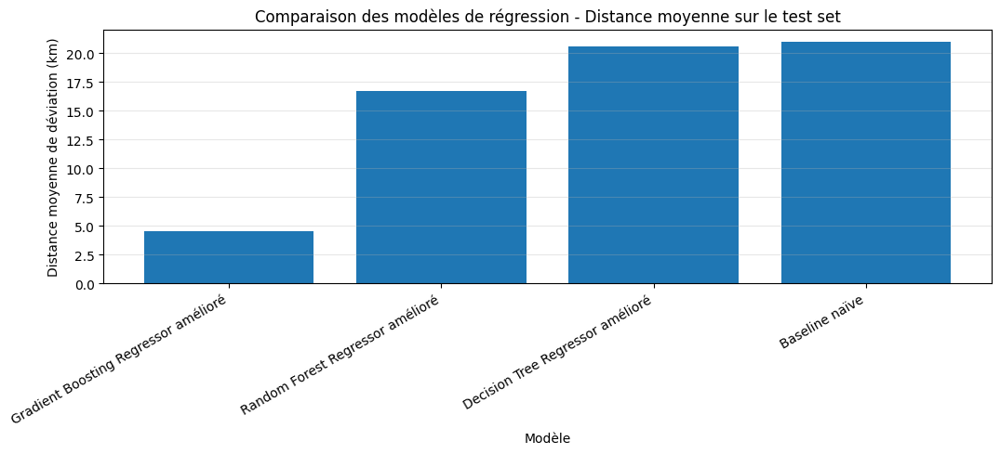

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/regression_mean_deviation_2min.png


In [40]:
# ============================================================
# 15.1. Visualisation : distance moyenne par modèle
# ============================================================

test_results = regression_results_df[regression_results_df["dataset"].fillna("test") == "test"].copy()

test_results_sorted = test_results.sort_values("mean_deviation_km")

plt.figure(figsize=(11, 5))
plt.bar(test_results_sorted["model"], test_results_sorted["mean_deviation_km"])
plt.title("Comparaison des modèles de régression - Distance moyenne sur le test set")
plt.xlabel("Modèle")
plt.ylabel("Distance moyenne de déviation (km)")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

figure_path = FIGURES_DIR / f"regression_mean_deviation_{SELECTED_HORIZON_MIN}min.png"
plt.savefig(figure_path, bbox_inches="tight")
plt.show()

print("Figure sauvegardée :", figure_path)

### 8.2. Visualisation complémentaire : temps d’entraînement et erreur d’altitude

La distance moyenne permet de comparer la précision horizontale des modèles.  
Pour compléter l’analyse, nous visualisons aussi :

- le temps d’entraînement ;
- l’erreur moyenne absolue sur l’altitude.

Ces graphes permettent d’évaluer le compromis entre **performance**, **coût d’entraînement** et **qualité de prédiction verticale**.

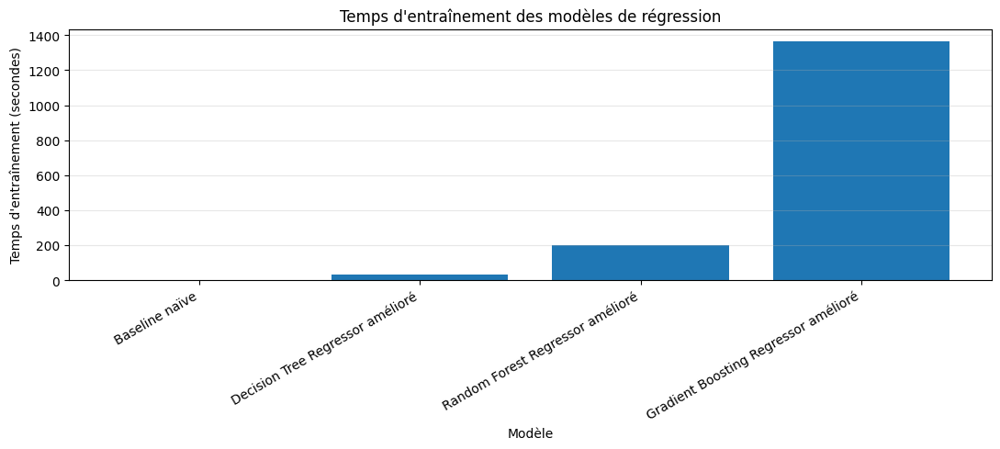

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/regression_training_time_2min.png


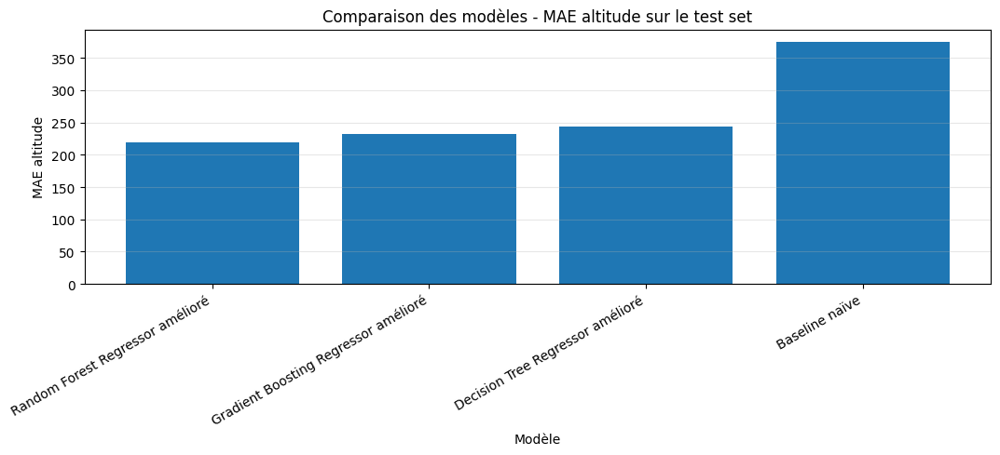

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/regression_mae_altitude_2min.png


In [41]:
# ============================================================
# 8.2. Visualisations complémentaires des modèles de régression
# ============================================================

# On travaille uniquement sur les résultats du test set.
test_results_for_plots = regression_results_df[
    regression_results_df["dataset"].fillna("test") == "test"
].copy()

# Remplacer les temps manquants par 0 pour la baseline.
if "training_time_sec" in test_results_for_plots.columns:
    test_results_for_plots["training_time_sec"] = test_results_for_plots["training_time_sec"].fillna(0)

# 1) Temps d'entraînement
if "training_time_sec" in test_results_for_plots.columns:
    time_sorted = test_results_for_plots.sort_values("training_time_sec")

    plt.figure(figsize=(11, 5))
    plt.bar(time_sorted["model"], time_sorted["training_time_sec"])
    plt.title("Temps d'entraînement des modèles de régression")
    plt.xlabel("Modèle")
    plt.ylabel("Temps d'entraînement (secondes)")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    figure_path = FIGURES_DIR / f"regression_training_time_{SELECTED_HORIZON_MIN}min.png"
    plt.savefig(figure_path, bbox_inches="tight")
    plt.show()

    print("Figure sauvegardée :", figure_path)

# 2) MAE altitude
if "MAE_altitude_future" in test_results_for_plots.columns:
    altitude_sorted = test_results_for_plots.sort_values("MAE_altitude_future")

    plt.figure(figsize=(11, 5))
    plt.bar(altitude_sorted["model"], altitude_sorted["MAE_altitude_future"])
    plt.title("Comparaison des modèles - MAE altitude sur le test set")
    plt.xlabel("Modèle")
    plt.ylabel("MAE altitude")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    figure_path = FIGURES_DIR / f"regression_mae_altitude_{SELECTED_HORIZON_MIN}min.png"
    plt.savefig(figure_path, bbox_inches="tight")
    plt.show()

    print("Figure sauvegardée :", figure_path)

## 9. Visualisation 2D du meilleur modèle de régression

Cette visualisation permet de voir concrètement la différence entre :

- la trajectoire future réelle ;
- la trajectoire future prédite par le meilleur modèle de régression.

Si le fichier `ml_dataset_2min.csv` est disponible, nous récupérons un `trajectory_id` du test set pour afficher une vraie séquence de points.

In [42]:
# ============================================================
# 16.1. Choix automatique du meilleur modèle de régression
# ============================================================

# Dictionnaire des prédictions disponibles sur le test set
prediction_map = {
    "Decision Tree Regressor amélioré": y_test_pred_tree,
    "Random Forest Regressor amélioré": y_test_pred_rf,
    "Gradient Boosting Regressor amélioré": y_test_pred_gb,
}

# Choisir le meilleur modèle selon mean_deviation_km sur test
candidate_results = test_results[test_results["model"].isin(prediction_map.keys())].copy()
best_model_name = candidate_results.sort_values("mean_deviation_km").iloc[0]["model"]
best_y_test_pred = prediction_map[best_model_name].reset_index(drop=True)

print("Meilleur modèle sélectionné pour la visualisation :", best_model_name)

Meilleur modèle sélectionné pour la visualisation : Gradient Boosting Regressor amélioré


In [43]:
# ============================================================
# 16.2. Préparation des métadonnées de test pour visualiser une trajectoire
# ============================================================

ml_dataset_path = PROCESSED_DIR / f"ml_dataset_{SELECTED_HORIZON_MIN}min.csv"

test_metadata = None

if ml_dataset_path.exists():
    df_viz = pd.read_csv(ml_dataset_path, parse_dates=["datetime"])
    df_viz["trajectory_id"] = df_viz["trajectory_id"].astype(str)

    # Recréer le même split par trajectory_id que dans la préparation ML
    unique_trajectories = df_viz["trajectory_id"].unique()
    train_traj, temp_traj = train_test_split(
        unique_trajectories,
        test_size=0.30,
        random_state=42
    )
    val_traj, test_traj = train_test_split(
        temp_traj,
        test_size=0.50,
        random_state=42
    )

    test_metadata = (
        df_viz[df_viz["trajectory_id"].isin(test_traj)]
        .sort_values(["trajectory_id", "datetime"])
        .reset_index(drop=True)
    )

    print("Métadonnées de test chargées :", test_metadata.shape)
else:
    print("Fichier ml_dataset introuvable. La visualisation utilisera les premiers points du test set.")

# Sécurité si les longueurs ne correspondent pas exactement
if test_metadata is not None and len(test_metadata) != len(y_test_reg):
    print("Attention : longueur metadata différente de y_test_reg.")
    print("metadata :", len(test_metadata), "y_test_reg :", len(y_test_reg))
    test_metadata = None

Métadonnées de test chargées : (84061, 52)


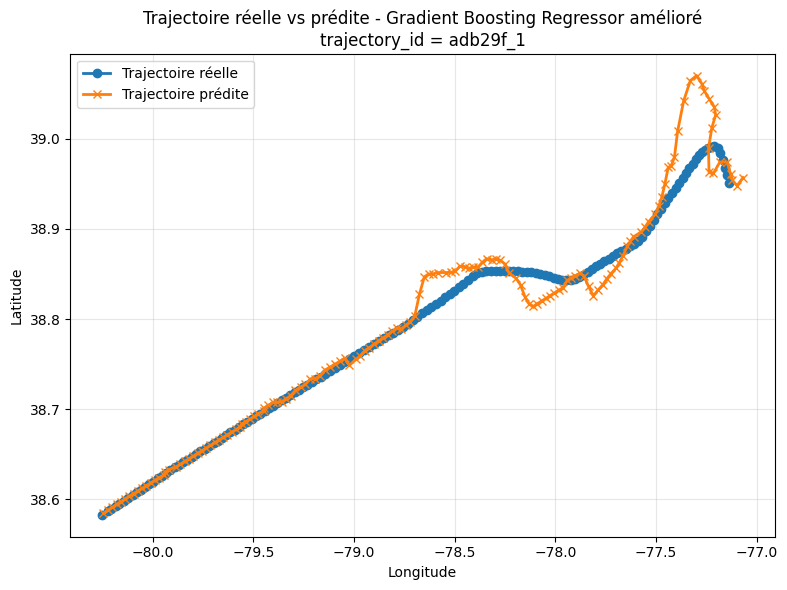

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/trajectory_real_vs_predicted_2min.png


In [44]:
# ============================================================
# 16.3. Graphe trajectoire réelle vs prédite
# ============================================================

if test_metadata is not None:
    # Choisir une trajectoire avec suffisamment de points
    trajectory_counts = test_metadata["trajectory_id"].value_counts()
    selected_trajectory_id = trajectory_counts.index[0]
    selected_idx = test_metadata.index[test_metadata["trajectory_id"] == selected_trajectory_id].to_numpy()
    selected_idx = selected_idx[:min(150, len(selected_idx))]

    title_suffix = f"trajectory_id = {selected_trajectory_id}"
else:
    selected_idx = np.arange(min(150, len(y_test_reg)))
    title_suffix = "premiers points du test set"

real_traj = y_test_reg.reset_index(drop=True).iloc[selected_idx].reset_index(drop=True)
pred_traj = best_y_test_pred.iloc[selected_idx].reset_index(drop=True)

plt.figure(figsize=(8, 6))
plt.plot(real_traj["lon_future"], real_traj["lat_future"], marker="o", linewidth=2, label="Trajectoire réelle")
plt.plot(pred_traj["lon_future"], pred_traj["lat_future"], marker="x", linewidth=2, label="Trajectoire prédite")
plt.title(f"Trajectoire réelle vs prédite - {best_model_name}\n{title_suffix}")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

figure_path = FIGURES_DIR / f"trajectory_real_vs_predicted_{SELECTED_HORIZON_MIN}min.png"
plt.savefig(figure_path, bbox_inches="tight")
plt.show()

print("Figure sauvegardée :", figure_path)

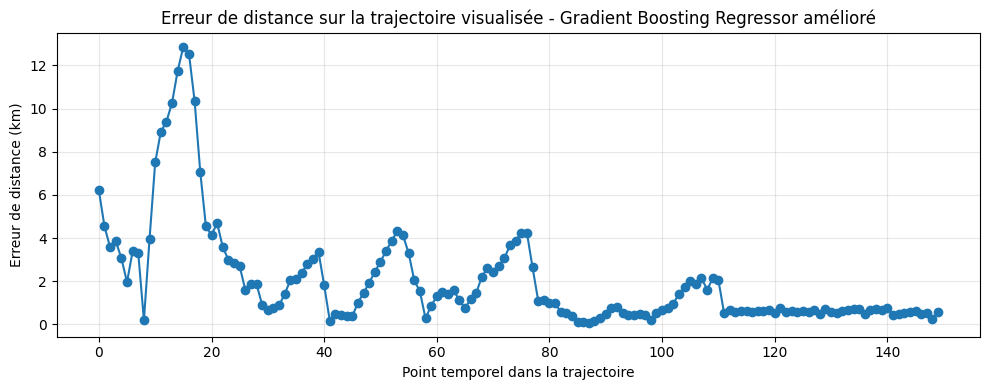

Erreur moyenne sur la trajectoire affichée : 2.052 km
Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/trajectory_error_over_time_2min.png


In [45]:
# ============================================================
# 16.4. Évolution de l'erreur de distance sur la trajectoire visualisée
# ============================================================

trajectory_errors_km = haversine_km(
    real_traj["lat_future"],
    real_traj["lon_future"],
    pred_traj["lat_future"],
    pred_traj["lon_future"]
)

plt.figure(figsize=(10, 4))
plt.plot(trajectory_errors_km, marker="o")
plt.title(f"Erreur de distance sur la trajectoire visualisée - {best_model_name}")
plt.xlabel("Point temporel dans la trajectoire")
plt.ylabel("Erreur de distance (km)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

figure_path = FIGURES_DIR / f"trajectory_error_over_time_{SELECTED_HORIZON_MIN}min.png"
plt.savefig(figure_path, bbox_inches="tight")
plt.show()

print("Erreur moyenne sur la trajectoire affichée :", round(np.mean(trajectory_errors_km), 3), "km")
print("Figure sauvegardée :", figure_path)

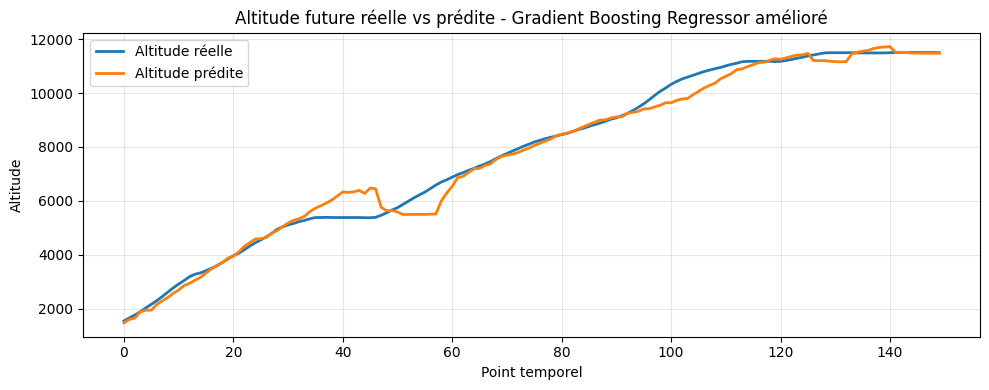

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/altitude_real_vs_predicted_2min.png


In [46]:
# ============================================================
# 16.5. Comparaison de l'altitude réelle vs prédite
# ============================================================

plt.figure(figsize=(10, 4))
plt.plot(real_traj["altitude_future"].values, label="Altitude réelle", linewidth=2)
plt.plot(pred_traj["altitude_future"].values, label="Altitude prédite", linewidth=2)
plt.title(f"Altitude future réelle vs prédite - {best_model_name}")
plt.xlabel("Point temporel")
plt.ylabel("Altitude")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

figure_path = FIGURES_DIR / f"altitude_real_vs_predicted_{SELECTED_HORIZON_MIN}min.png"
plt.savefig(figure_path, bbox_inches="tight")
plt.show()

print("Figure sauvegardée :", figure_path)

## 10. Visualisations 3D et cartographiques du meilleur modèle de régression

Les graphes 2D sont utiles, mais ils ne montrent pas complètement la trajectoire dans l’espace.  
Nous ajoutons donc des visualisations plus professionnelles :

- une trajectoire 3D avec longitude, latitude et altitude ;
- une carte 3D interactive ;
- une carte 3D où les points prédits sont colorés selon l’erreur ;
- une analyse des erreurs extrêmes.

Ces visualisations sont sauvegardées dans le dossier `results/figures` afin d’être utilisées dans le rapport et la présentation.

In [47]:
# ============================================================
# 10.1. Harmonisation des métadonnées pour les visualisations 3D
# ============================================================

# Les cellules précédentes ont pu créer test_metadata à partir de ml_dataset.
# Pour les visualisations 3D, nous utilisons metadata_test.
if "metadata_test" not in globals() and "test_metadata" in globals() and test_metadata is not None:
    metadata_test = test_metadata.reset_index(drop=True).copy()
    print("metadata_test créé à partir de test_metadata :", metadata_test.shape)

# Si un meilleur modèle final existe déjà, on peut l'utiliser.
# Sinon, on garde la prédiction du Gradient Boosting qui est le meilleur modèle initial.
if "best_final_prediction" in globals() and "best_final_model_name" in globals():
    y_test_pred_for_3d = best_final_prediction.copy()
    model_name_for_3d = best_final_model_name
else:
    y_test_pred_for_3d = y_test_pred_gb.copy()
    model_name_for_3d = "Gradient Boosting Regressor amélioré"

print("Modèle utilisé pour les visualisations 3D :", model_name_for_3d)

Modèle utilisé pour les visualisations 3D : Gradient Boosting Regressor amélioré


### 10.2. Préparation du DataFrame de visualisation

Le DataFrame `viz_test_df` rassemble :

- la position actuelle ;
- la position future réelle ;
- la position future prédite ;
- l’erreur de distance entre réel et prédit.

In [48]:
# ============================================================
# Préparation des données pour la visualisation 3D
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# Charger les métadonnées du test set si elles ne sont pas déjà chargées
metadata_test_path = ML_SPLITS_DIR / f"metadata_test_{SELECTED_HORIZON_MIN}min.csv"

if "metadata_test" not in globals():
    if metadata_test_path.exists():
        metadata_test = pd.read_csv(metadata_test_path)
        print("metadata_test chargé :", metadata_test.shape)
    else:
        metadata_test = pd.DataFrame({
            "trajectory_id": ["unknown"] * len(X_test),
            "row_id": np.arange(len(X_test))
        })
        print("metadata_test non trouvé. Création d'un metadata minimal.")

# Vérifier que la prédiction Gradient Boosting existe
if "y_test_pred_gb" not in globals():
    raise NameError(
        "y_test_pred_gb n'existe pas. Exécute d'abord le modèle Gradient Boosting amélioré."
    )

# Créer un DataFrame de visualisation
viz_test_df = metadata_test.reset_index(drop=True).copy()

# Position actuelle
viz_test_df["lat_current"] = X_test["lat"].values
viz_test_df["lon_current"] = X_test["lon"].values
viz_test_df["altitude_current"] = X_test["altitude"].values

# Position future réelle
viz_test_df["lat_true"] = y_test_reg["lat_future"].values
viz_test_df["lon_true"] = y_test_reg["lon_future"].values
viz_test_df["altitude_true"] = y_test_reg["altitude_future"].values

# Position future prédite
viz_test_df["lat_pred"] = y_test_pred_gb["lat_future"].values
viz_test_df["lon_pred"] = y_test_pred_gb["lon_future"].values
viz_test_df["altitude_pred"] = y_test_pred_gb["altitude_future"].values

print("DataFrame de visualisation créé :", viz_test_df.shape)
display(viz_test_df.head())

DataFrame de visualisation créé : (84061, 61)


,datetime,icao24,trajectory_id,lat,lon,altitude,velocity,heading,vertrate,ground_speed_ms,...,intent_future,lat_current,lon_current,altitude_current,lat_true,lon_true,altitude_true,lat_pred,lon_pred,altitude_pred
0,2017-07-03 16:00:40+00:00,00b23c,00b23c_3,-33.980340,18.606434,121.92,80.360370,165.16309,12.67968,80.360370,...,climb,-33.980340,18.606434,121.92,-34.013077,18.692340,1211.58,-34.066637,18.636523,1200.166195
1,2017-07-03 16:00:50+00:00,00b23c,00b23c_3,-33.986763,18.608608,259.08,79.286156,163.79927,14.63040,79.286156,...,climb,-33.986763,18.608608,259.08,-34.007400,18.704168,1363.98,-34.067712,18.638697,1334.316358
2,2017-07-03 16:01:00+00:00,00b23c,00b23c_3,-33.993890,18.611126,411.48,77.805300,163.48220,14.30528,77.805300,...,climb,-33.993890,18.611126,411.48,-34.000305,18.718910,1577.34,-34.069018,18.641215,1503.848416
3,2017-07-03 16:01:10+00:00,00b23c,00b23c_3,-34.000580,18.613531,548.64,76.969150,162.89728,13.32992,76.969150,...,climb,-34.000580,18.613531,548.64,-33.994995,18.730007,1737.36,-34.067926,18.643620,1679.284018
4,2017-07-03 16:01:20+00:00,00b23c,00b23c_3,-34.006550,18.615760,632.46,80.221930,162.84325,6.17728,80.221930,...,climb,-34.006550,18.615760,632.46,-33.987930,18.744678,1973.58,-34.087499,18.645849,1828.878620


In [49]:
# ============================================================
# Calcul de l'erreur de distance pour chaque point
# ============================================================

# On réutilise la fonction haversine_km déjà définie dans le notebook.
# Si elle n'existe pas, on la recrée.

if "haversine_km" not in globals():
    def haversine_km(lat1, lon1, lat2, lon2):
        R = 6371
        lat1 = np.radians(lat1)
        lon1 = np.radians(lon1)
        lat2 = np.radians(lat2)
        lon2 = np.radians(lon2)

        dlat = lat2 - lat1
        dlon = lon2 - lon1

        a = (
            np.sin(dlat / 2) ** 2
            + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
        )
        c = 2 * np.arcsin(np.sqrt(a))
        return R * c

viz_test_df["error_km"] = haversine_km(
    viz_test_df["lat_true"],
    viz_test_df["lon_true"],
    viz_test_df["lat_pred"],
    viz_test_df["lon_pred"]
)

print("Statistiques des erreurs de distance :")
display(viz_test_df["error_km"].describe())

Statistiques des erreurs de distance :


,error_km
count,84061.000000
mean,4.510742
std,13.439534
min,0.003195
25%,1.201718
50%,2.017043
75%,3.980728
max,724.971553


### 10.3. Analyse des erreurs extrêmes

La métrique `max_deviation_km` peut être très élevée à cause de quelques points atypiques.  
Nous ajoutons donc des métriques robustes comme les percentiles P90, P95 et P99, puis nous sauvegardons les points et trajectoires les plus difficiles.

,error_km
0.500,2.017043
0.750,3.980728
0.900,9.174182
0.950,17.088891
0.990,33.489908
0.995,50.643381
0.999,103.136165


Percentiles sauvegardés : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/distance_error_percentiles_2min.csv
Top 20 des erreurs extrêmes :


,trajectory_id,lat_current,lon_current,lat_true,lon_true,lat_pred,lon_pred,altitude_true,altitude_pred,error_km
32117,4951d3_3,43.214172,-2.624455,48.996277,-3.047579,42.482792,-3.460392,11643.36,11632.593104,724.971553
41765,4ca65a_5,42.070908,-3.344151,48.312470,-3.657320,42.054558,-3.299839,11955.78,12020.386056,696.409652
41767,4ca65a_5,42.070908,-3.344151,48.354813,-3.653940,42.129440,-3.358379,11955.78,11130.496759,692.614986
22462,40695b_1,47.634613,-3.694015,47.868454,5.552955,47.868233,-3.678232,10706.10,10508.602723,688.177572
41766,4ca65a_5,42.070908,-3.344151,48.312470,-3.657320,42.129440,-3.358379,11955.78,10683.891481,687.918532
20483,406541_3,50.836075,-3.150107,44.493510,-2.873260,50.597600,-3.168924,11612.88,11594.493104,679.105004
20495,406541_3,44.493510,-2.873260,50.326508,-3.203628,44.347571,-4.047302,11620.50,11521.321368,667.847745
41754,4ca65a_5,47.839280,-3.694359,42.070908,-3.344151,48.071947,-3.678575,11201.40,11994.520560,667.799813
41755,4ca65a_5,47.839280,-3.694359,42.070908,-3.344151,48.071947,-3.674807,11201.40,11871.841368,667.788285
32105,4951d3_3,49.427490,-2.741582,43.214172,-2.624455,49.216949,-2.885775,11643.36,11660.213381,667.779875


Top erreurs sauvegardées : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/top_20_regression_errors_2min.csv
Trajectoires les plus problématiques :


,trajectory_id,n_points,mean_error_km,median_error_km,max_error_km
0,4951d3_3,365,11.319769,2.605881,724.971553
1,4ca65a_5,259,19.827873,1.794487,696.409652
2,40695b_1,851,7.232216,1.976863,688.177572
3,406541_3,589,6.057881,2.166036,679.105004
4,4a35ad_1,1295,12.552629,4.664025,482.242232
5,a8741c_2,418,26.071512,20.409977,463.922521
6,400e5b_3,405,19.973701,8.812091,213.014470
7,43ea15_1,176,18.395670,2.394361,153.736441
8,0a0093_1,692,6.203475,1.536690,113.849238
9,4b1611_2,581,8.758595,2.131243,110.579006


Résumé par trajectoire sauvegardé : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/trajectory_error_summary_2min.csv


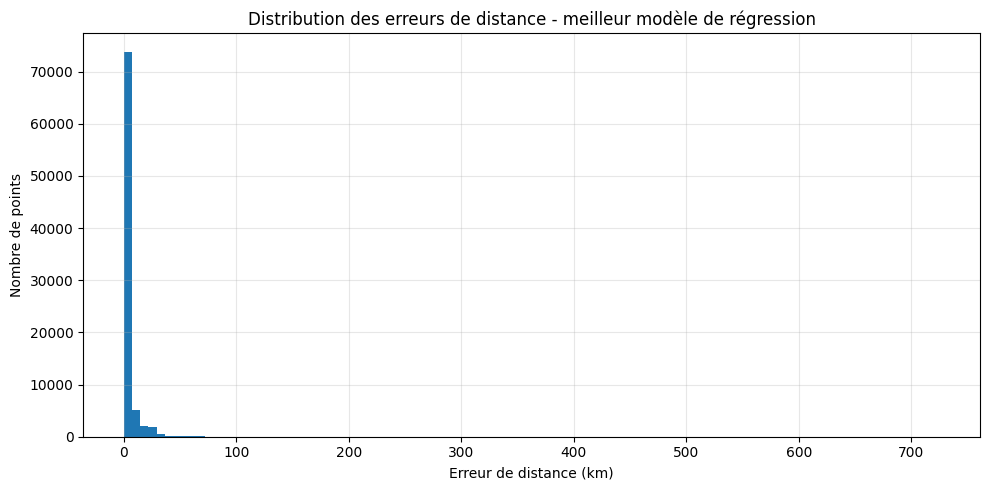

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/distance_error_distribution_2min.png


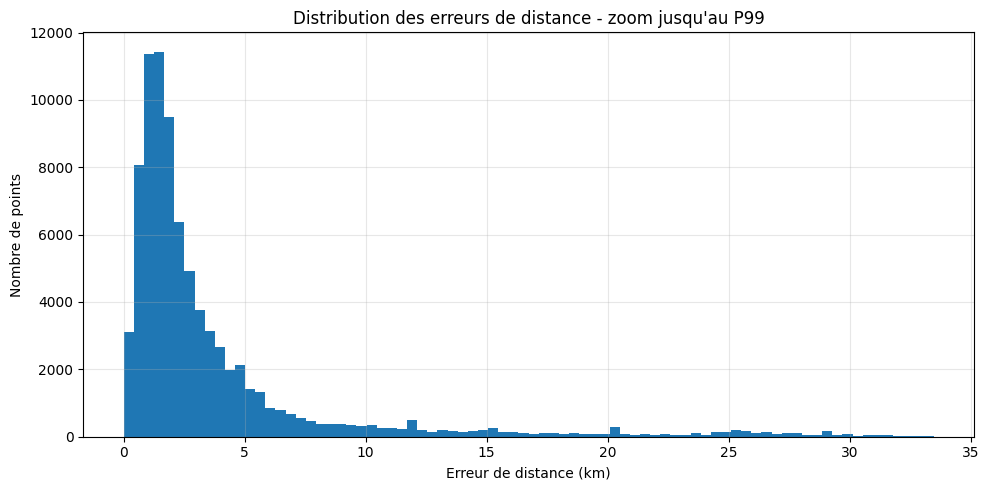

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/distance_error_distribution_zoom_p99_2min.png


In [50]:
# ============================================================
# 10.3. Métriques robustes et erreurs extrêmes
# ============================================================

# Résumé robuste des erreurs de distance
error_percentiles = viz_test_df["error_km"].quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999]).to_frame("error_km")
display(error_percentiles)

error_percentiles_path = METRICS_DIR / f"distance_error_percentiles_{SELECTED_HORIZON_MIN}min.csv"
error_percentiles.to_csv(error_percentiles_path)
print("Percentiles sauvegardés :", error_percentiles_path)

# Top 20 des erreurs
top_errors = viz_test_df.sort_values("error_km", ascending=False).head(20)

top_errors_path = METRICS_DIR / f"top_20_regression_errors_{SELECTED_HORIZON_MIN}min.csv"
top_errors.to_csv(top_errors_path, index=False)

print("Top 20 des erreurs extrêmes :")
display(top_errors[
    [
        "trajectory_id",
        "lat_current", "lon_current",
        "lat_true", "lon_true",
        "lat_pred", "lon_pred",
        "altitude_true", "altitude_pred",
        "error_km"
    ]
])

print("Top erreurs sauvegardées :", top_errors_path)

# Résumé par trajectoire
trajectory_error_summary = (
    viz_test_df
    .groupby("trajectory_id")
    .agg(
        n_points=("error_km", "count"),
        mean_error_km=("error_km", "mean"),
        median_error_km=("error_km", "median"),
        max_error_km=("error_km", "max")
    )
    .sort_values("max_error_km", ascending=False)
    .reset_index()
)

trajectory_error_path = METRICS_DIR / f"trajectory_error_summary_{SELECTED_HORIZON_MIN}min.csv"
trajectory_error_summary.to_csv(trajectory_error_path, index=False)

print("Trajectoires les plus problématiques :")
display(trajectory_error_summary.head(20))
print("Résumé par trajectoire sauvegardé :", trajectory_error_path)

# Distribution des erreurs de distance
plt.figure(figsize=(10, 5))
plt.hist(viz_test_df["error_km"], bins=100)
plt.title("Distribution des erreurs de distance - meilleur modèle de régression")
plt.xlabel("Erreur de distance (km)")
plt.ylabel("Nombre de points")
plt.grid(True, alpha=0.3)
plt.tight_layout()

figure_path = FIGURES_DIR / f"distance_error_distribution_{SELECTED_HORIZON_MIN}min.png"
plt.savefig(figure_path, bbox_inches="tight")
plt.show()

print("Figure sauvegardée :", figure_path)

# Même distribution avec zoom sur les erreurs les plus fréquentes
zoom_threshold = viz_test_df["error_km"].quantile(0.99)

plt.figure(figsize=(10, 5))
plt.hist(viz_test_df.loc[viz_test_df["error_km"] <= zoom_threshold, "error_km"], bins=80)
plt.title("Distribution des erreurs de distance - zoom jusqu'au P99")
plt.xlabel("Erreur de distance (km)")
plt.ylabel("Nombre de points")
plt.grid(True, alpha=0.3)
plt.tight_layout()

figure_path = FIGURES_DIR / f"distance_error_distribution_zoom_p99_{SELECTED_HORIZON_MIN}min.png"
plt.savefig(figure_path, bbox_inches="tight")
plt.show()

print("Figure sauvegardée :", figure_path)

### 10.4. Trajectoire 3D réelle vs prédite

Cette visualisation montre la trajectoire dans un repère 3D :

- axe X : longitude ;
- axe Y : latitude ;
- axe Z : altitude.

In [51]:
# ============================================================
# Visualisation 3D interactive : trajectoire réelle vs prédite
# ============================================================

import plotly.graph_objects as go

# Choisir automatiquement une trajectoire contenant assez de points
trajectory_counts = viz_test_df["trajectory_id"].value_counts()

selected_trajectory_id = trajectory_counts.index[0]

print("Trajectoire sélectionnée :", selected_trajectory_id)
print("Nombre de points :", trajectory_counts.iloc[0])

traj_df = viz_test_df[
    viz_test_df["trajectory_id"] == selected_trajectory_id
].copy()

# Trier par datetime si la colonne existe
if "datetime" in traj_df.columns:
    traj_df["datetime"] = pd.to_datetime(traj_df["datetime"])
    traj_df = traj_df.sort_values("datetime")
else:
    traj_df = traj_df.reset_index(drop=True)

fig = go.Figure()

# Trajectoire réelle
fig.add_trace(go.Scatter3d(
    x=traj_df["lon_true"],
    y=traj_df["lat_true"],
    z=traj_df["altitude_true"],
    mode="lines+markers",
    name="Trajectoire réelle",
    marker=dict(size=3),
    line=dict(width=5)
))

# Trajectoire prédite
fig.add_trace(go.Scatter3d(
    x=traj_df["lon_pred"],
    y=traj_df["lat_pred"],
    z=traj_df["altitude_pred"],
    mode="lines+markers",
    name="Trajectoire prédite",
    marker=dict(size=3),
    line=dict(width=5)
))

fig.update_layout(
    title=f"Trajectoire 3D réelle vs prédite - Gradient Boosting<br>trajectory_id = {selected_trajectory_id}",
    scene=dict(
        xaxis_title="Longitude",
        yaxis_title="Latitude",
        zaxis_title="Altitude"
    ),
    width=900,
    height=700
)

fig.show()

Trajectoire sélectionnée : adb29f_1
Nombre de points : 1484


In [52]:
# ============================================================
# 10.4. Sauvegarde de la trajectoire 3D Plotly en HTML
# ============================================================

plotly_3d_path = FIGURES_DIR / f"trajectory_3d_plotly_{selected_trajectory_id}_{SELECTED_HORIZON_MIN}min.html"
fig.write_html(str(plotly_3d_path))

print("Visualisation 3D Plotly sauvegardée :", plotly_3d_path)

Visualisation 3D Plotly sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/trajectory_3d_plotly_adb29f_1_2min.html


### 10.5. Carte 3D interactive

Cette carte 3D est plus adaptée pour une présentation, car elle montre la trajectoire sur un fond géographique.  
La trajectoire réelle et la trajectoire prédite sont affichées ensemble.

In [53]:
!pip install pydeck -q

In [54]:
import pandas as pd
import numpy as np

# Si tu veux choisir la meilleure ou une trajectoire précise :
# selected_trajectory_id = "adb29f_1"

# Sinon on prend une trajectoire avec assez de points
if "trajectory_id" not in viz_test_df.columns:
    raise ValueError("La colonne 'trajectory_id' n'existe pas dans viz_test_df.")

trajectory_counts = viz_test_df["trajectory_id"].value_counts()
selected_trajectory_id = trajectory_counts.index[0]

traj_df = viz_test_df[viz_test_df["trajectory_id"] == selected_trajectory_id].copy()

# Trier par datetime si disponible
if "datetime" in traj_df.columns:
    traj_df["datetime"] = pd.to_datetime(traj_df["datetime"])
    traj_df = traj_df.sort_values("datetime")
else:
    traj_df = traj_df.reset_index(drop=True)

print("Trajectoire sélectionnée :", selected_trajectory_id)
print("Nombre de points :", len(traj_df))

display(traj_df.head())

Trajectoire sélectionnée : adb29f_1
Nombre de points : 1484


,datetime,icao24,trajectory_id,lat,lon,altitude,velocity,heading,vertrate,ground_speed_ms,...,lat_current,lon_current,altitude_current,lat_true,lon_true,altitude_true,lat_pred,lon_pred,altitude_pred,error_km
75745,2017-07-03 11:28:50+00:00,adb29f,adb29f_1,38.866974,-77.039720,190.50,80.017130,349.62927,18.53184,80.017130,...,38.866974,-77.039720,190.50,38.951004,-77.138490,1539.24,38.957050,-77.067100,1467.810119,6.209674
75746,2017-07-03 11:29:00+00:00,adb29f,adb29f_1,38.874516,-77.043760,335.28,81.252846,331.65012,12.35456,81.252846,...,38.874516,-77.043760,335.28,38.959625,-77.147964,1653.54,38.948033,-77.097593,1597.675161,4.542371
75747,2017-07-03 11:29:10+00:00,adb29f,adb29f_1,38.880660,-77.049255,411.48,87.147790,323.40070,4.87680,87.147790,...,38.880660,-77.049255,411.48,38.967900,-77.157650,1760.22,38.954177,-77.120367,1648.989864,3.566449
75748,2017-07-03 11:29:20+00:00,adb29f,adb29f_1,38.887180,-77.055600,472.44,94.040590,323.00473,7.15264,94.040590,...,38.887180,-77.055600,472.44,38.976746,-77.168390,1882.14,38.960697,-77.128829,1882.392060,3.857714
75749,2017-07-03 11:29:30+00:00,adb29f,adb29f_1,38.894120,-77.062584,541.02,99.660164,319.81573,6.82752,99.660164,...,38.894120,-77.062584,541.02,38.983963,-77.179990,2026.92,38.974231,-77.146806,1941.911170,3.065770


In [55]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    c = 2 * np.arcsin(np.sqrt(a))
    return R * c

if "error_km" not in traj_df.columns:
    traj_df["error_km"] = haversine_km(
        traj_df["lat_true"],
        traj_df["lon_true"],
        traj_df["lat_pred"],
        traj_df["lon_pred"]
    )

display(traj_df[["trajectory_id", "lat_true", "lon_true", "lat_pred", "lon_pred", "error_km"]].head())

,trajectory_id,lat_true,lon_true,lat_pred,lon_pred,error_km
75745,adb29f_1,38.951004,-77.138490,38.957050,-77.067100,6.209674
75746,adb29f_1,38.959625,-77.147964,38.948033,-77.097593,4.542371
75747,adb29f_1,38.967900,-77.157650,38.954177,-77.120367,3.566449
75748,adb29f_1,38.976746,-77.168390,38.960697,-77.128829,3.857714
75749,adb29f_1,38.983963,-77.179990,38.974231,-77.146806,3.065770


In [56]:
import pydeck as pdk

# Construire les chemins 3D [lon, lat, altitude]
real_path = traj_df[["lon_true", "lat_true", "altitude_true"]].values.tolist()
pred_path = traj_df[["lon_pred", "lat_pred", "altitude_pred"]].values.tolist()

path_df = pd.DataFrame({
    "name": ["Trajectoire réelle", "Trajectoire prédite"],
    "path": [real_path, pred_path],
    "color": [[0, 102, 204], [255, 140, 0]]
})

# Vue initiale de la carte
view_state = pdk.ViewState(
    latitude=traj_df["lat_true"].mean(),
    longitude=traj_df["lon_true"].mean(),
    zoom=7,
    pitch=60,
    bearing=20
)

# Layer pour les lignes 3D
path_layer = pdk.Layer(
    "PathLayer",
    data=path_df,
    get_path="path",
    get_color="color",
    width_scale=20,
    width_min_pixels=3,
    pickable=True
)

# Points réels
real_points = traj_df[["lon_true", "lat_true", "altitude_true"]].copy()
real_points["type"] = "réel"

real_scatter_layer = pdk.Layer(
    "ScatterplotLayer",
    data=real_points,
    get_position=["lon_true", "lat_true", "altitude_true"],
    get_radius=2500,
    get_fill_color=[0, 102, 204, 160],
    pickable=True
)

# Points prédits
pred_points = traj_df[["lon_pred", "lat_pred", "altitude_pred", "error_km"]].copy()
pred_points["type"] = "prédit"

pred_scatter_layer = pdk.Layer(
    "ScatterplotLayer",
    data=pred_points,
    get_position=["lon_pred", "lat_pred", "altitude_pred"],
    get_radius=2500,
    get_fill_color=[255, 140, 0, 180],
    pickable=True
)

deck = pdk.Deck(
    layers=[path_layer, real_scatter_layer, pred_scatter_layer],
    initial_view_state=view_state,
    tooltip={
        "html": "<b>Type :</b> {type}<br/><b>Erreur (km) :</b> {error_km}",
        "style": {"backgroundColor": "steelblue", "color": "white"}
    }
)

deck

<IPython.core.display.Javascript object>

{
  "initialViewState": {
    "bearing": 20,
    "latitude": 37.38621886657682,
    "longitude": -93.73600511994609,
    "pitch": 60,
    "zoom": 7
  },
  "layers": [
    {
      "@@type": "PathLayer",
      "data": [
        {
          "color": [
            0,
            102,
            204
          ],
          "name": "Trajectoire r\u00e9elle",
          "path": [
            [
              -77.13849,
              38.951004,
              1539.24
            ],
            [
              -77.147964,
              38.959625,
              1653.54
            ],
            [
              -77.15765,
              38.9679,
              1760.22
            ],
            [
              -77.16839,
              38.976746,
              1882.14
            ],
            [
              -77.17999,
              38.983963,
              2026.92
            ],
            [
              -77.1943,
              38.989426,
              2156.46
            ],
            [
              -77.209404,
              38.991806,
              2293.62
            ],
            [
              -77.22522,
              38.991364,
              2446.02
            ],
            [
              -77.24127,
              38.989735,
              2606.04
            ],
            [
              -77.256226,
              38.98801,
              2766.06
            ],
            [
              -77.27234,
              38.98549,
              2910.84
            ],
            [
              -77.28727,
              38.98201,
              3040.38
            ],
            [
              -77.30273,
              38.977386,
              3185.16
            ],
            [
              -77.317955,
              38.97249,
              3276.6
            ],
            [
              -77.33441,
              38.967064,
              3322.32
            ],
            [
              -77.3504,
              38.961758,
              3406.14
            ],
            [
              -77.36811,
              38.95601,
              3497.58
            ],
            [
              -77.38543,
              38.950653,
              3589.02
            ],
            [
              -77.40289,
              38.945415,
              3710.94
            ],
            [
              -77.42101,
              38.93994,
              3840.48
            ],
            [
              -77.43848,
              38.93443,
              3962.4
            ],
            [
              -77.45709,
              38.928284,
              4053.84
            ],
            [
              -77.475525,
              38.922188,
              4183.38
            ],
            [
              -77.49402,
              38.91609,
              4320.54
            ],
            [
              -77.512245,
              38.910095,
              4442.46
            ],
            [
              -77.53119,
              38.903797,
              4549.14
            ],
            [
              -77.55017,
              38.897514,
              4663.44
            ],
            [
              -77.56969,
              38.891464,
              4785.36
            ],
            [
              -77.58963,
              38.886703,
              4945.38
            ],
            [
              -77.609985,
              38.88327,
              5036.82
            ],
            [
              -77.63047,
              38.88057,
              5105.4
            ],
            [
              -77.65112,
              38.877914,
              5158.74
            ],
            [
              -77.671814,
              38.8754,
              5227.32
            ],
            [
              -77.69197,
              38.87288,
              5273.04
            ],
            [
              -77.71478,
              38.869816,
              5334.0
            ],
            [
              -77.73517,
              38.866974,
              5379.72
            ],
  

In [57]:
# ============================================================
# 10.5. Sauvegarde de la carte 3D interactive
# ============================================================

map_3d_path = FIGURES_DIR / f"trajectory_3d_map_{selected_trajectory_id}_{SELECTED_HORIZON_MIN}min.html"
deck.to_html(str(map_3d_path))

print("Carte 3D sauvegardée :", map_3d_path)

<IPython.core.display.Javascript object>

Carte 3D sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/trajectory_3d_map_adb29f_1_2min.html


### 10.6. Carte 3D colorée selon l’erreur

Dans cette version, les points prédits sont colorés selon l’erreur de distance :

- vert : erreur faible ;
- rouge : erreur élevée.

Cette visualisation permet d’identifier rapidement les segments de trajectoire les plus difficiles à prédire.

In [58]:
# ============================================================
# 10.6. Carte 3D avec prédictions colorées selon l'erreur
# ============================================================

import pydeck as pdk

# Normalisation de l'erreur pour créer une couleur simple vert -> rouge
traj_df = traj_df.copy()
traj_df["error_norm"] = traj_df["error_km"] / max(traj_df["error_km"].max(), 1e-6)
traj_df["r"] = (255 * traj_df["error_norm"]).clip(0, 255).astype(int)
traj_df["g"] = (255 * (1 - traj_df["error_norm"])).clip(0, 255).astype(int)
traj_df["b"] = 60

# Ligne réelle
real_path = traj_df[["lon_true", "lat_true", "altitude_true"]].values.tolist()
real_line_layer = pdk.Layer(
    "PathLayer",
    data=pd.DataFrame({
        "name": ["Trajectoire réelle"],
        "path": [real_path],
        "color": [[0, 102, 204]]
    }),
    get_path="path",
    get_color="color",
    width_scale=20,
    width_min_pixels=4,
    pickable=True
)

# Points prédits colorés par erreur
error_layer = pdk.Layer(
    "ScatterplotLayer",
    data=traj_df,
    get_position=["lon_pred", "lat_pred", "altitude_pred"],
    get_radius=3500,
    get_fill_color=["r", "g", "b", 180],
    pickable=True
)

deck_error = pdk.Deck(
    layers=[real_line_layer, error_layer],
    initial_view_state=view_state,
    tooltip={
        "html": "<b>Erreur :</b> {error_km} km<br/><b>Lat réelle :</b> {lat_true}<br/><b>Lon réelle :</b> {lon_true}<br/><b>Lat prédite :</b> {lat_pred}<br/><b>Lon prédite :</b> {lon_pred}",
        "style": {"backgroundColor": "darkred", "color": "white"}
    }
)

deck_error

<IPython.core.display.Javascript object>

{
  "initialViewState": {
    "bearing": 20,
    "latitude": 37.38621886657682,
    "longitude": -93.73600511994609,
    "pitch": 60,
    "zoom": 7
  },
  "layers": [
    {
      "@@type": "PathLayer",
      "data": [
        {
          "color": [
            0,
            102,
            204
          ],
          "name": "Trajectoire r\u00e9elle",
          "path": [
            [
              -77.13849,
              38.951004,
              1539.24
            ],
            [
              -77.147964,
              38.959625,
              1653.54
            ],
            [
              -77.15765,
              38.9679,
              1760.22
            ],
            [
              -77.16839,
              38.976746,
              1882.14
            ],
            [
              -77.17999,
              38.983963,
              2026.92
            ],
            [
              -77.1943,
              38.989426,
              2156.46
            ],
            [
              -77.209404,
              38.991806,
              2293.62
            ],
            [
              -77.22522,
              38.991364,
              2446.02
            ],
            [
              -77.24127,
              38.989735,
              2606.04
            ],
            [
              -77.256226,
              38.98801,
              2766.06
            ],
            [
              -77.27234,
              38.98549,
              2910.84
            ],
            [
              -77.28727,
              38.98201,
              3040.38
            ],
            [
              -77.30273,
              38.977386,
              3185.16
            ],
            [
              -77.317955,
              38.97249,
              3276.6
            ],
            [
              -77.33441,
              38.967064,
              3322.32
            ],
            [
              -77.3504,
              38.961758,
              3406.14
            ],
            [
              -77.36811,
              38.95601,
              3497.58
            ],
            [
              -77.38543,
              38.950653,
              3589.02
            ],
            [
              -77.40289,
              38.945415,
              3710.94
            ],
            [
              -77.42101,
              38.93994,
              3840.48
            ],
            [
              -77.43848,
              38.93443,
              3962.4
            ],
            [
              -77.45709,
              38.928284,
              4053.84
            ],
            [
              -77.475525,
              38.922188,
              4183.38
            ],
            [
              -77.49402,
              38.91609,
              4320.54
            ],
            [
              -77.512245,
              38.910095,
              4442.46
            ],
            [
              -77.53119,
              38.903797,
              4549.14
            ],
            [
              -77.55017,
              38.897514,
              4663.44
            ],
            [
              -77.56969,
              38.891464,
              4785.36
            ],
            [
              -77.58963,
              38.886703,
              4945.38
            ],
            [
              -77.609985,
              38.88327,
              5036.82
            ],
            [
              -77.63047,
              38.88057,
              5105.4
            ],
            [
              -77.65112,
              38.877914,
              5158.74
            ],
            [
              -77.671814,
              38.8754,
              5227.32
            ],
            [
              -77.69197,
              38.87288,
              5273.04
            ],
            [
              -77.71478,
              38.869816,
              5334.0
            ],
            [
              -77.73517,
              38.866974,
              5379.72
            ],
  

In [59]:
# ============================================================
# 10.6. Sauvegarde de la carte 3D colorée par erreur
# ============================================================

map_3d_error_path = FIGURES_DIR / f"trajectory_3d_error_map_{selected_trajectory_id}_{SELECTED_HORIZON_MIN}min.html"
deck_error.to_html(str(map_3d_error_path))

print("Carte 3D avec erreurs sauvegardée :", map_3d_error_path)

<IPython.core.display.Javascript object>

Carte 3D avec erreurs sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/trajectory_3d_error_map_adb29f_1_2min.html


### 10.7. Carte 3D de la trajectoire la plus problématique

Pour comprendre les erreurs extrêmes, nous visualisons aussi la trajectoire ayant la plus grande erreur maximale.

In [60]:
# ============================================================
# 10.7. Visualisation 3D de la trajectoire la plus problématique
# ============================================================

if "trajectory_error_summary" not in globals():
    raise NameError("trajectory_error_summary n'existe pas. Exécute la cellule d'analyse des erreurs extrêmes.")

worst_trajectory_id = trajectory_error_summary.iloc[0]["trajectory_id"]
worst_traj_df = viz_test_df[viz_test_df["trajectory_id"] == worst_trajectory_id].copy()

if "datetime" in worst_traj_df.columns:
    worst_traj_df["datetime"] = pd.to_datetime(worst_traj_df["datetime"])
    worst_traj_df = worst_traj_df.sort_values("datetime")
else:
    worst_traj_df = worst_traj_df.reset_index(drop=True)

print("Trajectoire la plus problématique :", worst_trajectory_id)
print("Nombre de points :", len(worst_traj_df))
print("Erreur maximale :", worst_traj_df["error_km"].max(), "km")

# Couleur selon erreur
worst_traj_df["error_norm"] = worst_traj_df["error_km"] / max(worst_traj_df["error_km"].max(), 1e-6)
worst_traj_df["r"] = (255 * worst_traj_df["error_norm"]).clip(0, 255).astype(int)
worst_traj_df["g"] = (255 * (1 - worst_traj_df["error_norm"])).clip(0, 255).astype(int)
worst_traj_df["b"] = 60

worst_real_path = worst_traj_df[["lon_true", "lat_true", "altitude_true"]].values.tolist()

worst_view_state = pdk.ViewState(
    latitude=worst_traj_df["lat_true"].mean(),
    longitude=worst_traj_df["lon_true"].mean(),
    zoom=7,
    pitch=60,
    bearing=20
)

worst_real_layer = pdk.Layer(
    "PathLayer",
    data=pd.DataFrame({
        "name": ["Trajectoire réelle"],
        "path": [worst_real_path],
        "color": [[0, 102, 204]]
    }),
    get_path="path",
    get_color="color",
    width_scale=20,
    width_min_pixels=4,
    pickable=True
)

worst_error_layer = pdk.Layer(
    "ScatterplotLayer",
    data=worst_traj_df,
    get_position=["lon_pred", "lat_pred", "altitude_pred"],
    get_radius=3500,
    get_fill_color=["r", "g", "b", 180],
    pickable=True
)

deck_worst = pdk.Deck(
    layers=[worst_real_layer, worst_error_layer],
    initial_view_state=worst_view_state,
    tooltip={
        "html": "<b>Erreur :</b> {error_km} km<br/><b>trajectory_id :</b> {trajectory_id}<br/><b>Lat réelle :</b> {lat_true}<br/><b>Lon réelle :</b> {lon_true}<br/><b>Lat prédite :</b> {lat_pred}<br/><b>Lon prédite :</b> {lon_pred}",
        "style": {"backgroundColor": "darkred", "color": "white"}
    }
)

deck_worst

Trajectoire la plus problématique : 4951d3_3
Nombre de points : 365
Erreur maximale : 724.971552738303 km


<IPython.core.display.Javascript object>

{
  "initialViewState": {
    "bearing": 20,
    "latitude": 48.61292125479452,
    "longitude": -3.156855015123287,
    "pitch": 60,
    "zoom": 7
  },
  "layers": [
    {
      "@@type": "PathLayer",
      "data": [
        {
          "color": [
            0,
            102,
            204
          ],
          "name": "Trajectoire r\u00e9elle",
          "path": [
            [
              -0.64477867,
              51.459595,
              1249.68
            ],
            [
              -0.66223145,
              51.458237,
              1325.88
            ],
            [
              -0.68092966,
              51.45877,
              1440.18
            ],
            [
              -0.69885254,
              51.458565,
              1531.62
            ],
            [
              -0.71784973,
              51.457726,
              1630.68
            ],
            [
              -0.736084,
              51.456802,
              1691.64
            ],
            [
              -0.7546234,
              51.455257,
              1767.84
            ],
            [
              -0.772171,
              51.450836,
              1851.66
            ],
            [
              -0.7865906,
              51.44325,
              1905.0
            ],
            [
              -0.7987213,
              51.433517,
              1965.96
            ],
            [
              -0.8103902,
              51.423294,
              2019.3
            ],
            [
              -0.8219147,
              51.413177,
              2095.5
            ],
            [
              -0.83332783,
              51.403152,
              2225.04
            ],
            [
              -0.84513074,
              51.392807,
              2377.44
            ],
            [
              -0.8565521,
              51.382824,
              2468.88
            ],
            [
              -0.8682169,
              51.372757,
              2529.84
            ],
            [
              -0.8801682,
              51.362503,
              2606.04
            ],
            [
              -0.8922577,
              51.35196,
              2697.48
            ],
            [
              -0.90407085,
              51.341675,
              2781.3
            ],
            [
              -0.91609645,
              51.331192,
              2872.74
            ],
            [
              -0.9272766,
              51.320396,
              2941.32
            ],
            [
              -0.9360504,
              51.308434,
              2994.66
            ],
            [
              -0.94337463,
              51.295444,
              3040.38
            ],
            [
              -0.94979775,
              51.28299,
              3124.2
            ],
            [
              -0.9561075,
              51.27031,
              3238.5
            ],
            [
              -0.9626007,
              51.25704,
              3322.32
            ],
            [
              -0.9693146,
              51.2434,
              3383.28
            ],
            [
              -0.97709656,
              51.229202,
              3436.62
            ],
            [
              -0.9870148,
              51.215096,
              3489.96
            ],
            [
              -0.99845886,
              51.201084,
              3550.92
            ],
            [
              -1.0098515,
              51.187683,
              3657.6
            ],
            [
              -1.0222481,
              51.173355,
              3710.94
            ],
            [
              -1.0352387,
              51.158432,
              3764.28
            ],
            [
              -1.0484314,
              51.143406,
              3840.48
            ],
            [
              -1.0616302,
              51.128277,
              3970.02
            ],
            [
              -1.0752498,
              51.11

In [61]:
# ============================================================
# 10.7. Sauvegarde de la carte de la trajectoire la plus problématique
# ============================================================

worst_map_path = FIGURES_DIR / f"worst_trajectory_3d_error_map_{worst_trajectory_id}_{SELECTED_HORIZON_MIN}min.html"
deck_worst.to_html(str(worst_map_path))

print("Carte de la trajectoire problématique sauvegardée :", worst_map_path)

<IPython.core.display.Javascript object>

Carte de la trajectoire problématique sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/worst_trajectory_3d_error_map_4951d3_3_2min.html


## 11. Optimisation du Random Forest avec Optuna

Le projet demande une recherche d’hyperparamètres avec `GridSearchCV` ou `Optuna`.

Ici, nous utilisons **Optuna** pour optimiser le Random Forest.

Le tuning est effectué sur une version échantillonnée pour réduire le temps de calcul. La métrique optimisée est la distance moyenne de déviation sur validation.

In [62]:
# ============================================================
# 17.1. Installation et import d'Optuna
# ============================================================

import sys
import subprocess

try:
    import optuna
except ImportError:
    print("Optuna n'est pas installé. Installation en cours...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna", "-q"])
    import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
print("Optuna prêt.")

Optuna prêt.


In [63]:
# ============================================================
# 17.2. Préparation d'échantillons pour accélérer Optuna
# ============================================================

OPTUNA_TRAIN_SAMPLE = 50000
OPTUNA_VAL_SAMPLE = 20000

rng = np.random.default_rng(seed=42)

train_size = min(OPTUNA_TRAIN_SAMPLE, X_train_scaled.shape[0])
val_size = min(OPTUNA_VAL_SAMPLE, X_val_scaled.shape[0])

train_indices = rng.choice(X_train_scaled.shape[0], size=train_size, replace=False)
val_indices = rng.choice(X_val_scaled.shape[0], size=val_size, replace=False)

X_train_optuna = X_train_scaled[train_indices]
y_train_delta_optuna = y_train_delta.iloc[train_indices].reset_index(drop=True)

X_val_optuna = X_val_scaled[val_indices]
X_val_raw_optuna = X_val.iloc[val_indices].reset_index(drop=True)
y_val_reg_optuna = y_val_reg.iloc[val_indices].reset_index(drop=True)

print("Échantillons Optuna préparés.")
print("Train Optuna :", X_train_optuna.shape)
print("Validation Optuna :", X_val_optuna.shape)

Échantillons Optuna préparés.
Train Optuna : (50000, 32)
Validation Optuna : (20000, 32)


In [64]:
# ============================================================
# 17.3. Fonction objectif Optuna pour Random Forest delta
# ============================================================

def objective_rf_delta(trial):
    """Objectif Optuna : minimiser la distance moyenne de déviation sur validation."""

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 40, 120),
        "max_depth": trial.suggest_int("max_depth", 8, 25),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 5, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", None])
    }

    model = RandomForestRegressor(
        **params,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_optuna, y_train_delta_optuna)

    y_val_delta_pred = model.predict(X_val_optuna)
    y_val_pred = reconstruct_future_position(X_val_raw_optuna, y_val_delta_pred)

    distances = haversine_km(
        y_val_reg_optuna["lat_future"],
        y_val_reg_optuna["lon_future"],
        y_val_pred["lat_future"],
        y_val_pred["lon_future"]
    )

    return float(np.mean(distances))

N_TRIALS = 10
study = optuna.create_study(direction="minimize")
study.optimize(objective_rf_delta, n_trials=N_TRIALS)

print("Tuning terminé.")
print("Nombre d'essais :", N_TRIALS)
print("Meilleurs paramètres :")
print(study.best_params)
print("Meilleure distance moyenne validation :", study.best_value, "km")

Tuning terminé.
Nombre d'essais : 10
Meilleurs paramètres :
{'n_estimators': 40, 'max_depth': 23, 'min_samples_leaf': 18, 'min_samples_split': 19, 'max_features': 'log2'}
Meilleure distance moyenne validation : 15.430655551385781 km


## 12. Réentraînement du Random Forest optimisé

Après le tuning, nous réentraînons le Random Forest optimisé sur tout le train, puis nous l’évaluons sur validation et test.

In [65]:
# ============================================================
# 18. Random Forest optimisé avec les meilleurs paramètres Optuna
# ============================================================

best_rf = RandomForestRegressor(
    **study.best_params,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

best_rf.fit(X_train_scaled, y_train_delta)

training_time_best_rf = time.time() - start_time
print(f"Entraînement Random Forest optimisé terminé en {training_time_best_rf:.2f} secondes.")

# Prédiction des deltas
y_val_delta_pred_best_rf = best_rf.predict(X_val_scaled)
y_test_delta_pred_best_rf = best_rf.predict(X_test_scaled)

# Reconstruction des positions futures
y_val_pred_best_rf = reconstruct_future_position(X_val, y_val_delta_pred_best_rf)
y_test_pred_best_rf = reconstruct_future_position(X_test, y_test_delta_pred_best_rf)

best_rf_results_df = pd.DataFrame([
    evaluate_regression_model("Random Forest optimisé", "validation", y_val_reg, y_val_pred_best_rf, training_time_best_rf),
    evaluate_regression_model("Random Forest optimisé", "test", y_test_reg, y_test_pred_best_rf, training_time_best_rf)
])

display(best_rf_results_df)

Entraînement Random Forest optimisé terminé en 128.25 secondes.


,model,dataset,RMSE_lat_future,MAE_lat_future,RMSE_lon_future,MAE_lon_future,RMSE_altitude_future,MAE_altitude_future,mean_deviation_km,median_deviation_km,max_deviation_km,training_time_sec
0,Random Forest optimisé,validation,0.114967,0.075769,0.265667,0.134278,731.070027,223.331564,14.742540,14.537859,727.447010,128.252488
1,Random Forest optimisé,test,0.131651,0.080403,0.177250,0.113590,706.832172,218.785585,14.193961,14.242161,695.076006,128.252488


## 13. Analyse des résidus du meilleur modèle de régression

L’analyse des résidus permet de comprendre où le modèle se trompe.

Un résidu est calculé comme suit :

```text
résidu = valeur réelle - valeur prédite
```

Nous utilisons ici le meilleur modèle sur le test set selon `mean_deviation_km`.

In [66]:
# ============================================================
# 19.1. Choisir automatiquement le meilleur modèle final
# ============================================================

# Ajouter le modèle optimisé à la comparaison
final_regression_results = pd.concat(
    [regression_results_df, best_rf_results_df],
    ignore_index=True
)

# Dictionnaire des prédictions disponibles
prediction_map_final = {
    "Decision Tree Regressor amélioré": y_test_pred_tree,
    "Random Forest Regressor amélioré": y_test_pred_rf,
    "Gradient Boosting Regressor amélioré": y_test_pred_gb,
    "Random Forest optimisé": y_test_pred_best_rf,
}

test_final = final_regression_results[
    final_regression_results["dataset"].fillna("test") == "test"
].copy()

# Ne garder que les modèles qui ont des prédictions disponibles
available_test_final = test_final[test_final["model"].isin(prediction_map_final.keys())]

best_final_model_name = available_test_final.sort_values("mean_deviation_km").iloc[0]["model"]
best_final_prediction = prediction_map_final[best_final_model_name].reset_index(drop=True)

print("Meilleur modèle final pour l'analyse des résidus :", best_final_model_name)

Meilleur modèle final pour l'analyse des résidus : Gradient Boosting Regressor amélioré


In [67]:
# ============================================================
# 19.2. Résidus et statistiques descriptives
# ============================================================

residuals = y_test_reg.reset_index(drop=True) - best_final_prediction

print("Statistiques des résidus :")
display(residuals.describe())

# Sauvegarde des résidus
residuals_path = METRICS_DIR / f"residuals_best_regression_model_{SELECTED_HORIZON_MIN}min.csv"
residuals.to_csv(residuals_path, index=False)
print("Résidus sauvegardés :", residuals_path)

Statistiques des résidus :


,lat_future,lon_future,altitude_future
count,84061.000000,84061.000000,84061.000000
mean,0.000305,-0.000851,-0.581033
std,0.095894,0.120479,723.077128
min,-6.104090,-8.979608,-14670.218406
25%,-0.008734,-0.017383,-51.080199
50%,0.001539,-0.000041,10.766896
75%,0.010453,0.014971,91.558632
max,6.513485,9.231187,15576.793000


Résidus sauvegardés : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/residuals_best_regression_model_2min.csv


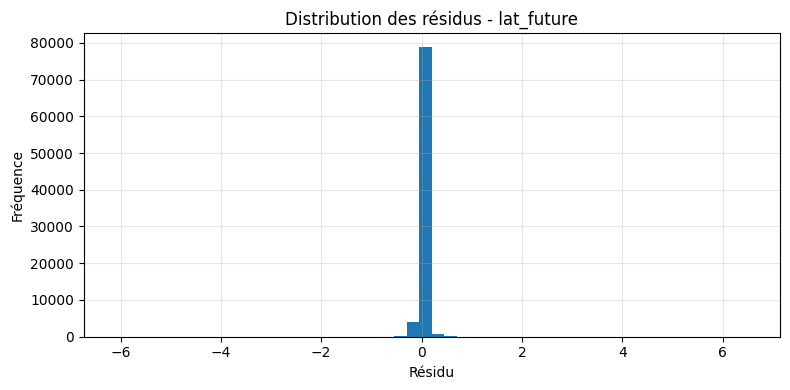

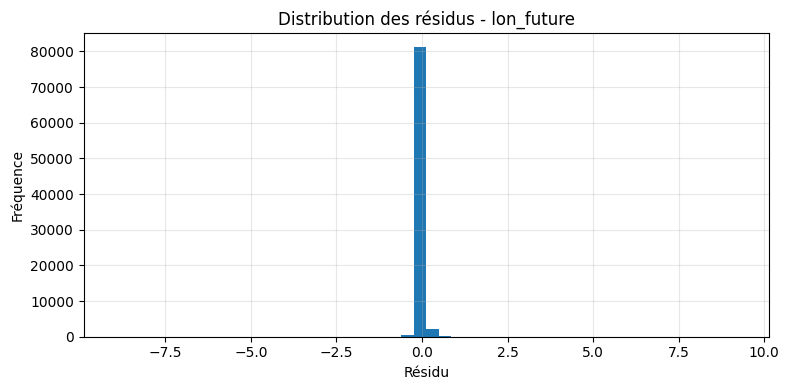

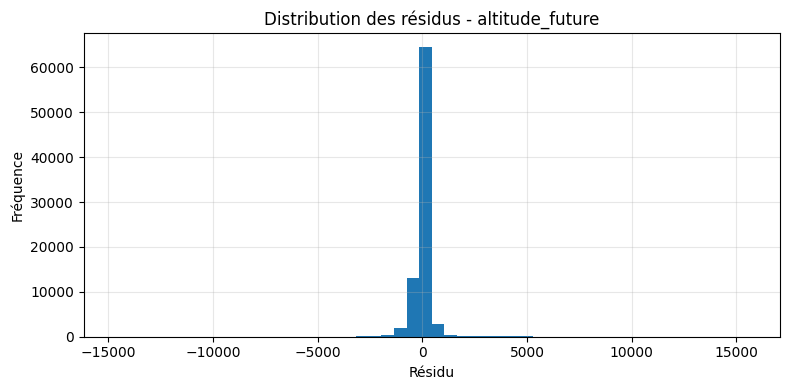

Histogrammes des résidus sauvegardés dans : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures


In [68]:
# ============================================================
# 19.3. Visualisation des résidus
# ============================================================

for col in residuals.columns:
    plt.figure(figsize=(8, 4))
    plt.hist(residuals[col], bins=50)
    plt.title(f"Distribution des résidus - {col}")
    plt.xlabel("Résidu")
    plt.ylabel("Fréquence")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    figure_path = FIGURES_DIR / f"residuals_{col}_{SELECTED_HORIZON_MIN}min.png"
    plt.savefig(figure_path, bbox_inches="tight")
    plt.show()

print("Histogrammes des résidus sauvegardés dans :", FIGURES_DIR)

## 14. PCA uniquement pour le SVM RBF

La PCA est appliquée uniquement pour la classification SVM RBF.

Pourquoi ?

- Le SVM RBF est sensible à la dimension et aux distances.
- La PCA permet de réduire la dimension tout en conservant 95 % de la variance.
- Les modèles d’arbres utilisés en régression sont gardés sans PCA, car ils exploitent mieux les variables originales.

In [69]:
# ============================================================
# 20. PCA pour SVM uniquement
# ============================================================

pca_svm = PCA(n_components=0.95, random_state=42)

# Fit uniquement sur train, puis transform sur validation et test
X_train_pca_svm = pca_svm.fit_transform(X_train_scaled)
X_val_pca_svm = pca_svm.transform(X_val_scaled)
X_test_pca_svm = pca_svm.transform(X_test_scaled)

print("PCA pour SVM terminée.")
print("Features avant PCA      :", X_train_scaled.shape[1])
print("Composantes après PCA   :", pca_svm.n_components_)
print("Variance conservée      :", round(pca_svm.explained_variance_ratio_.sum(), 4))
print("X_train_pca_svm shape   :", X_train_pca_svm.shape)
print("X_val_pca_svm shape     :", X_val_pca_svm.shape)
print("X_test_pca_svm shape    :", X_test_pca_svm.shape)

PCA pour SVM terminée.
Features avant PCA      : 32
Composantes après PCA   : 19
Variance conservée      : 0.9628
X_train_pca_svm shape   : (396485, 19)
X_val_pca_svm shape     : (89838, 19)
X_test_pca_svm shape    : (84061, 19)


## 15. Préparation de la classification d’intention

La target de classification est `intent_future`.

Nous utilisons `LabelEncoder` pour transformer les classes textuelles en valeurs numériques.

In [70]:
# ============================================================
# 21. Encodage des classes
# ============================================================

label_encoder = LabelEncoder()

# Convertir en string pour éviter les problèmes de type
y_train_clf_str = y_train_clf.astype(str)
y_val_clf_str = y_val_clf.astype(str)
y_test_clf_str = y_test_clf.astype(str)

# Fit uniquement sur train
y_train_clf_encoded = label_encoder.fit_transform(y_train_clf_str)
y_val_clf_encoded = label_encoder.transform(y_val_clf_str)
y_test_clf_encoded = label_encoder.transform(y_test_clf_str)

classes_df = pd.DataFrame({
    "code": range(len(label_encoder.classes_)),
    "classe": label_encoder.classes_
})

display(classes_df)

# Distribution des classes
class_distribution = pd.DataFrame({
    "train": pd.Series(y_train_clf_str).value_counts(),
    "validation": pd.Series(y_val_clf_str).value_counts(),
    "test": pd.Series(y_test_clf_str).value_counts()
}).fillna(0).astype(int)

display(class_distribution)

,code,classe
0,0,climb
1,1,cruise
2,2,descent
3,3,turn


,train,validation,test
intent_future,,,
cruise,252314,56749,54546
descent,82867,19493,16908
climb,59662,13304,12122
turn,1642,292,485


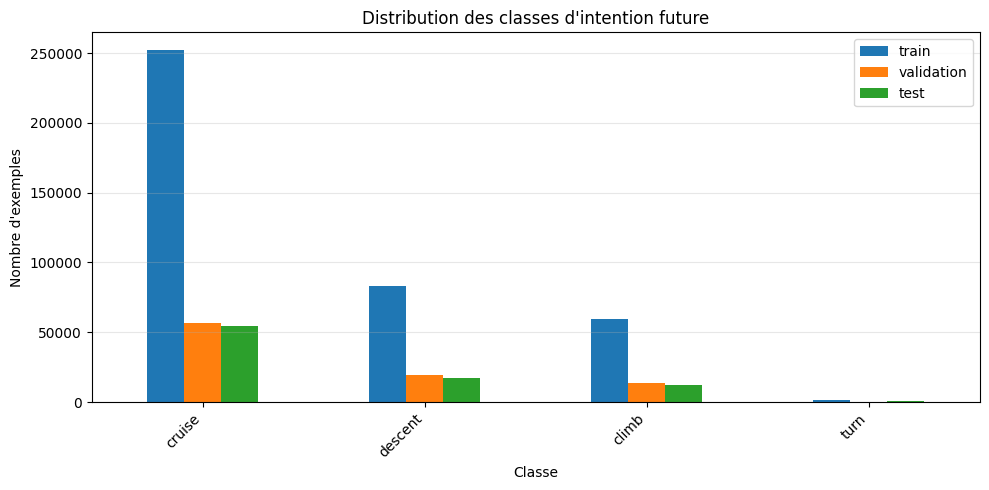

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/intention_class_distribution_2min.png


In [71]:
# ============================================================
# 21.1. Visualisation de la distribution des intentions
# ============================================================

class_distribution.plot(kind="bar", figsize=(10, 5))
plt.title("Distribution des classes d'intention future")
plt.xlabel("Classe")
plt.ylabel("Nombre d'exemples")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

figure_path = FIGURES_DIR / f"intention_class_distribution_{SELECTED_HORIZON_MIN}min.png"
plt.savefig(figure_path, bbox_inches="tight")
plt.show()

print("Figure sauvegardée :", figure_path)

## 16. SVM RBF pour la classification d’intention

Le SVM avec kernel RBF est utilisé pour prédire l’intention future de l’avion.

Pour limiter le temps d’entraînement, nous utilisons un échantillon stratifié du train si le dataset est très grand.

In [72]:
# ============================================================
# 22.1. Échantillonnage pour accélérer SVM
# ============================================================

USE_SAMPLE_FOR_SVM = True
SVM_SAMPLE_SIZE = 30000

if USE_SAMPLE_FOR_SVM and X_train_pca_svm.shape[0] > SVM_SAMPLE_SIZE:
    try:
        X_train_svm, _, y_train_svm, _ = train_test_split(
            X_train_pca_svm,
            y_train_clf_encoded,
            train_size=SVM_SAMPLE_SIZE,
            random_state=42,
            stratify=y_train_clf_encoded
        )
        print("Échantillon stratifié utilisé pour SVM.")
    except ValueError:
        rng = np.random.default_rng(seed=42)
        sample_indices = rng.choice(
            X_train_pca_svm.shape[0],
            size=SVM_SAMPLE_SIZE,
            replace=False
        )
        X_train_svm = X_train_pca_svm[sample_indices]
        y_train_svm = y_train_clf_encoded[sample_indices]
        print("Échantillon aléatoire utilisé pour SVM.")
else:
    X_train_svm = X_train_pca_svm
    y_train_svm = y_train_clf_encoded
    print("Tout le train est utilisé pour SVM.")

print("Taille utilisée pour SVM :", X_train_svm.shape)

Échantillon stratifié utilisé pour SVM.
Taille utilisée pour SVM : (30000, 19)


In [73]:
# ============================================================
# 22.2. Entraînement SVM RBF
# ============================================================

svm_rbf = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    class_weight="balanced",
    random_state=42
)

start_time = time.time()
svm_rbf.fit(X_train_svm, y_train_svm)
training_time_svm = time.time() - start_time

print(f"Entraînement SVM terminé en {training_time_svm:.2f} secondes.")

Entraînement SVM terminé en 32.53 secondes.


## 17. Évaluation de la classification

Nous évaluons le SVM avec :

- **Accuracy** : pourcentage de bonnes prédictions ;
- **F1 macro** : moyenne simple du F1-score de chaque classe ;
- **F1 weighted** : F1-score pondéré par le nombre d’exemples de chaque classe ;
- **matrice de confusion** : visualisation des confusions entre classes.

In [74]:
# ============================================================
# 23.1. Accuracy, F1-score et rapport de classification
# ============================================================

# Prédictions validation et test
y_val_pred_svm = svm_rbf.predict(X_val_pca_svm)
y_test_pred_svm = svm_rbf.predict(X_test_pca_svm)

classification_results = pd.DataFrame({
    "model": ["SVM RBF avec PCA", "SVM RBF avec PCA"],
    "dataset": ["validation", "test"],
    "accuracy": [
        accuracy_score(y_val_clf_encoded, y_val_pred_svm),
        accuracy_score(y_test_clf_encoded, y_test_pred_svm)
    ],
    "f1_macro": [
        f1_score(y_val_clf_encoded, y_val_pred_svm, average="macro"),
        f1_score(y_test_clf_encoded, y_test_pred_svm, average="macro")
    ],
    "f1_weighted": [
        f1_score(y_val_clf_encoded, y_val_pred_svm, average="weighted"),
        f1_score(y_test_clf_encoded, y_test_pred_svm, average="weighted")
    ],
    "training_time_sec": [training_time_svm, training_time_svm]
})

display(classification_results)

print("Rapport de classification sur le test set :")
print("-------------------------------------------")
print(
    classification_report(
        y_test_clf_encoded,
        y_test_pred_svm,
        target_names=label_encoder.classes_
    )
)

# Sauvegarde des résultats
classification_results_path = METRICS_DIR / f"svm_rbf_classification_results_{SELECTED_HORIZON_MIN}min.csv"
classification_results.to_csv(classification_results_path, index=False)
print("Résultats de classification sauvegardés :", classification_results_path)

,model,dataset,accuracy,f1_macro,f1_weighted,training_time_sec
0,SVM RBF avec PCA,validation,0.84442,0.645100,0.860662,32.53168
1,SVM RBF avec PCA,test,0.84309,0.650381,0.857524,32.53168


Rapport de classification sur le test set :
-------------------------------------------
              precision    recall  f1-score   support

       climb       0.83      0.91      0.87     12122
      cruise       0.93      0.85      0.89     54546
     descent       0.77      0.80      0.78     16908
        turn       0.04      0.27      0.07       485

    accuracy                           0.84     84061
   macro avg       0.64      0.70      0.65     84061
weighted avg       0.88      0.84      0.86     84061

Résultats de classification sauvegardés : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/svm_rbf_classification_results_2min.csv


### 17.2. F1-score par classe

L’accuracy globale peut être trompeuse lorsque les classes sont déséquilibrées.  
Nous visualisons donc le F1-score de chaque intention afin d’identifier les classes les plus difficiles.

,precision,recall,f1-score,support
climb,0.829327,0.905131,0.865573,12122.0
cruise,0.928033,0.848238,0.886343,54546.0
descent,0.765059,0.798498,0.781421,16908.0
turn,0.039062,0.268041,0.068188,485.0


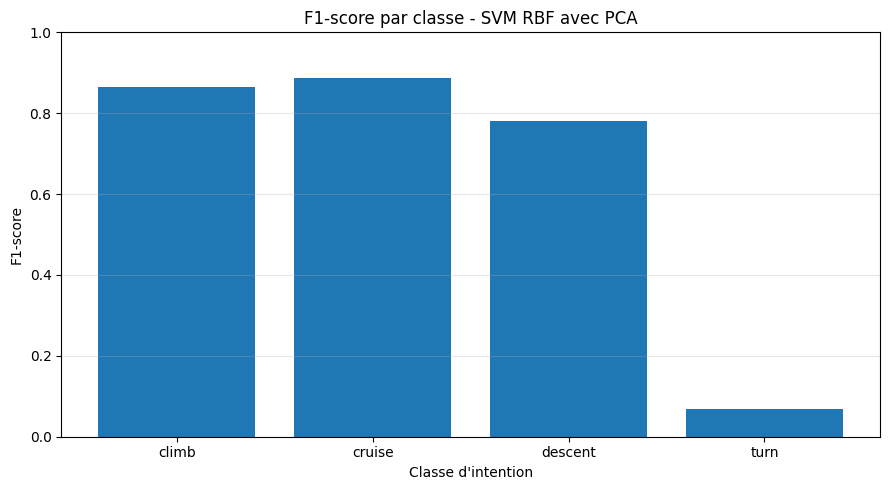

Rapport par classe sauvegardé : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/classification_report_by_class_2min.csv
Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/svm_f1_score_by_class_2min.png


In [75]:
# ============================================================
# 17.2. F1-score par classe
# ============================================================

classification_report_dict = classification_report(
    y_test_clf_encoded,
    y_test_pred_svm,
    target_names=label_encoder.classes_,
    output_dict=True
)

class_metrics_df = pd.DataFrame(classification_report_dict).T

# Garder uniquement les vraies classes, pas les lignes accuracy/macro/weighted
class_metrics_only = class_metrics_df.loc[label_encoder.classes_].copy()

class_metrics_path = METRICS_DIR / f"classification_report_by_class_{SELECTED_HORIZON_MIN}min.csv"
class_metrics_only.to_csv(class_metrics_path)

display(class_metrics_only)

plt.figure(figsize=(9, 5))
plt.bar(class_metrics_only.index, class_metrics_only["f1-score"])
plt.title("F1-score par classe - SVM RBF avec PCA")
plt.xlabel("Classe d'intention")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

figure_path = FIGURES_DIR / f"svm_f1_score_by_class_{SELECTED_HORIZON_MIN}min.png"
plt.savefig(figure_path, bbox_inches="tight")
plt.show()

print("Rapport par classe sauvegardé :", class_metrics_path)
print("Figure sauvegardée :", figure_path)

,climb,cruise,descent,turn
climb,10972,892,105,153
cruise,2109,46268,3914,2255
descent,121,2496,13501,790
turn,28,200,127,130


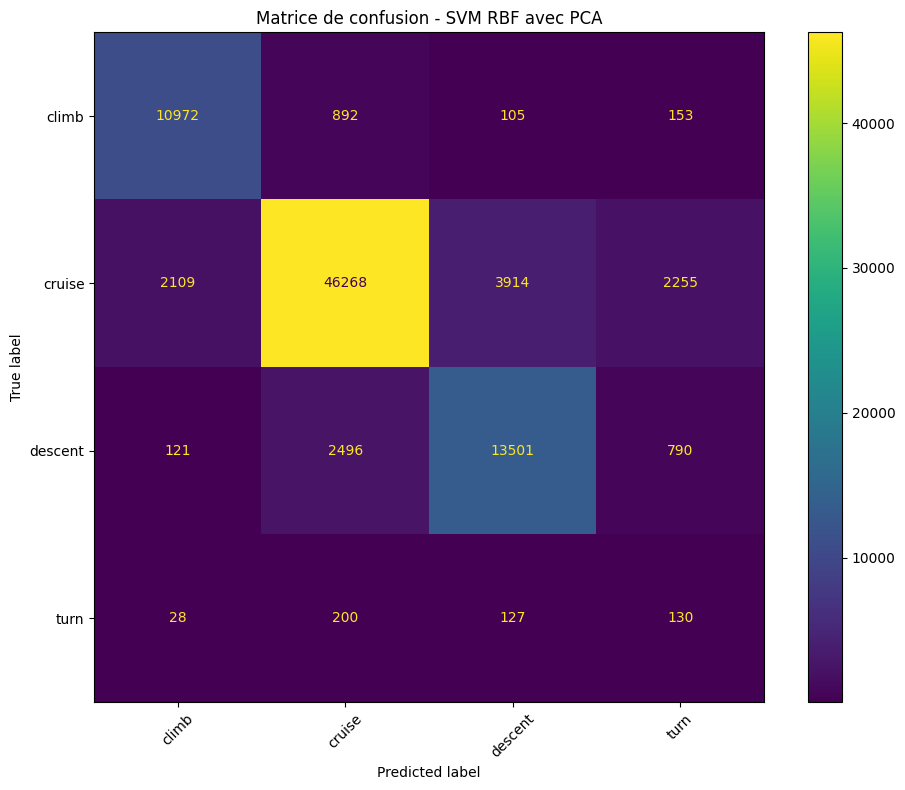

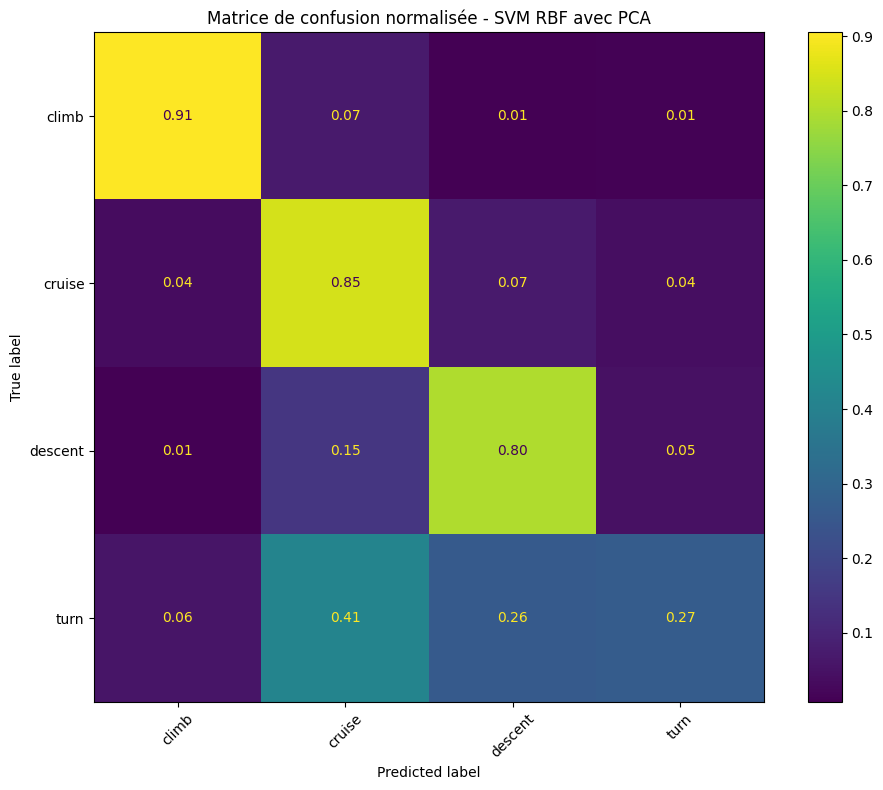

Matrice de confusion sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/confusion_matrix_svm_rbf_2min.csv
Figures sauvegardées : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/confusion_matrix_svm_absolute_2min.png et /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/confusion_matrix_svm_normalized_2min.png


In [76]:
# ============================================================
# 23.2. Matrice de confusion absolue et normalisée
# ============================================================

cm = confusion_matrix(y_test_clf_encoded, y_test_pred_svm)
cm_normalized = confusion_matrix(y_test_clf_encoded, y_test_pred_svm, normalize="true")

confusion_matrix_df = pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

display(confusion_matrix_df)

# Matrice absolue
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)
disp.plot(ax=ax, xticks_rotation=45, values_format="d")
plt.title("Matrice de confusion - SVM RBF avec PCA")
plt.tight_layout()
figure_path = FIGURES_DIR / f"confusion_matrix_svm_absolute_{SELECTED_HORIZON_MIN}min.png"
plt.savefig(figure_path, bbox_inches="tight")
plt.show()

# Matrice normalisée
fig, ax = plt.subplots(figsize=(10, 8))
disp_norm = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=label_encoder.classes_
)
disp_norm.plot(ax=ax, xticks_rotation=45, values_format=".2f")
plt.title("Matrice de confusion normalisée - SVM RBF avec PCA")
plt.tight_layout()
figure_norm_path = FIGURES_DIR / f"confusion_matrix_svm_normalized_{SELECTED_HORIZON_MIN}min.png"
plt.savefig(figure_norm_path, bbox_inches="tight")
plt.show()

# Sauvegarde CSV
confusion_matrix_path = METRICS_DIR / f"confusion_matrix_svm_rbf_{SELECTED_HORIZON_MIN}min.csv"
confusion_matrix_df.to_csv(confusion_matrix_path)
print("Matrice de confusion sauvegardée :", confusion_matrix_path)
print("Figures sauvegardées :", figure_path, "et", figure_norm_path)

,réel,prédit
cruise,54546,49856
descent,16908,17647
climb,12122,13230
turn,485,3328


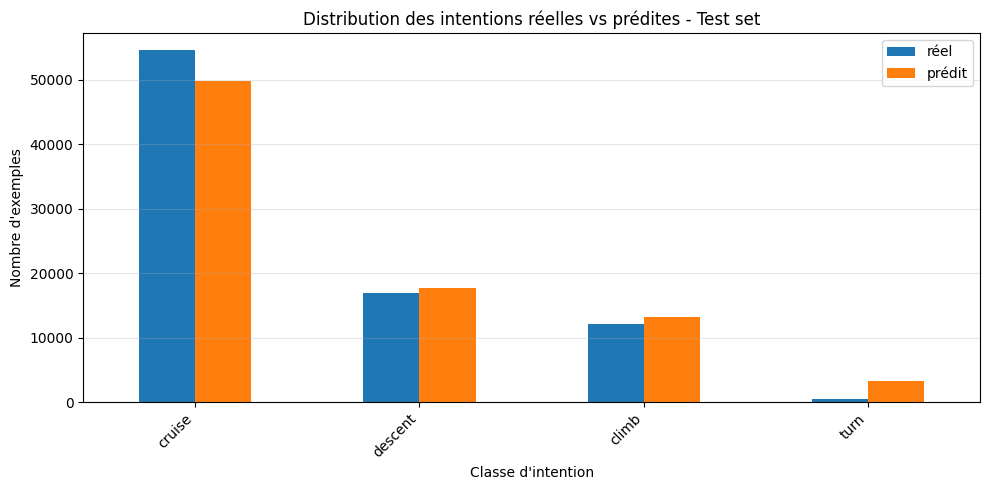

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/intentions_real_vs_predicted_distribution_2min.png


In [77]:
# ============================================================
# 23.3. Visualisation : intentions réelles vs prédites
# ============================================================

true_labels = label_encoder.inverse_transform(y_test_clf_encoded)
pred_labels = label_encoder.inverse_transform(y_test_pred_svm)

intent_comparison_df = pd.DataFrame({
    "intention_reelle": true_labels,
    "intention_predite": pred_labels
})

# Distribution réelle vs prédite
intent_distribution = pd.DataFrame({
    "réel": intent_comparison_df["intention_reelle"].value_counts(),
    "prédit": intent_comparison_df["intention_predite"].value_counts()
}).fillna(0).astype(int)

display(intent_distribution)

intent_distribution.plot(kind="bar", figsize=(10, 5))
plt.title("Distribution des intentions réelles vs prédites - Test set")
plt.xlabel("Classe d'intention")
plt.ylabel("Nombre d'exemples")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

figure_path = FIGURES_DIR / f"intentions_real_vs_predicted_distribution_{SELECTED_HORIZON_MIN}min.png"
plt.savefig(figure_path, bbox_inches="tight")
plt.show()

print("Figure sauvegardée :", figure_path)

In [78]:
# ============================================================
# 23.4. Exemples de prédictions d'intention
# ============================================================

intent_examples = intent_comparison_df.head(20).copy()
intent_examples["correct"] = intent_examples["intention_reelle"] == intent_examples["intention_predite"]

display(intent_examples)

,intention_reelle,intention_predite,correct
0,climb,climb,True
1,climb,climb,True
2,climb,climb,True
3,climb,climb,True
4,climb,climb,True
5,climb,climb,True
6,climb,climb,True
7,climb,climb,True
8,climb,climb,True
9,climb,climb,True


### 17.6. Interprétation de la classification

Les classes `climb`, `cruise` et `descent` sont globalement bien reconnues.  
La classe `turn` reste plus difficile, car elle est très minoritaire dans le test set.

Cette limite doit être mentionnée dans le rapport : l’accuracy globale est bonne, mais le F1-score macro baisse à cause des classes rares.

## 18. Sauvegarde des modèles et transformations

Nous sauvegardons tous les objets nécessaires pour refaire des prédictions plus tard :

- `scaler` ;
- modèles de régression ;
- PCA utilisée pour le SVM ;
- modèle SVM ;
- `LabelEncoder`.

In [79]:
# ============================================================
# 24. Sauvegarde des modèles et transformations
# ============================================================

# Transformations
joblib.dump(scaler, MODELS_DIR / f"scaler_{SELECTED_HORIZON_MIN}min.pkl")
joblib.dump(pca_svm, MODELS_DIR / f"pca_svm_only_{SELECTED_HORIZON_MIN}min.pkl")
joblib.dump(label_encoder, MODELS_DIR / f"label_encoder_{SELECTED_HORIZON_MIN}min.pkl")

# Modèles de régression
joblib.dump(decision_tree, MODELS_DIR / f"decision_tree_delta_{SELECTED_HORIZON_MIN}min.pkl")
joblib.dump(random_forest, MODELS_DIR / f"random_forest_delta_{SELECTED_HORIZON_MIN}min.pkl")
joblib.dump(gradient_boosting, MODELS_DIR / f"gradient_boosting_delta_{SELECTED_HORIZON_MIN}min.pkl")
joblib.dump(best_rf, MODELS_DIR / f"random_forest_delta_optimized_{SELECTED_HORIZON_MIN}min.pkl")

# Modèle de classification
joblib.dump(svm_rbf, MODELS_DIR / f"svm_rbf_with_pca_{SELECTED_HORIZON_MIN}min.pkl")

print("Modèles sauvegardés dans :", MODELS_DIR)
print("\nFichiers sauvegardés :")
for file in sorted(MODELS_DIR.glob("*.pkl")):
    print("-", file.name)

Modèles sauvegardés dans : /content/drive/MyDrive/aircraft-trajectory-prediction/models/ml

Fichiers sauvegardés :
- decision_tree_10min.pkl
- decision_tree_2min.pkl
- decision_tree_5min.pkl
- decision_tree_delta_10min.pkl
- decision_tree_delta_2min.pkl
- gradient_boosting_10min.pkl
- gradient_boosting_2min.pkl
- gradient_boosting_5min.pkl
- gradient_boosting_delta_10min.pkl
- gradient_boosting_delta_2min.pkl
- label_encoder_10min.pkl
- label_encoder_2min.pkl
- label_encoder_5min.pkl
- pca_svm_10min.pkl
- pca_svm_2min.pkl
- pca_svm_5min.pkl
- pca_svm_only_10min.pkl
- pca_svm_only_2min.pkl
- random_forest_10min.pkl
- random_forest_2min.pkl
- random_forest_5min.pkl
- random_forest_delta_10min.pkl
- random_forest_delta_2min.pkl
- random_forest_delta_optimized_10min.pkl
- random_forest_delta_optimized_2min.pkl
- random_forest_optimized_10min.pkl
- random_forest_optimized_2min.pkl
- random_forest_optimized_5min.pkl
- scaler_10min.pkl
- scaler_2min.pkl
- scaler_5min.pkl
- svm_rbf_10min.pkl
-

## 19. Comparaison finale, sauvegarde et figures

Cette section rassemble les résultats finaux de la partie Machine Learning :

- résultats de régression ;
- résultats de classification ;
- fichiers CSV et figures générés.

In [80]:
# ============================================================
# 25. Résultats finaux
# ============================================================

final_regression_results_path = METRICS_DIR / f"final_regression_results_{SELECTED_HORIZON_MIN}min.csv"
final_classification_results_path = METRICS_DIR / f"final_classification_results_{SELECTED_HORIZON_MIN}min.csv"

final_regression_results.to_csv(final_regression_results_path, index=False)
classification_results.to_csv(final_classification_results_path, index=False)

print("Résultats finaux de régression :")
display(final_regression_results)

print("Résultats finaux de classification :")
display(classification_results)

print("\nFichiers sauvegardés :")
print("-", final_regression_results_path)
print("-", final_classification_results_path)
print("-", confusion_matrix_path)
print("- dossier figures :", FIGURES_DIR)
print("- dossier modèles :", MODELS_DIR)

Résultats finaux de régression :


,model,dataset,RMSE_lat_future,MAE_lat_future,RMSE_lon_future,MAE_lon_future,RMSE_altitude_future,MAE_altitude_future,mean_deviation_km,median_deviation_km,max_deviation_km,training_time_sec
0,Baseline naïve,test,0.171847,0.119610,0.237786,0.169353,917.265293,375.199433,21.012601,24.906460,705.564269,NaN
1,Decision Tree Regressor amélioré,validation,0.156057,0.114805,0.317062,0.192934,894.091684,254.913837,21.428612,23.219576,729.691381,30.976866
2,Decision Tree Regressor amélioré,test,0.170687,0.118791,0.234584,0.165519,822.602270,244.202658,20.633522,23.111489,707.307113,30.976866
3,Random Forest Regressor amélioré,validation,0.129162,0.090641,0.285565,0.159616,727.388196,223.518808,17.499315,18.412549,726.596169,199.149930
4,Random Forest Regressor amélioré,test,0.144689,0.094409,0.199487,0.134855,704.092002,219.210135,16.757299,17.963060,699.089175,199.149930
5,Gradient Boosting Regressor amélioré,validation,0.072862,0.022877,0.219893,0.045858,739.062206,233.737302,4.879455,2.032933,746.011649,1365.671479
6,Gradient Boosting Regressor amélioré,test,0.095894,0.025372,0.120481,0.035904,723.073060,232.390897,4.510742,2.017043,724.971553,1365.671479
7,Random Forest optimisé,validation,0.114967,0.075769,0.265667,0.134278,731.070027,223.331564,14.742540,14.537859,727.447010,128.252488
8,Random Forest optimisé,test,0.131651,0.080403,0.177250,0.113590,706.832172,218.785585,14.193961,14.242161,695.076006,128.252488


Résultats finaux de classification :


,model,dataset,accuracy,f1_macro,f1_weighted,training_time_sec
0,SVM RBF avec PCA,validation,0.84442,0.645100,0.860662,32.53168
1,SVM RBF avec PCA,test,0.84309,0.650381,0.857524,32.53168



Fichiers sauvegardés :
- /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/final_regression_results_2min.csv
- /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/final_classification_results_2min.csv
- /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/confusion_matrix_svm_rbf_2min.csv
- dossier figures : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures
- dossier modèles : /content/drive/MyDrive/aircraft-trajectory-prediction/models/ml


### 19.2. Graphes finaux pour le rapport et la présentation

Après l’ajout du Random Forest optimisé, nous générons des graphes finaux qui résument toute la partie régression :

- distance moyenne de déviation ;
- distance médiane de déviation ;
- temps d’entraînement ;
- compromis performance / temps.

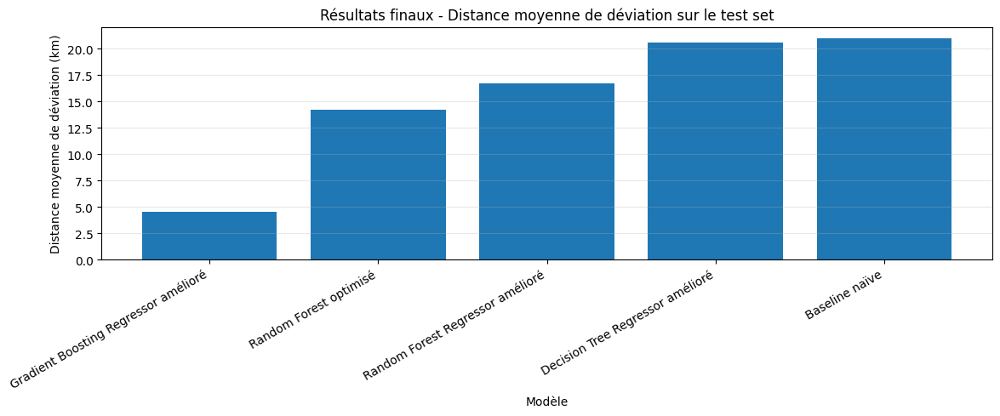

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/final_regression_mean_deviation_2min.png


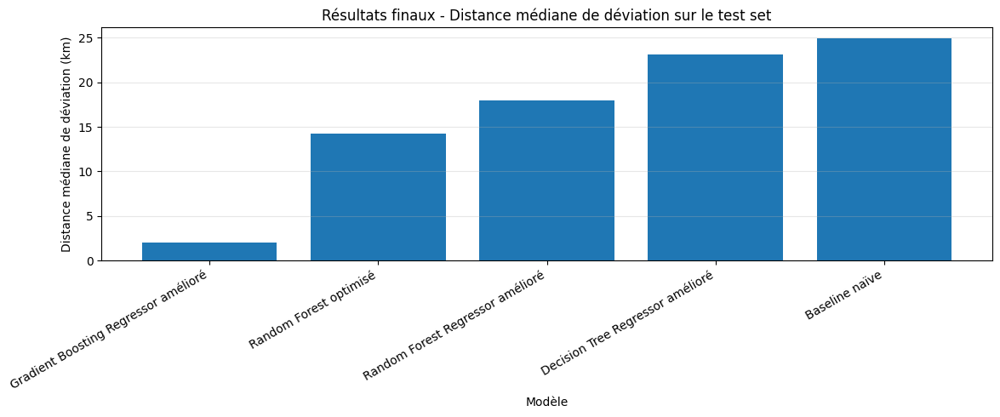

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/final_regression_median_deviation_2min.png


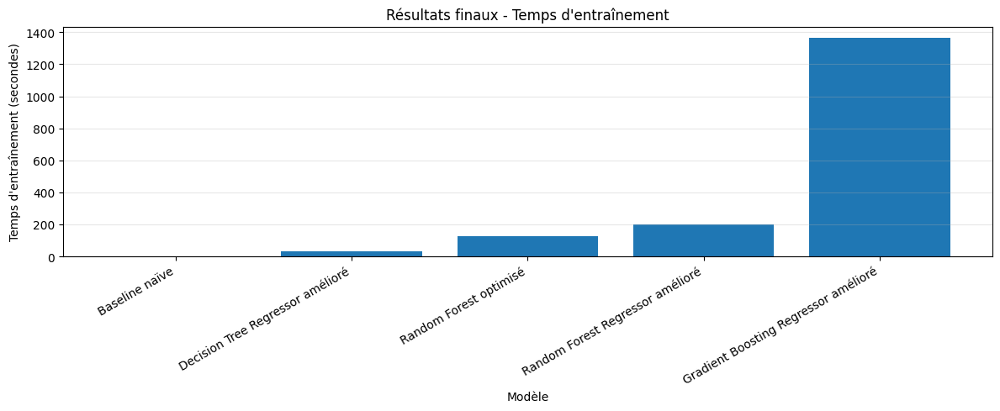

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/final_regression_training_time_2min.png


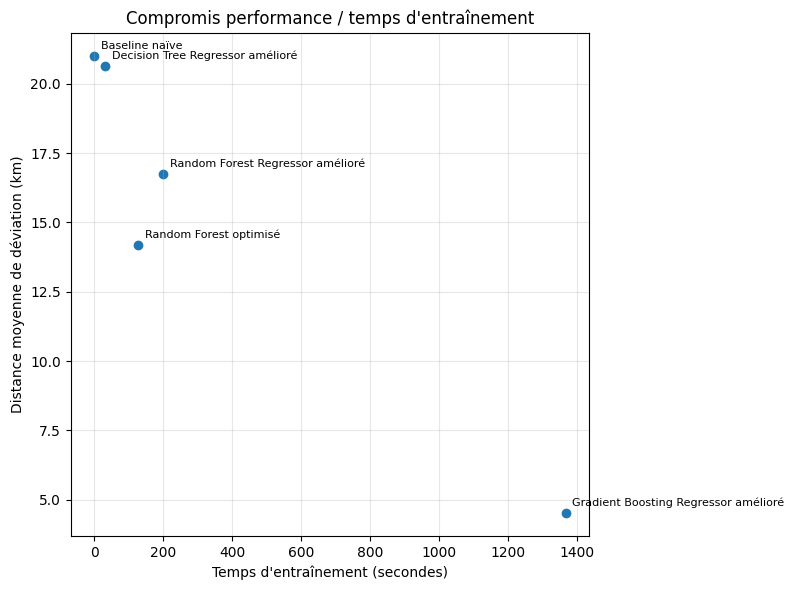

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/final_regression_performance_vs_time_2min.png


In [81]:
# ============================================================
# 19.2. Visualisations finales des modèles de régression
# ============================================================

final_test_results = final_regression_results[
    final_regression_results["dataset"].fillna("test") == "test"
].copy()

if "training_time_sec" in final_test_results.columns:
    final_test_results["training_time_sec"] = final_test_results["training_time_sec"].fillna(0)

# 1) Distance moyenne finale
mean_sorted = final_test_results.sort_values("mean_deviation_km")

plt.figure(figsize=(12, 5))
plt.bar(mean_sorted["model"], mean_sorted["mean_deviation_km"])
plt.title("Résultats finaux - Distance moyenne de déviation sur le test set")
plt.xlabel("Modèle")
plt.ylabel("Distance moyenne de déviation (km)")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

figure_path = FIGURES_DIR / f"final_regression_mean_deviation_{SELECTED_HORIZON_MIN}min.png"
plt.savefig(figure_path, bbox_inches="tight")
plt.show()

print("Figure sauvegardée :", figure_path)

# 2) Distance médiane finale
median_sorted = final_test_results.sort_values("median_deviation_km")

plt.figure(figsize=(12, 5))
plt.bar(median_sorted["model"], median_sorted["median_deviation_km"])
plt.title("Résultats finaux - Distance médiane de déviation sur le test set")
plt.xlabel("Modèle")
plt.ylabel("Distance médiane de déviation (km)")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

figure_path = FIGURES_DIR / f"final_regression_median_deviation_{SELECTED_HORIZON_MIN}min.png"
plt.savefig(figure_path, bbox_inches="tight")
plt.show()

print("Figure sauvegardée :", figure_path)

# 3) Temps d'entraînement final
if "training_time_sec" in final_test_results.columns:
    time_sorted = final_test_results.sort_values("training_time_sec")

    plt.figure(figsize=(12, 5))
    plt.bar(time_sorted["model"], time_sorted["training_time_sec"])
    plt.title("Résultats finaux - Temps d'entraînement")
    plt.xlabel("Modèle")
    plt.ylabel("Temps d'entraînement (secondes)")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    figure_path = FIGURES_DIR / f"final_regression_training_time_{SELECTED_HORIZON_MIN}min.png"
    plt.savefig(figure_path, bbox_inches="tight")
    plt.show()

    print("Figure sauvegardée :", figure_path)

# 4) Compromis performance / temps
plot_df = final_test_results[
    final_test_results["training_time_sec"].notna()
].copy()

if len(plot_df) > 0:
    plt.figure(figsize=(8, 6))
    plt.scatter(plot_df["training_time_sec"], plot_df["mean_deviation_km"])

    for _, row in plot_df.iterrows():
        plt.annotate(
            row["model"],
            (row["training_time_sec"], row["mean_deviation_km"]),
            fontsize=8,
            xytext=(5, 5),
            textcoords="offset points"
        )

    plt.title("Compromis performance / temps d'entraînement")
    plt.xlabel("Temps d'entraînement (secondes)")
    plt.ylabel("Distance moyenne de déviation (km)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    figure_path = FIGURES_DIR / f"final_regression_performance_vs_time_{SELECTED_HORIZON_MIN}min.png"
    plt.savefig(figure_path, bbox_inches="tight")
    plt.show()

    print("Figure sauvegardée :", figure_path)

### 19.3. Inventaire des fichiers sauvegardés

Cette cellule crée un inventaire des figures et cartes générées.  
Il sera utile pour préparer le rapport et la présentation.

In [82]:
# ============================================================
# 19.3. Inventaire des figures et cartes sauvegardées
# ============================================================

saved_figures = sorted(FIGURES_DIR.glob("*"))
figures_inventory = pd.DataFrame({
    "filename": [p.name for p in saved_figures],
    "path": [str(p) for p in saved_figures],
    "type": [p.suffix for p in saved_figures]
})

figures_inventory_path = METRICS_DIR / f"figures_inventory_{SELECTED_HORIZON_MIN}min.csv"
figures_inventory.to_csv(figures_inventory_path, index=False)

display(figures_inventory)
print("Inventaire des figures sauvegardé :", figures_inventory_path)

,filename,path,type
0,01_learning_curves_baseline.png,/content/drive/MyDrive/aircraft-trajectory-pre...,.png
1,02_lr_schedules.png,/content/drive/MyDrive/aircraft-trajectory-pre...,.png
2,03_batch_size_study.png,/content/drive/MyDrive/aircraft-trajectory-pre...,.png
3,06_error_by_horizon.png,/content/drive/MyDrive/aircraft-trajectory-pre...,.png
4,07_residuals_analysis.png,/content/drive/MyDrive/aircraft-trajectory-pre...,.png
...,...,...,...
83,trajectory_error_over_time_2min.png,/content/drive/MyDrive/aircraft-trajectory-pre...,.png
84,trajectory_real_vs_predicted_10min.png,/content/drive/MyDrive/aircraft-trajectory-pre...,.png
85,trajectory_real_vs_predicted_2min.png,/content/drive/MyDrive/aircraft-trajectory-pre...,.png
86,trajectory_real_vs_predicted_4a35ad_1_2min.png,/content/drive/MyDrive/aircraft-trajectory-pre...,.png


Inventaire des figures sauvegardé : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/figures_inventory_2min.csv


## 20. Conclusion de la partie Machine Learning

Dans ce notebook, nous avons finalisé la partie Machine Learning du projet ADS-B.

Nous avons réalisé :

1. la préparation des données pour un horizon de prédiction de 2 minutes ;
2. une baseline naïve ;
3. une normalisation des features ;
4. une reformulation de la régression en prédiction de déplacements ;
5. plusieurs modèles de régression :
   - Decision Tree Regressor ;
   - Random Forest Regressor ;
   - Gradient Boosting Regressor ;
   - Random Forest optimisé avec Optuna ;
6. une comparaison finale des modèles avec RMSE, MAE, distance moyenne, distance médiane et temps d’entraînement ;
7. des visualisations 2D et 3D/cartographiques de la trajectoire réelle vs prédite ;
8. une analyse des erreurs et des résidus du meilleur modèle ;
9. une PCA appliquée uniquement au SVM ;
10. un SVM RBF pour la classification d’intention ;
11. une évaluation avec Accuracy, F1-score, rapport de classification et matrices de confusion ;
12. la sauvegarde des modèles, métriques, figures et cartes HTML.

La suite du projet est la partie Deep Learning, où nous utiliserons des modèles séquentiels comme GRU, LSTM ou TCN pour exploiter plus directement la dimension temporelle des trajectoires.

---

# Partie C — Expérimentations multi-horizons : 2, 5 et 10 minutes

Cette partie complète le notebook en lançant **le même pipeline ML** sur les trois horizons demandés :

- **2 minutes** ;
- **5 minutes** ;
- **10 minutes**.

L’objectif est de comparer les performances des modèles lorsque l’horizon de prédiction augmente.

Pour chaque horizon, nous réalisons :

1. préparation ou rechargement des splits ;
2. baseline naïve ;
3. normalisation ;
4. reformulation en prédiction de déplacements ;
5. entraînement des modèles de régression ;
6. optimisation du Random Forest avec Optuna ;
7. classification d’intention avec SVM RBF + PCA ;
8. sauvegarde des métriques, modèles, prédictions et figures ;
9. comparaison globale entre les horizons.

> Remarque : plus l’horizon augmente, plus la prédiction devient difficile. Il est donc normal que les erreurs soient plus grandes à 5 et 10 minutes qu’à 2 minutes.

In [3]:
# ============================================================
# PARTIE C — Expérimentations multi-horizons : 2, 5 et 10 min
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import time
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

from sklearn.svm import SVC

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# Horizons à tester
# ------------------------------------------------------------

HORIZONS_TO_RUN = [2, 5, 10]

# ------------------------------------------------------------
# Paramètre de reproductibilité
# ------------------------------------------------------------

RANDOM_STATE = 42

# ------------------------------------------------------------
# Option importante
# ------------------------------------------------------------
# True  : utiliser les modèles déjà sauvegardés s'ils existent
# False : réentraîner tous les modèles

USE_SAVED_MODELS = True

# ------------------------------------------------------------
# Options d'exécution
# ------------------------------------------------------------

RUN_OPTUNA = True
OPTUNA_TRIALS = 10

RUN_SVM = True

RUN_3D_VISUALIZATIONS = True
RUN_PYDECK_MAPS = False

SVM_TRAIN_MAX_ROWS = 120000

MIN_POINTS_TRAJECTORY = 80
MAX_POINTS_TO_PLOT = 200

# ------------------------------------------------------------
# Chemins du projet
# ------------------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/aircraft-trajectory-prediction")

DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
ML_SPLITS_DIR = PROCESSED_DIR / "ml_splits"

RESULTS_DIR = PROJECT_DIR / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"
PREDICTIONS_DIR = RESULTS_DIR / "predictions"

MODELS_DIR = PROJECT_DIR / "models" / "ml"

# Création des dossiers
METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration Partie C prête.")
print("Horizons à exécuter :", HORIZONS_TO_RUN)
print("USE_SAVED_MODELS   :", USE_SAVED_MODELS)
print("Dossier splits     :", ML_SPLITS_DIR)
print("Dossier modèles    :", MODELS_DIR)
print("Dossier figures    :", FIGURES_DIR)
print("Dossier métriques  :", METRICS_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Configuration Partie C prête.
Horizons à exécuter : [2, 5, 10]
USE_SAVED_MODELS   : True
Dossier splits     : /content/drive/MyDrive/aircraft-trajectory-prediction/data/processed/ml_splits
Dossier modèles    : /content/drive/MyDrive/aircraft-trajectory-prediction/models/ml
Dossier figures    : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures
Dossier métriques  : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics


In [4]:
# ============================================================
#fonction standardize_y_reg_columns
# ============================================================

def clean_loaded_dataframe(df):
    """
    Supprime les colonnes parasites créées parfois lors de la sauvegarde CSV,
    comme Unnamed: 0.
    """
    df = df.copy()
    cols_to_drop = [col for col in df.columns if str(col).startswith("Unnamed")]

    if len(cols_to_drop) > 0:
        df = df.drop(columns=cols_to_drop)

    return df


def standardize_y_reg_columns(y_reg):
    """
    Standardise les colonnes des targets de régression.

    Les colonnes attendues sont :
    - lat_future
    - lon_future
    - altitude_future
    """

    y_reg = pd.DataFrame(y_reg).copy()
    y_reg = clean_loaded_dataframe(y_reg)

    expected_cols = ["lat_future", "lon_future", "altitude_future"]

    # Si les colonnes sont déjà correctes
    if all(col in y_reg.columns for col in expected_cols):
        return y_reg[expected_cols]

    # Si le fichier contient exactement 3 colonnes mais avec d'autres noms
    if y_reg.shape[1] == 3:
        y_reg.columns = expected_cols
        return y_reg

    raise ValueError(
        f"Impossible de standardiser y_reg. "
        f"Colonnes actuelles : {list(y_reg.columns)}"
    )


print("Fonction standardize_y_reg_columns prête.")

Fonction standardize_y_reg_columns prête.


## C.2. Préparation des splits pour tous les horizons

Cette cellule vérifie si les fichiers de splits existent pour **2, 5 et 10 minutes**.

Si certains fichiers sont absents, ils sont recréés à partir de `features_clean.csv` ou du DataFrame `df` déjà présent dans le notebook.

Le split est effectué par `trajectory_id` pour éviter qu’une même trajectoire soit présente à la fois dans le train et dans le test.

In [ ]:
# ============================================================
# C.2. Préparation ou vérification des splits multi-horizons
# ============================================================

FEATURES_MULTI = [
    "lat", "lon", "altitude", "velocity", "heading", "vertrate",
    "ground_speed_ms", "vertical_rate_fpm", "acceleration", "turn_rate",
    "vx_ms", "vy_ms", "vz_ms", "heading_sin", "heading_cos",
    "distance_step_m", "distance_traveled_m", "trajectory_angle",
    "distance_destination_m", "elapsed_time_sec",
    "roll_mean_velocity", "roll_std_velocity",
    "roll_mean_altitude", "roll_std_altitude",
    "roll_mean_vertrate", "roll_std_vertrate",
    "roll_mean_acceleration", "roll_std_acceleration",
    "roll_mean_turn_rate", "roll_std_turn_rate",
    "roll_mean_distance_step_m", "roll_std_distance_step_m"
]

TARGETS_REG_MULTI = ["lat_future", "lon_future", "altitude_future"]
TARGET_CLF_MULTI = "intent_future"

def required_split_paths_for_horizon(horizon_min):
    names = [
        "X_train", "X_val", "X_test",
        "y_train_reg", "y_val_reg", "y_test_reg",
        "y_train_clf", "y_val_clf", "y_test_clf",
        "metadata_train", "metadata_val", "metadata_test",
    ]
    return [ML_SPLITS_DIR / f"{name}_{horizon_min}min.csv" for name in names]

def splits_exist_for_horizon(horizon_min):
    return all(path.exists() for path in required_split_paths_for_horizon(horizon_min))

# Charger df si nécessaire
if "df" not in globals():
    features_clean_path = PROCESSED_DIR / "features_clean.csv"
    if not features_clean_path.exists():
        raise FileNotFoundError(
            "Impossible de préparer les horizons : features_clean.csv est introuvable."
        )
    df = pd.read_csv(features_clean_path, parse_dates=["datetime"])
    print("features_clean.csv chargé :", df.shape)
else:
    df = df.copy()
    if "datetime" in df.columns:
        df["datetime"] = pd.to_datetime(df["datetime"])
    print("DataFrame df déjà disponible :", df.shape)

df = df.sort_values(["trajectory_id", "datetime"]).reset_index(drop=True)

# Créer les targets futures spécifiques si elles n'existent pas
for horizon_min in HORIZONS_TO_RUN:
    horizon_steps = (horizon_min * 60) // RESAMPLING_SECONDS

    required_specific_targets = [
        f"lat_future_{horizon_min}min",
        f"lon_future_{horizon_min}min",
        f"altitude_future_{horizon_min}min",
        f"intent_future_{horizon_min}min",
    ]

    if not all(col in df.columns for col in required_specific_targets):
        df[f"lat_future_{horizon_min}min"] = df.groupby("trajectory_id")["lat"].shift(-horizon_steps)
        df[f"lon_future_{horizon_min}min"] = df.groupby("trajectory_id")["lon"].shift(-horizon_steps)
        df[f"altitude_future_{horizon_min}min"] = df.groupby("trajectory_id")["altitude"].shift(-horizon_steps)
        df[f"intent_future_{horizon_min}min"] = df.groupby("trajectory_id")["flight_phase"].shift(-horizon_steps)

print("Targets spécifiques disponibles pour :", HORIZONS_TO_RUN)

# Split par trajectoire, conservé identique pour tous les horizons
unique_trajectories = df["trajectory_id"].dropna().unique()

train_traj, temp_traj = train_test_split(
    unique_trajectories,
    test_size=0.30,
    random_state=RANDOM_STATE
)

val_traj, test_traj = train_test_split(
    temp_traj,
    test_size=0.50,
    random_state=RANDOM_STATE
)

print("Trajectoires train / val / test :", len(train_traj), len(val_traj), len(test_traj))

split_generation_summary = []

for horizon_min in HORIZONS_TO_RUN:

    if splits_exist_for_horizon(horizon_min):
        print(f"Horizon {horizon_min} min : splits déjà disponibles.")
        split_generation_summary.append({
            "horizon_min": horizon_min,
            "status": "déjà existant"
        })
        continue

    print("=" * 70)
    print(f"Création des splits pour horizon {horizon_min} min")
    print("=" * 70)

    df_h = df.copy()

    # Colonnes génériques pour cet horizon
    df_h["lat_future"] = df_h[f"lat_future_{horizon_min}min"]
    df_h["lon_future"] = df_h[f"lon_future_{horizon_min}min"]
    df_h["altitude_future"] = df_h[f"altitude_future_{horizon_min}min"]
    df_h["intent_future"] = df_h[f"intent_future_{horizon_min}min"]

    features_h = [col for col in FEATURES_MULTI if col in df_h.columns]

    metadata_cols = [col for col in ["trajectory_id", "icao24", "datetime"] if col in df_h.columns]

    required_cols = features_h + TARGETS_REG_MULTI + [TARGET_CLF_MULTI, "trajectory_id"]

    df_h = df_h.replace([np.inf, -np.inf], np.nan)
    n_before = len(df_h)

    df_h = df_h.dropna(subset=required_cols).reset_index(drop=True)
    n_after = len(df_h)

    print("Lignes avant :", f"{n_before:,}")
    print("Lignes après :", f"{n_after:,}")
    print("Features utilisées :", len(features_h))

    # Sauvegarder dataset complet pour cet horizon
    ml_dataset_path = PROCESSED_DIR / f"ml_dataset_{horizon_min}min.csv"
    df_h.to_csv(ml_dataset_path, index=False)

    # Split avec les mêmes listes de trajectory_id
    train_mask = df_h["trajectory_id"].isin(train_traj)
    val_mask = df_h["trajectory_id"].isin(val_traj)
    test_mask = df_h["trajectory_id"].isin(test_traj)

    X_train_h = df_h.loc[train_mask, features_h].copy()
    X_val_h = df_h.loc[val_mask, features_h].copy()
    X_test_h = df_h.loc[test_mask, features_h].copy()

    y_train_reg_h = df_h.loc[train_mask, TARGETS_REG_MULTI].copy()
    y_val_reg_h = df_h.loc[val_mask, TARGETS_REG_MULTI].copy()
    y_test_reg_h = df_h.loc[test_mask, TARGETS_REG_MULTI].copy()

    y_train_clf_h = df_h.loc[train_mask, TARGET_CLF_MULTI].copy()
    y_val_clf_h = df_h.loc[val_mask, TARGET_CLF_MULTI].copy()
    y_test_clf_h = df_h.loc[test_mask, TARGET_CLF_MULTI].copy()

    split_objects = {
        "X_train": X_train_h,
        "X_val": X_val_h,
        "X_test": X_test_h,
        "y_train_reg": y_train_reg_h,
        "y_val_reg": y_val_reg_h,
        "y_test_reg": y_test_reg_h,
        "y_train_clf": y_train_clf_h.to_frame(name=TARGET_CLF_MULTI),
        "y_val_clf": y_val_clf_h.to_frame(name=TARGET_CLF_MULTI),
        "y_test_clf": y_test_clf_h.to_frame(name=TARGET_CLF_MULTI),
        "metadata_train": df_h.loc[train_mask, metadata_cols].copy(),
        "metadata_val": df_h.loc[val_mask, metadata_cols].copy(),
        "metadata_test": df_h.loc[test_mask, metadata_cols].copy(),
    }

    for name, data_obj in split_objects.items():
        output_path = ML_SPLITS_DIR / f"{name}_{horizon_min}min.csv"
        data_obj.to_csv(output_path, index=False)

    # Sauvegarder features utilisées
    with open(METRICS_DIR / f"ml_features_used_{horizon_min}min.txt", "w", encoding="utf-8") as f:
        for feature in features_h:
            f.write(feature + "\n")

    split_generation_summary.append({
        "horizon_min": horizon_min,
        "status": "créé",
        "n_before": n_before,
        "n_after": n_after,
        "n_features": len(features_h),
        "train_rows": len(X_train_h),
        "val_rows": len(X_val_h),
        "test_rows": len(X_test_h),
    })

split_generation_summary_df = pd.DataFrame(split_generation_summary)
display(split_generation_summary_df)

split_generation_summary_path = METRICS_DIR / "multi_horizon_split_generation_summary.csv"
split_generation_summary_df.to_csv(split_generation_summary_path, index=False)
print("Résumé sauvegardé :", split_generation_summary_path)

/tmp/ipykernel_36856/2687835822.py:41: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(features_clean_path, parse_dates=["datetime"])


## C.3. Fonctions communes pour les modèles et les visualisations

Nous définissons ici des fonctions réutilisables pour éviter de répéter le code pour chaque horizon.

In [1]:
# ============================================================
# C.3 — Fonctions utilitaires régression
# ============================================================

def find_column(df, possible_names):
    """
    Trouve une colonne dans un DataFrame à partir d'une liste de noms possibles.
    """
    for col in possible_names:
        if col in df.columns:
            return col
    raise ValueError(f"Aucune colonne trouvée parmi : {possible_names}")


def get_position_columns(X):
    """
    Détecte les colonnes de position actuelle.
    """
    lat_col = find_column(X, ["lat", "latitude"])
    lon_col = find_column(X, ["lon", "longitude"])
    alt_col = find_column(X, ["altitude", "baroaltitude", "geoaltitude"])

    return lat_col, lon_col, alt_col


def haversine_km(lat1, lon1, lat2, lon2):
    """
    Calcule la distance géographique entre deux points GPS en kilomètres.
    """
    R = 6371.0

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))
    return R * c


def create_delta_targets(X, y_reg, lat_col, lon_col, alt_col):
    """
    Crée les targets delta :
    delta_lat = lat_future - lat actuelle
    delta_lon = lon_future - lon actuelle
    delta_altitude = altitude_future - altitude actuelle
    """
    y_delta = pd.DataFrame({
        "delta_lat": y_reg["lat_future"].values - X[lat_col].values,
        "delta_lon": y_reg["lon_future"].values - X[lon_col].values,
        "delta_altitude": y_reg["altitude_future"].values - X[alt_col].values
    })

    return y_delta


def reconstruct_future_position(X_original, y_pred_delta, lat_col, lon_col, alt_col):
    """
    Reconstruit les coordonnées futures à partir des deltas prédits.
    """
    y_pred_delta = np.asarray(y_pred_delta)

    y_pred_future = pd.DataFrame({
        "lat_future": X_original[lat_col].values + y_pred_delta[:, 0],
        "lon_future": X_original[lon_col].values + y_pred_delta[:, 1],
        "altitude_future": X_original[alt_col].values + y_pred_delta[:, 2]
    })

    return y_pred_future


def convert_model_output_to_future(X_original, raw_pred, lat_col, lon_col, alt_col):
    """
    Convertit la sortie du modèle en coordonnées futures.

    Si la sortie ressemble à des deltas :
        on reconstruit avec lat + delta_lat.
    Si la sortie ressemble à des coordonnées absolues :
        on l'utilise directement.

    Cette fonction est utile car certains anciens modèles sauvegardés
    peuvent avoir été entraînés directement sur lat_future/lon_future/altitude_future.
    """
    raw_pred = np.asarray(raw_pred)

    median_abs_lat = np.nanmedian(np.abs(raw_pred[:, 0]))
    median_abs_lon = np.nanmedian(np.abs(raw_pred[:, 1]))

    looks_like_delta = (median_abs_lat < 5) and (median_abs_lon < 5)

    if looks_like_delta:
        return reconstruct_future_position(
            X_original,
            raw_pred,
            lat_col,
            lon_col,
            alt_col
        )

    return pd.DataFrame({
        "lat_future": raw_pred[:, 0],
        "lon_future": raw_pred[:, 1],
        "altitude_future": raw_pred[:, 2]
    })


def evaluate_regression_model(model_name, dataset_name, y_true, y_pred, training_time_sec=None):
    """
    Évalue un modèle de régression avec :
    - RMSE
    - MAE
    - distance moyenne, médiane et maximale de déviation.
    """
    y_true_df = standardize_y_reg_columns(pd.DataFrame(y_true)).reset_index(drop=True)
    y_pred_df = standardize_y_reg_columns(pd.DataFrame(y_pred)).reset_index(drop=True)

    results = {
        "model": model_name,
        "dataset": dataset_name
    }

    for col in ["lat_future", "lon_future", "altitude_future"]:
        rmse = np.sqrt(mean_squared_error(y_true_df[col], y_pred_df[col]))
        mae = mean_absolute_error(y_true_df[col], y_pred_df[col])

        results[f"RMSE_{col}"] = rmse
        results[f"MAE_{col}"] = mae

    distances_km = haversine_km(
        y_true_df["lat_future"],
        y_true_df["lon_future"],
        y_pred_df["lat_future"],
        y_pred_df["lon_future"]
    )

    results["mean_deviation_km"] = np.mean(distances_km)
    results["median_deviation_km"] = np.median(distances_km)
    results["max_deviation_km"] = np.max(distances_km)
    results["p90_deviation_km"] = np.percentile(distances_km, 90)
    results["p95_deviation_km"] = np.percentile(distances_km, 95)
    results["p99_deviation_km"] = np.percentile(distances_km, 99)

    if training_time_sec is not None:
        results["training_time_sec"] = training_time_sec

    return results


print("Fonctions d'évaluation prêtes.")

Fonctions d'évaluation prêtes.


In [3]:
# ============================================================
# Correction rapide : configuration minimale Partie C
# ============================================================

from pathlib import Path
import time
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Horizons à tester
HORIZONS_TO_RUN = [2, 5, 10]

# Reproductibilité
RANDOM_STATE = 42

# Utiliser les modèles déjà entraînés s'ils existent
USE_SAVED_MODELS = True

# Options
RUN_OPTUNA = True
OPTUNA_TRIALS = 10
RUN_SVM = True
RUN_3D_VISUALIZATIONS = True
RUN_PYDECK_MAPS = False

SVM_TRAIN_MAX_ROWS = 120000
MIN_POINTS_TRAJECTORY = 80
MAX_POINTS_TO_PLOT = 200

# Chemins du projet
PROJECT_DIR = Path("/content/drive/MyDrive/aircraft-trajectory-prediction")

DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
ML_SPLITS_DIR = PROCESSED_DIR / "ml_splits"

RESULTS_DIR = PROJECT_DIR / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"
PREDICTIONS_DIR = RESULTS_DIR / "predictions"

MODELS_DIR = PROJECT_DIR / "models" / "ml"

# Création des dossiers si nécessaire
METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration minimale prête.")
print("Horizons :", HORIZONS_TO_RUN)
print("USE_SAVED_MODELS :", USE_SAVED_MODELS)
print("Dossier modèles :", MODELS_DIR)

Configuration minimale prête.
Horizons : [2, 5, 10]
USE_SAVED_MODELS : True
Dossier modèles : /content/drive/MyDrive/aircraft-trajectory-prediction/models/ml


## C.4. Chargement automatique des modèles existants

In [4]:
# ============================================================
# C.4 — Chargement automatique des modèles déjà entraînés
# ============================================================

def find_existing_model_file(model_type, horizon_min):
    """
    Cherche un fichier modèle existant, même si le nom exact varie.
    """

    patterns = {
        "scaler": [
            f"scaler_{horizon_min}min.pkl",
            f"*scaler*{horizon_min}min*.pkl"
        ],

        "decision_tree": [
            f"decision_tree_delta_{horizon_min}min.pkl",
            f"decision_tree_{horizon_min}min.pkl",
            f"*decision_tree*{horizon_min}min*.pkl"
        ],

        "random_forest": [
            f"random_forest_delta_{horizon_min}min.pkl",
            f"random_forest_{horizon_min}min.pkl",
            f"*random_forest*delta*{horizon_min}min*.pkl",
            f"*random_forest*{horizon_min}min*.pkl"
        ],

        "gradient_boosting": [
            f"gradient_boosting_delta_{horizon_min}min.pkl",
            f"gradient_boosting_{horizon_min}min.pkl",
            f"*gradient_boosting*delta*{horizon_min}min*.pkl",
            f"*gradient_boosting*{horizon_min}min*.pkl"
        ],

        "random_forest_optimized": [
            f"random_forest_optimized_delta_{horizon_min}min.pkl",
            f"random_forest_optimized_{horizon_min}min.pkl",
            f"*random_forest*optimiz*{horizon_min}min*.pkl",
            f"*random_forest*optimized*{horizon_min}min*.pkl"
        ],

        "label_encoder": [
            f"label_encoder_{horizon_min}min.pkl",
            f"*label_encoder*{horizon_min}min*.pkl"
        ],

        "pca": [
            f"pca_svm_{horizon_min}min.pkl",
            f"pca_svm_only_{horizon_min}min.pkl",
            f"*pca*{horizon_min}min*.pkl"
        ],

        "svm": [
            f"svm_rbf_pca_{horizon_min}min.pkl",
            f"svm_rbf_with_pca_{horizon_min}min.pkl",
            f"svm_rbf_{horizon_min}min.pkl",
            f"*svm*{horizon_min}min*.pkl"
        ]
    }

    for pattern in patterns[model_type]:
        matched_files = sorted(list(MODELS_DIR.glob(pattern)))
        if len(matched_files) > 0:
            return matched_files[0]

    return None


def load_or_train_object(model_type, horizon_min, save_path, object_name, train_function):
    """
    Si USE_SAVED_MODELS=True et qu'un modèle existe :
        charge le modèle.
    Sinon :
        entraîne le modèle et le sauvegarde.
    """

    existing_path = find_existing_model_file(model_type, horizon_min)

    if USE_SAVED_MODELS and existing_path is not None:
        obj = joblib.load(existing_path)
        training_time = 0.0
        print(f"{object_name} chargé depuis : {existing_path.name}")
        return obj, training_time

    print(f"Entraînement de {object_name}...")

    start_time = time.time()
    obj = train_function()
    training_time = time.time() - start_time

    joblib.dump(obj, save_path)

    print(f"{object_name} entraîné et sauvegardé : {save_path.name}")
    print(f"Temps d'entraînement : {training_time:.2f} secondes")

    return obj, training_time


# Vérification des modèles disponibles
for horizon in HORIZONS_TO_RUN:
    print(f"\n===== Horizon {horizon} min =====")

    for model_type in [
        "scaler",
        "decision_tree",
        "random_forest",
        "gradient_boosting",
        "random_forest_optimized",
        "label_encoder",
        "pca",
        "svm"
    ]:
        path = find_existing_model_file(model_type, horizon)

        if path is not None:
            print(f"{model_type:<25} => {path.name}")
        else:
            print(f"{model_type:<25} => MANQUANT")


===== Horizon 2 min =====
scaler                    => scaler_2min.pkl
decision_tree             => decision_tree_delta_2min.pkl
random_forest             => random_forest_delta_2min.pkl
gradient_boosting         => gradient_boosting_delta_2min.pkl
random_forest_optimized   => random_forest_optimized_2min.pkl
label_encoder             => label_encoder_2min.pkl
pca                       => pca_svm_2min.pkl
svm                       => svm_rbf_with_pca_2min.pkl

===== Horizon 5 min =====
scaler                    => scaler_5min.pkl
decision_tree             => decision_tree_5min.pkl
random_forest             => random_forest_5min.pkl
gradient_boosting         => gradient_boosting_5min.pkl
random_forest_optimized   => random_forest_optimized_5min.pkl
label_encoder             => label_encoder_5min.pkl
pca                       => pca_svm_5min.pkl
svm                       => svm_rbf_5min.pkl

===== Horizon 10 min =====
scaler                    => scaler_10min.pkl
decision_tree          

In [5]:
# ============================================================
# C.5 — Visualisations des trajectoires par horizon
# ============================================================

def build_visualization_dataframe(y_test_reg, y_test_pred, test_metadata):
    """
    Construit un DataFrame pour visualiser les trajectoires réelles et prédites.
    """
    y_true = standardize_y_reg_columns(y_test_reg).reset_index(drop=True)
    y_pred = standardize_y_reg_columns(y_test_pred).reset_index(drop=True)
    metadata = test_metadata.reset_index(drop=True).copy()

    n = min(len(y_true), len(y_pred), len(metadata))
    y_true = y_true.iloc[:n].reset_index(drop=True)
    y_pred = y_pred.iloc[:n].reset_index(drop=True)
    metadata = metadata.iloc[:n].reset_index(drop=True)

    viz_df = metadata.copy()

    viz_df["lat_true"] = y_true["lat_future"].values
    viz_df["lon_true"] = y_true["lon_future"].values
    viz_df["altitude_true"] = y_true["altitude_future"].values

    viz_df["lat_pred"] = y_pred["lat_future"].values
    viz_df["lon_pred"] = y_pred["lon_future"].values
    viz_df["altitude_pred"] = y_pred["altitude_future"].values

    viz_df["error_km"] = haversine_km(
        viz_df["lat_true"],
        viz_df["lon_true"],
        viz_df["lat_pred"],
        viz_df["lon_pred"]
    )

    return viz_df


def select_good_trajectory(viz_df):
    """
    Sélectionne une trajectoire bien prédite :
    - assez de points ;
    - erreur moyenne faible.
    """

    if "trajectory_id" not in viz_df.columns:
        viz_df["trajectory_id"] = "unknown_trajectory"

    trajectory_quality = (
        viz_df
        .groupby("trajectory_id")
        .agg(
            n_points=("error_km", "count"),
            mean_error_km=("error_km", "mean"),
            median_error_km=("error_km", "median"),
            max_error_km=("error_km", "max"),
            p95_error_km=("error_km", lambda x: np.percentile(x, 95))
        )
        .reset_index()
    )

    trajectory_quality = trajectory_quality[
        trajectory_quality["n_points"] >= MIN_POINTS_TRAJECTORY
    ].copy()

    if len(trajectory_quality) == 0:
        trajectory_quality = (
            viz_df
            .groupby("trajectory_id")
            .agg(
                n_points=("error_km", "count"),
                mean_error_km=("error_km", "mean"),
                median_error_km=("error_km", "median"),
                max_error_km=("error_km", "max"),
                p95_error_km=("error_km", lambda x: np.percentile(x, 95))
            )
            .reset_index()
        )

    trajectory_quality = trajectory_quality.sort_values(
        by=["mean_error_km", "p95_error_km"],
        ascending=True
    ).reset_index(drop=True)

    selected_trajectory_id = trajectory_quality.iloc[0]["trajectory_id"]

    return selected_trajectory_id, trajectory_quality


def save_trajectory_visualizations(
    horizon_min,
    model_name,
    y_test_reg,
    y_test_pred,
    test_metadata
):
    """
    Sauvegarde les visualisations 2D et 3D pour une trajectoire bien prédite.
    """

    viz_df = build_visualization_dataframe(
        y_test_reg,
        y_test_pred,
        test_metadata
    )

    selected_trajectory_id, trajectory_quality = select_good_trajectory(viz_df)

    traj_df = viz_df[
        viz_df["trajectory_id"] == selected_trajectory_id
    ].copy()

    if "datetime" in traj_df.columns:
        traj_df["datetime"] = pd.to_datetime(traj_df["datetime"])
        traj_df = traj_df.sort_values("datetime")

    traj_df = traj_df.head(MAX_POINTS_TO_PLOT)

    safe_id = re.sub(r"[^a-zA-Z0-9_-]", "_", str(selected_trajectory_id))

    # Sauvegarder le tableau de qualité
    quality_path = METRICS_DIR / f"trajectory_quality_{horizon_min}min.csv"
    trajectory_quality.to_csv(quality_path, index=False)

    # --------------------------------------------------------
    # Graphe 2D
    # --------------------------------------------------------

    plt.figure(figsize=(8, 6))

    plt.plot(
        traj_df["lon_true"],
        traj_df["lat_true"],
        marker="o",
        linewidth=2,
        label="Trajectoire réelle"
    )

    plt.plot(
        traj_df["lon_pred"],
        traj_df["lat_pred"],
        marker="x",
        linewidth=2,
        label="Trajectoire prédite"
    )

    plt.title(
        f"Trajectoire réelle vs prédite - {model_name}\n"
        f"Horizon {horizon_min} min — trajectory_id = {selected_trajectory_id}"
    )
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    figure_2d_path = FIGURES_DIR / f"trajectory_2d_best_{safe_id}_{horizon_min}min.png"
    plt.savefig(figure_2d_path, bbox_inches="tight", dpi=300)
    plt.show()

    print("Figure 2D sauvegardée :", figure_2d_path)

    # --------------------------------------------------------
    # Graphe altitude réelle vs prédite
    # --------------------------------------------------------

    plt.figure(figsize=(10, 5))

    plt.plot(
        traj_df["altitude_true"].values,
        marker="o",
        linewidth=2,
        label="Altitude réelle"
    )

    plt.plot(
        traj_df["altitude_pred"].values,
        marker="x",
        linewidth=2,
        label="Altitude prédite"
    )

    plt.title(
        f"Altitude réelle vs prédite - Horizon {horizon_min} min\n"
        f"trajectory_id = {selected_trajectory_id}"
    )
    plt.xlabel("Point temporel")
    plt.ylabel("Altitude")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    altitude_path = FIGURES_DIR / f"altitude_real_vs_predicted_{safe_id}_{horizon_min}min.png"
    plt.savefig(altitude_path, bbox_inches="tight", dpi=300)
    plt.show()

    print("Figure altitude sauvegardée :", altitude_path)

    # --------------------------------------------------------
    # Distribution des erreurs
    # --------------------------------------------------------

    plt.figure(figsize=(8, 5))
    plt.hist(viz_df["error_km"], bins=100)
    plt.title(f"Distribution des erreurs de distance - Horizon {horizon_min} min")
    plt.xlabel("Erreur de distance (km)")
    plt.ylabel("Nombre de points")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    error_dist_path = FIGURES_DIR / f"error_distribution_{horizon_min}min.png"
    plt.savefig(error_dist_path, bbox_inches="tight", dpi=300)
    plt.show()

    print("Distribution des erreurs sauvegardée :", error_dist_path)

    # --------------------------------------------------------
    # Visualisation 3D Plotly
    # --------------------------------------------------------

    if RUN_3D_VISUALIZATIONS:
        try:
            import plotly.graph_objects as go

            fig = go.Figure()

            fig.add_trace(go.Scatter3d(
                x=traj_df["lon_true"],
                y=traj_df["lat_true"],
                z=traj_df["altitude_true"],
                mode="lines+markers",
                name="Trajectoire réelle"
            ))

            fig.add_trace(go.Scatter3d(
                x=traj_df["lon_pred"],
                y=traj_df["lat_pred"],
                z=traj_df["altitude_pred"],
                mode="lines+markers",
                name="Trajectoire prédite"
            ))

            fig.update_layout(
                title=(
                    f"Trajectoire 3D réelle vs prédite - Horizon {horizon_min} min<br>"
                    f"trajectory_id = {selected_trajectory_id}"
                ),
                scene=dict(
                    xaxis_title="Longitude",
                    yaxis_title="Latitude",
                    zaxis_title="Altitude"
                ),
                width=900,
                height=700
            )

            fig.show()

            plotly_path = FIGURES_DIR / f"trajectory_3d_{safe_id}_{horizon_min}min.html"
            fig.write_html(str(plotly_path))

            print("Figure 3D sauvegardée :", plotly_path)

        except Exception as e:
            print("Visualisation 3D non générée :", e)

    # --------------------------------------------------------
    # Top erreurs extrêmes
    # --------------------------------------------------------

    top_errors = viz_df.sort_values("error_km", ascending=False).head(20)

    top_errors_path = METRICS_DIR / f"top_errors_{horizon_min}min.csv"
    top_errors.to_csv(top_errors_path, index=False)

    print("Top erreurs sauvegardées :", top_errors_path)

    return viz_df, trajectory_quality


print("Fonctions de visualisation prêtes.")

Fonctions de visualisation prêtes.


In [6]:
# ============================================================
# C.6 — Pipeline complet pour un horizon
# ============================================================

def run_full_ml_pipeline_for_horizon(horizon_min):

    print("\n" + "=" * 80)
    print(f"PIPELINE ML COMPLET — HORIZON {horizon_min} MIN")
    print("=" * 80)

    # --------------------------------------------------------
    # 1. Chargement des splits
    # --------------------------------------------------------

    (
        X_train, X_val, X_test,
        y_train_reg, y_val_reg, y_test_reg,
        y_train_clf, y_val_clf, y_test_clf,
        test_metadata
    ) = load_horizon_splits(horizon_min)

    lat_col, lon_col, alt_col = get_position_columns(X_train)

    print("Colonnes position utilisées :")
    print("lat :", lat_col)
    print("lon :", lon_col)
    print("alt :", alt_col)

    # --------------------------------------------------------
    # 2. Baseline naïve
    # --------------------------------------------------------

    y_pred_naive = pd.DataFrame({
        "lat_future": X_test[lat_col].values,
        "lon_future": X_test[lon_col].values,
        "altitude_future": X_test[alt_col].values
    })

    baseline_test = evaluate_regression_model(
        "Baseline naïve",
        "test",
        y_test_reg,
        y_pred_naive,
        training_time_sec=0.0
    )

    print(f"Baseline naïve test : {baseline_test['mean_deviation_km']:.3f} km")

    # --------------------------------------------------------
    # 3. Normalisation
    # --------------------------------------------------------

    scaler_path = MODELS_DIR / f"scaler_{horizon_min}min.pkl"

    def train_scaler():
        scaler = StandardScaler()
        scaler.fit(X_train)
        return scaler

    scaler, scaler_training_time = load_or_train_object(
        model_type="scaler",
        horizon_min=horizon_min,
        save_path=scaler_path,
        object_name=f"Scaler {horizon_min}min",
        train_function=train_scaler
    )

    X_train_scaled = scaler.transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    print("Normalisation terminée.")

    # --------------------------------------------------------
    # 4. Création des targets delta
    # --------------------------------------------------------

    y_train_delta = create_delta_targets(X_train, y_train_reg, lat_col, lon_col, alt_col)
    y_val_delta = create_delta_targets(X_val, y_val_reg, lat_col, lon_col, alt_col)
    y_test_delta = create_delta_targets(X_test, y_test_reg, lat_col, lon_col, alt_col)

    print("Targets delta créées.")

    # --------------------------------------------------------
    # 5. Decision Tree
    # --------------------------------------------------------

    tree_path = MODELS_DIR / f"decision_tree_delta_{horizon_min}min.pkl"

    def train_decision_tree():
        model = DecisionTreeRegressor(
            max_depth=15,
            min_samples_leaf=20,
            random_state=RANDOM_STATE
        )
        model.fit(X_train_scaled, y_train_delta)
        return model

    decision_tree, training_time_tree = load_or_train_object(
        model_type="decision_tree",
        horizon_min=horizon_min,
        save_path=tree_path,
        object_name=f"Decision Tree {horizon_min}min",
        train_function=train_decision_tree
    )

    raw_val_tree = decision_tree.predict(X_val_scaled)
    raw_test_tree = decision_tree.predict(X_test_scaled)

    y_val_pred_tree = convert_model_output_to_future(X_val, raw_val_tree, lat_col, lon_col, alt_col)
    y_test_pred_tree = convert_model_output_to_future(X_test, raw_test_tree, lat_col, lon_col, alt_col)

    tree_results_val = evaluate_regression_model(
        "Decision Tree Regressor amélioré",
        "validation",
        y_val_reg,
        y_val_pred_tree,
        training_time_tree
    )

    tree_results_test = evaluate_regression_model(
        "Decision Tree Regressor amélioré",
        "test",
        y_test_reg,
        y_test_pred_tree,
        training_time_tree
    )

    print(f"Decision Tree test : {tree_results_test['mean_deviation_km']:.3f} km")

    # --------------------------------------------------------
    # 6. Random Forest
    # --------------------------------------------------------

    rf_path = MODELS_DIR / f"random_forest_delta_{horizon_min}min.pkl"

    def train_random_forest():
        model = RandomForestRegressor(
            n_estimators=60,
            max_depth=18,
            min_samples_leaf=10,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        model.fit(X_train_scaled, y_train_delta)
        return model

    random_forest, training_time_rf = load_or_train_object(
        model_type="random_forest",
        horizon_min=horizon_min,
        save_path=rf_path,
        object_name=f"Random Forest {horizon_min}min",
        train_function=train_random_forest
    )

    raw_val_rf = random_forest.predict(X_val_scaled)
    raw_test_rf = random_forest.predict(X_test_scaled)

    y_val_pred_rf = convert_model_output_to_future(X_val, raw_val_rf, lat_col, lon_col, alt_col)
    y_test_pred_rf = convert_model_output_to_future(X_test, raw_test_rf, lat_col, lon_col, alt_col)

    rf_results_val = evaluate_regression_model(
        "Random Forest Regressor amélioré",
        "validation",
        y_val_reg,
        y_val_pred_rf,
        training_time_rf
    )

    rf_results_test = evaluate_regression_model(
        "Random Forest Regressor amélioré",
        "test",
        y_test_reg,
        y_test_pred_rf,
        training_time_rf
    )

    print(f"Random Forest test : {rf_results_test['mean_deviation_km']:.3f} km")

    # --------------------------------------------------------
    # 7. Gradient Boosting
    # --------------------------------------------------------

    gb_path = MODELS_DIR / f"gradient_boosting_delta_{horizon_min}min.pkl"

    def train_gradient_boosting():
        model = MultiOutputRegressor(
            GradientBoostingRegressor(
                n_estimators=100,
                learning_rate=0.05,
                max_depth=3,
                min_samples_leaf=20,
                subsample=0.8,
                random_state=RANDOM_STATE
            ),
            n_jobs=-1
        )
        model.fit(X_train_scaled, y_train_delta)
        return model

    gradient_boosting, training_time_gb = load_or_train_object(
        model_type="gradient_boosting",
        horizon_min=horizon_min,
        save_path=gb_path,
        object_name=f"Gradient Boosting {horizon_min}min",
        train_function=train_gradient_boosting
    )

    raw_val_gb = gradient_boosting.predict(X_val_scaled)
    raw_test_gb = gradient_boosting.predict(X_test_scaled)

    y_val_pred_gb = convert_model_output_to_future(X_val, raw_val_gb, lat_col, lon_col, alt_col)
    y_test_pred_gb = convert_model_output_to_future(X_test, raw_test_gb, lat_col, lon_col, alt_col)

    gb_results_val = evaluate_regression_model(
        "Gradient Boosting Regressor amélioré",
        "validation",
        y_val_reg,
        y_val_pred_gb,
        training_time_gb
    )

    gb_results_test = evaluate_regression_model(
        "Gradient Boosting Regressor amélioré",
        "test",
        y_test_reg,
        y_test_pred_gb,
        training_time_gb
    )

    print(f"Gradient Boosting test : {gb_results_test['mean_deviation_km']:.3f} km")

    # --------------------------------------------------------
    # 8. Random Forest optimisé avec Optuna
    # --------------------------------------------------------

    best_rf_results_val = None
    best_rf_results_test = None
    y_test_pred_best_rf = None
    training_time_best_rf = None

    if RUN_OPTUNA:

        best_rf_path = MODELS_DIR / f"random_forest_optimized_delta_{horizon_min}min.pkl"

        def train_best_random_forest():
            try:
                import optuna
            except ImportError:
                import sys
                import subprocess
                subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna", "-q"])
                import optuna

            optuna.logging.set_verbosity(optuna.logging.WARNING)

            def objective(trial):
                params = {
                    "n_estimators": trial.suggest_int("n_estimators", 40, 100),
                    "max_depth": trial.suggest_int("max_depth", 8, 24),
                    "min_samples_leaf": trial.suggest_int("min_samples_leaf", 5, 30),
                    "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2"]),
                    "random_state": RANDOM_STATE,
                    "n_jobs": -1
                }

                model = RandomForestRegressor(**params)
                model.fit(X_train_scaled, y_train_delta)

                raw_val_pred = model.predict(X_val_scaled)
                y_val_pred = convert_model_output_to_future(
                    X_val,
                    raw_val_pred,
                    lat_col,
                    lon_col,
                    alt_col
                )

                distances = haversine_km(
                    y_val_reg["lat_future"],
                    y_val_reg["lon_future"],
                    y_val_pred["lat_future"],
                    y_val_pred["lon_future"]
                )

                return np.mean(distances)

            study = optuna.create_study(direction="minimize")
            study.optimize(objective, n_trials=OPTUNA_TRIALS)

            print("Meilleurs paramètres Optuna :", study.best_params)

            best_model = RandomForestRegressor(
                **study.best_params,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )

            best_model.fit(X_train_scaled, y_train_delta)

            return best_model

        best_rf, training_time_best_rf = load_or_train_object(
            model_type="random_forest_optimized",
            horizon_min=horizon_min,
            save_path=best_rf_path,
            object_name=f"Random Forest optimisé {horizon_min}min",
            train_function=train_best_random_forest
        )

        raw_val_best_rf = best_rf.predict(X_val_scaled)
        raw_test_best_rf = best_rf.predict(X_test_scaled)

        y_val_pred_best_rf = convert_model_output_to_future(
            X_val,
            raw_val_best_rf,
            lat_col,
            lon_col,
            alt_col
        )

        y_test_pred_best_rf = convert_model_output_to_future(
            X_test,
            raw_test_best_rf,
            lat_col,
            lon_col,
            alt_col
        )

        best_rf_results_val = evaluate_regression_model(
            "Random Forest optimisé",
            "validation",
            y_val_reg,
            y_val_pred_best_rf,
            training_time_best_rf
        )

        best_rf_results_test = evaluate_regression_model(
            "Random Forest optimisé",
            "test",
            y_test_reg,
            y_test_pred_best_rf,
            training_time_best_rf
        )

        print(f"Random Forest optimisé test : {best_rf_results_test['mean_deviation_km']:.3f} km")

    # --------------------------------------------------------
    # 9. Résultats de régression
    # --------------------------------------------------------

    regression_results_list = [
        baseline_test,
        tree_results_val,
        tree_results_test,
        rf_results_val,
        rf_results_test,
        gb_results_val,
        gb_results_test
    ]

    if best_rf_results_val is not None:
        regression_results_list.append(best_rf_results_val)

    if best_rf_results_test is not None:
        regression_results_list.append(best_rf_results_test)

    regression_results_df = pd.DataFrame(regression_results_list)
    regression_results_df["horizon_min"] = horizon_min

    regression_path = METRICS_DIR / f"regression_results_{horizon_min}min.csv"
    regression_results_df.to_csv(regression_path, index=False)

    print("Résultats régression sauvegardés :", regression_path)

    # --------------------------------------------------------
    # 10. Choix du meilleur modèle de régression
    # --------------------------------------------------------

    test_results_df = regression_results_df[
        regression_results_df["dataset"] == "test"
    ].copy()

    best_row = test_results_df.sort_values("mean_deviation_km").iloc[0]
    best_model_name = best_row["model"]

    print("Meilleur modèle régression :", best_model_name)

    if best_model_name == "Gradient Boosting Regressor amélioré":
        best_y_test_pred = y_test_pred_gb.copy()

    elif best_model_name == "Random Forest optimisé":
        best_y_test_pred = y_test_pred_best_rf.copy()

    elif best_model_name == "Random Forest Regressor amélioré":
        best_y_test_pred = y_test_pred_rf.copy()

    elif best_model_name == "Decision Tree Regressor amélioré":
        best_y_test_pred = y_test_pred_tree.copy()

    else:
        best_y_test_pred = y_pred_naive.copy()

    best_pred_path = PREDICTIONS_DIR / f"best_y_test_pred_{horizon_min}min.csv"
    best_y_test_pred.to_csv(best_pred_path, index=False)

    print("Prédictions du meilleur modèle sauvegardées :", best_pred_path)

    # --------------------------------------------------------
    # 11. Visualisations de régression
    # --------------------------------------------------------

    viz_df, trajectory_quality = save_trajectory_visualizations(
        horizon_min,
        best_model_name,
        y_test_reg,
        best_y_test_pred,
        test_metadata
    )

    # --------------------------------------------------------
    # 12. Classification SVM RBF avec PCA
    # --------------------------------------------------------

    classification_results_df = pd.DataFrame()
    classification_report_df = None
    conf_matrix = None
    conf_matrix_norm = None

    if RUN_SVM:

        label_encoder_path = MODELS_DIR / f"label_encoder_{horizon_min}min.pkl"

        def train_label_encoder():
            encoder = LabelEncoder()
            encoder.fit(y_train_clf)
            return encoder

        label_encoder, _ = load_or_train_object(
            model_type="label_encoder",
            horizon_min=horizon_min,
            save_path=label_encoder_path,
            object_name=f"LabelEncoder {horizon_min}min",
            train_function=train_label_encoder
        )

        y_train_clf_encoded = label_encoder.transform(y_train_clf)
        y_val_clf_encoded = label_encoder.transform(y_val_clf)
        y_test_clf_encoded = label_encoder.transform(y_test_clf)

        pca_path = MODELS_DIR / f"pca_svm_{horizon_min}min.pkl"

        def train_pca():
            pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
            pca.fit(X_train_scaled)
            return pca

        pca, _ = load_or_train_object(
            model_type="pca",
            horizon_min=horizon_min,
            save_path=pca_path,
            object_name=f"PCA SVM {horizon_min}min",
            train_function=train_pca
        )

        X_train_pca = pca.transform(X_train_scaled)
        X_val_pca = pca.transform(X_val_scaled)
        X_test_pca = pca.transform(X_test_scaled)

        svm_path = MODELS_DIR / f"svm_rbf_pca_{horizon_min}min.pkl"

        def train_svm():
            model = SVC(
                kernel="rbf",
                C=10,
                gamma="scale",
                class_weight="balanced",
                random_state=RANDOM_STATE
            )

            if len(X_train_pca) > SVM_TRAIN_MAX_ROWS:
                rng = np.random.default_rng(RANDOM_STATE)
                sample_idx = rng.choice(
                    len(X_train_pca),
                    size=SVM_TRAIN_MAX_ROWS,
                    replace=False
                )

                model.fit(
                    X_train_pca[sample_idx],
                    y_train_clf_encoded[sample_idx]
                )
            else:
                model.fit(X_train_pca, y_train_clf_encoded)

            return model

        svm_rbf, training_time_svm = load_or_train_object(
            model_type="svm",
            horizon_min=horizon_min,
            save_path=svm_path,
            object_name=f"SVM RBF PCA {horizon_min}min",
            train_function=train_svm
        )

        y_val_pred_clf = svm_rbf.predict(X_val_pca)
        y_test_pred_clf = svm_rbf.predict(X_test_pca)

        classification_results = [
            {
                "horizon_min": horizon_min,
                "model": "SVM RBF avec PCA",
                "dataset": "validation",
                "accuracy": accuracy_score(y_val_clf_encoded, y_val_pred_clf),
                "f1_macro": f1_score(y_val_clf_encoded, y_val_pred_clf, average="macro"),
                "f1_weighted": f1_score(y_val_clf_encoded, y_val_pred_clf, average="weighted"),
                "training_time_sec": training_time_svm
            },
            {
                "horizon_min": horizon_min,
                "model": "SVM RBF avec PCA",
                "dataset": "test",
                "accuracy": accuracy_score(y_test_clf_encoded, y_test_pred_clf),
                "f1_macro": f1_score(y_test_clf_encoded, y_test_pred_clf, average="macro"),
                "f1_weighted": f1_score(y_test_clf_encoded, y_test_pred_clf, average="weighted"),
                "training_time_sec": training_time_svm
            }
        ]

        classification_results_df = pd.DataFrame(classification_results)

        classification_path = METRICS_DIR / f"classification_results_{horizon_min}min.csv"
        classification_results_df.to_csv(classification_path, index=False)

        print("Résultats classification sauvegardés :", classification_path)

        class_names = label_encoder.classes_

        classification_report_dict = classification_report(
            y_test_clf_encoded,
            y_test_pred_clf,
            target_names=class_names,
            output_dict=True,
            zero_division=0
        )

        classification_report_df = pd.DataFrame(classification_report_dict).transpose()
        classification_report_df["horizon_min"] = horizon_min

        report_path = METRICS_DIR / f"classification_report_{horizon_min}min.csv"
        classification_report_df.to_csv(report_path)

        conf_matrix = confusion_matrix(y_test_clf_encoded, y_test_pred_clf)
        conf_matrix_norm = confusion_matrix(
            y_test_clf_encoded,
            y_test_pred_clf,
            normalize="true"
        )

        # Matrice de confusion normalisée
        plt.figure(figsize=(7, 6))
        plt.imshow(conf_matrix_norm)
        plt.title(f"Matrice de confusion normalisée - Horizon {horizon_min} min")
        plt.xticks(np.arange(len(class_names)), class_names, rotation=45)
        plt.yticks(np.arange(len(class_names)), class_names)
        plt.xlabel("Classe prédite")
        plt.ylabel("Classe réelle")
        plt.colorbar()

        for i in range(conf_matrix_norm.shape[0]):
            for j in range(conf_matrix_norm.shape[1]):
                plt.text(
                    j,
                    i,
                    f"{conf_matrix_norm[i, j]:.2f}",
                    ha="center",
                    va="center"
                )

        plt.tight_layout()

        cm_path = FIGURES_DIR / f"confusion_matrix_normalized_{horizon_min}min.png"
        plt.savefig(cm_path, bbox_inches="tight", dpi=300)
        plt.show()

        print("Matrice de confusion sauvegardée :", cm_path)

    return {
        "horizon_min": horizon_min,
        "regression_results": regression_results_df,
        "classification_results": classification_results_df,
        "classification_report": classification_report_df,
        "confusion_matrix": conf_matrix,
        "confusion_matrix_normalized": conf_matrix_norm,
        "best_model_name": best_model_name,
        "best_y_test_pred": best_y_test_pred,
        "y_test_reg": y_test_reg,
        "test_metadata": test_metadata,
        "viz_df": viz_df
    }


print("Fonction run_full_ml_pipeline_for_horizon prête.")

Fonction run_full_ml_pipeline_for_horizon prête.


In [9]:
# ============================================================
# C.2 — Chargement des splits par horizon
# ============================================================

def clean_loaded_dataframe(df):
    """
    Supprime les colonnes parasites comme Unnamed: 0.
    """
    df = df.copy()
    cols_to_drop = [col for col in df.columns if str(col).startswith("Unnamed")]
    if len(cols_to_drop) > 0:
        df = df.drop(columns=cols_to_drop)
    return df


def load_required_csv(path):
    """
    Charge un fichier CSV obligatoire.
    """
    if not path.exists():
        raise FileNotFoundError(f"Fichier introuvable : {path}")
    return clean_loaded_dataframe(pd.read_csv(path))


def standardize_y_reg_columns(y_reg):
    """
    Standardise les colonnes des targets de régression.
    Colonnes attendues :
    - lat_future
    - lon_future
    - altitude_future
    """
    y_reg = pd.DataFrame(y_reg).copy()
    y_reg = clean_loaded_dataframe(y_reg)

    expected_cols = ["lat_future", "lon_future", "altitude_future"]

    if all(col in y_reg.columns for col in expected_cols):
        return y_reg[expected_cols]

    if y_reg.shape[1] == 3:
        y_reg.columns = expected_cols
        return y_reg

    raise ValueError(
        f"Impossible de standardiser y_reg. Colonnes actuelles : {list(y_reg.columns)}"
    )


def load_horizon_splits(horizon_min):
    """
    Charge les splits X/y pour un horizon donné :
    2 min, 5 min ou 10 min.
    """

    print("=" * 80)
    print(f"Chargement des splits pour l'horizon {horizon_min} min")
    print("=" * 80)

    # Features
    X_train_path = ML_SPLITS_DIR / f"X_train_{horizon_min}min.csv"
    X_val_path = ML_SPLITS_DIR / f"X_val_{horizon_min}min.csv"
    X_test_path = ML_SPLITS_DIR / f"X_test_{horizon_min}min.csv"

    # Targets régression
    y_train_reg_path = ML_SPLITS_DIR / f"y_train_reg_{horizon_min}min.csv"
    y_val_reg_path = ML_SPLITS_DIR / f"y_val_reg_{horizon_min}min.csv"
    y_test_reg_path = ML_SPLITS_DIR / f"y_test_reg_{horizon_min}min.csv"

    # Targets classification
    y_train_clf_path = ML_SPLITS_DIR / f"y_train_clf_{horizon_min}min.csv"
    y_val_clf_path = ML_SPLITS_DIR / f"y_val_clf_{horizon_min}min.csv"
    y_test_clf_path = ML_SPLITS_DIR / f"y_test_clf_{horizon_min}min.csv"

    required_paths = [
        X_train_path, X_val_path, X_test_path,
        y_train_reg_path, y_val_reg_path, y_test_reg_path,
        y_train_clf_path, y_val_clf_path, y_test_clf_path
    ]

    print("Vérification des fichiers :")
    for path in required_paths:
        status = "OK" if path.exists() else "MANQUANT"
        print(f"{path.name:<35} => {status}")

    # Chargement features
    X_train = load_required_csv(X_train_path)
    X_val = load_required_csv(X_val_path)
    X_test = load_required_csv(X_test_path)

    # Chargement targets régression
    y_train_reg = standardize_y_reg_columns(load_required_csv(y_train_reg_path))
    y_val_reg = standardize_y_reg_columns(load_required_csv(y_val_reg_path))
    y_test_reg = standardize_y_reg_columns(load_required_csv(y_test_reg_path))

    # Chargement targets classification
    y_train_clf = load_required_csv(y_train_clf_path).iloc[:, 0]
    y_val_clf = load_required_csv(y_val_clf_path).iloc[:, 0]
    y_test_clf = load_required_csv(y_test_clf_path).iloc[:, 0]

    # Métadonnées test
    metadata_candidates = [
        ML_SPLITS_DIR / f"metadata_test_{horizon_min}min.csv",
        ML_SPLITS_DIR / f"test_metadata_{horizon_min}min.csv",
        PROCESSED_DIR / f"metadata_test_{horizon_min}min.csv"
    ]

    test_metadata = None

    for metadata_path in metadata_candidates:
        if metadata_path.exists():
            test_metadata = pd.read_csv(metadata_path)
            test_metadata = clean_loaded_dataframe(test_metadata)
            print("Métadonnées test chargées :", metadata_path.name)
            break

    if test_metadata is None:
        print("Aucun metadata_test trouvé. Création d'un metadata minimal.")
        test_metadata = pd.DataFrame({
            "trajectory_id": [f"test_horizon_{horizon_min}min"] * len(X_test),
            "row_id": np.arange(len(X_test))
        })

    # Alignement des tailles train
    n_train = min(len(X_train), len(y_train_reg), len(y_train_clf))
    X_train = X_train.iloc[:n_train].reset_index(drop=True)
    y_train_reg = y_train_reg.iloc[:n_train].reset_index(drop=True)
    y_train_clf = y_train_clf.iloc[:n_train].reset_index(drop=True)

    # Alignement des tailles validation
    n_val = min(len(X_val), len(y_val_reg), len(y_val_clf))
    X_val = X_val.iloc[:n_val].reset_index(drop=True)
    y_val_reg = y_val_reg.iloc[:n_val].reset_index(drop=True)
    y_val_clf = y_val_clf.iloc[:n_val].reset_index(drop=True)

    # Alignement des tailles test
    n_test = min(len(X_test), len(y_test_reg), len(y_test_clf), len(test_metadata))
    X_test = X_test.iloc[:n_test].reset_index(drop=True)
    y_test_reg = y_test_reg.iloc[:n_test].reset_index(drop=True)
    y_test_clf = y_test_clf.iloc[:n_test].reset_index(drop=True)
    test_metadata = test_metadata.iloc[:n_test].reset_index(drop=True)

    print("\nDimensions chargées :")
    print("X_train      :", X_train.shape)
    print("X_val        :", X_val.shape)
    print("X_test       :", X_test.shape)
    print("y_train_reg  :", y_train_reg.shape)
    print("y_val_reg    :", y_val_reg.shape)
    print("y_test_reg   :", y_test_reg.shape)
    print("y_train_clf  :", y_train_clf.shape)
    print("y_val_clf    :", y_val_clf.shape)
    print("y_test_clf   :", y_test_clf.shape)
    print("test_metadata:", test_metadata.shape)

    return (
        X_train, X_val, X_test,
        y_train_reg, y_val_reg, y_test_reg,
        y_train_clf, y_val_clf, y_test_clf,
        test_metadata
    )


print("Fonction load_horizon_splits prête.")

Fonction load_horizon_splits prête.


In [10]:
# ============================================================
# Vérification avant lancement multi-horizons
# ============================================================

required_vars = [
    "HORIZONS_TO_RUN",
    "USE_SAVED_MODELS",
    "run_full_ml_pipeline_for_horizon",
    "load_horizon_splits",
    "evaluate_regression_model",
    "find_existing_model_file",
    "load_or_train_object"
]

missing_vars = [var for var in required_vars if var not in globals()]

if len(missing_vars) == 0:
    print("Tout est prêt pour lancer la boucle multi-horizons.")
    print("Horizons :", HORIZONS_TO_RUN)
    print("USE_SAVED_MODELS :", USE_SAVED_MODELS)
else:
    print("Variables ou fonctions manquantes :")
    print(missing_vars)

Tout est prêt pour lancer la boucle multi-horizons.
Horizons : [2, 5, 10]
USE_SAVED_MODELS : True


In [12]:
# ============================================================
# Correction : imports des métriques sklearn nécessaires
# ============================================================

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Métriques sklearn importées avec succès.")

Métriques sklearn importées avec succès.



PIPELINE ML COMPLET — HORIZON 2 MIN
Chargement des splits pour l'horizon 2 min
Vérification des fichiers :
X_train_2min.csv                    => OK
X_val_2min.csv                      => OK
X_test_2min.csv                     => OK
y_train_reg_2min.csv                => OK
y_val_reg_2min.csv                  => OK
y_test_reg_2min.csv                 => OK
y_train_clf_2min.csv                => OK
y_val_clf_2min.csv                  => OK
y_test_clf_2min.csv                 => OK
Métadonnées test chargées : metadata_test_2min.csv

Dimensions chargées :
X_train      : (396485, 32)
X_val        : (89838, 32)
X_test       : (84061, 32)
y_train_reg  : (396485, 3)
y_val_reg    : (89838, 3)
y_test_reg   : (84061, 3)
y_train_clf  : (396485,)
y_val_clf    : (89838,)
y_test_clf   : (84061,)
test_metadata: (84061, 3)
Colonnes position utilisées :
lat : lat
lon : lon
alt : altitude
Baseline naïve test : 21.013 km
Scaler 2min chargé depuis : scaler_2min.pkl
Normalisation terminée.
Targets delta c

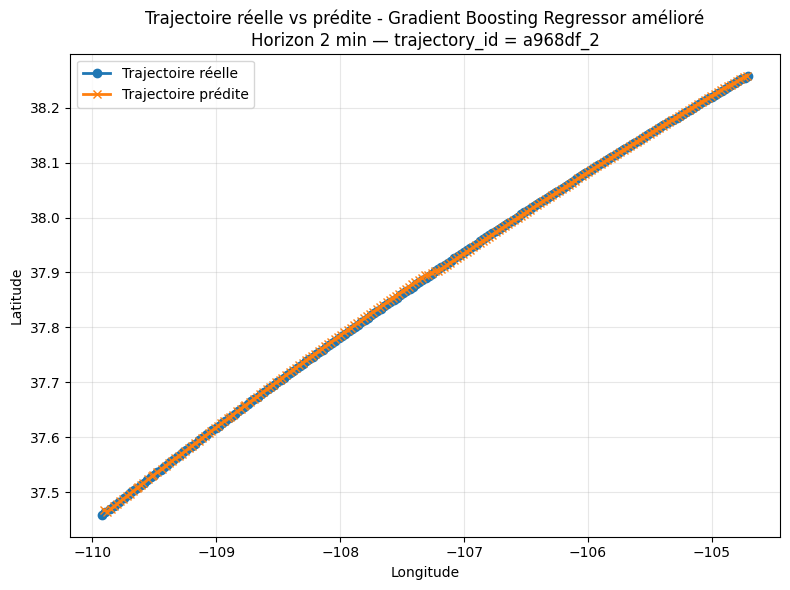

Figure 2D sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/trajectory_2d_best_a968df_2_2min.png


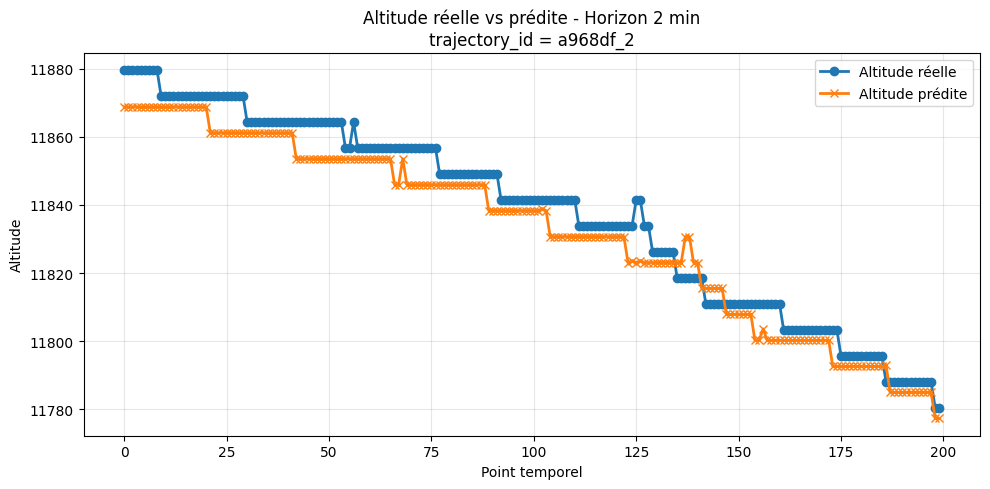

Figure altitude sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/altitude_real_vs_predicted_a968df_2_2min.png


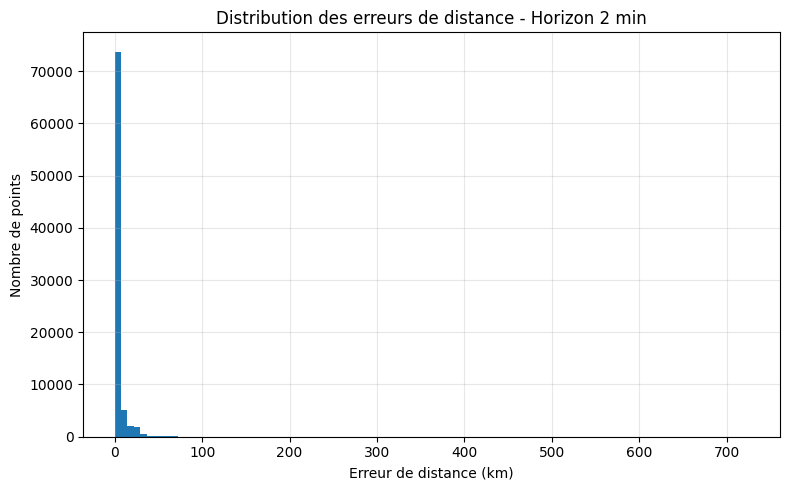

Distribution des erreurs sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/error_distribution_2min.png


Figure 3D sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/trajectory_3d_a968df_2_2min.html
Top erreurs sauvegardées : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/top_errors_2min.csv
LabelEncoder 2min chargé depuis : label_encoder_2min.pkl
PCA SVM 2min chargé depuis : pca_svm_2min.pkl
SVM RBF PCA 2min chargé depuis : svm_rbf_with_pca_2min.pkl
Résultats classification sauvegardés : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/classification_results_2min.csv


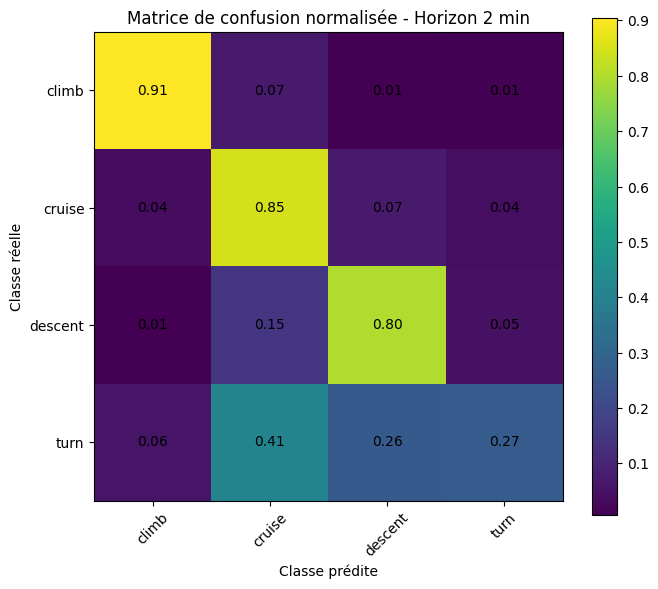

Matrice de confusion sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/confusion_matrix_normalized_2min.png

PIPELINE ML COMPLET — HORIZON 5 MIN
Chargement des splits pour l'horizon 5 min
Vérification des fichiers :
X_train_5min.csv                    => OK
X_val_5min.csv                      => OK
X_test_5min.csv                     => OK
y_train_reg_5min.csv                => OK
y_val_reg_5min.csv                  => OK
y_test_reg_5min.csv                 => OK
y_train_clf_5min.csv                => OK
y_val_clf_5min.csv                  => OK
y_test_clf_5min.csv                 => OK
Métadonnées test chargées : metadata_test_5min.csv

Dimensions chargées :
X_train      : (376663, 32)
X_val        : (75191, 32)
X_test       : (82530, 32)
y_train_reg  : (376663, 3)
y_val_reg    : (75191, 3)
y_test_reg   : (82530, 3)
y_train_clf  : (376663,)
y_val_clf    : (75191,)
y_test_clf   : (82530,)
test_metadata: (82530, 3)
Colonnes position utilisées :
lat : la

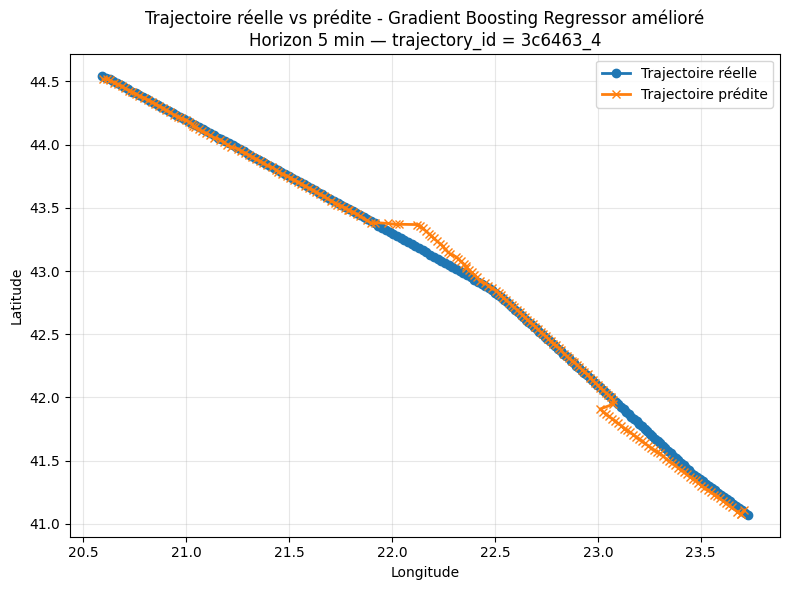

Figure 2D sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/trajectory_2d_best_3c6463_4_5min.png


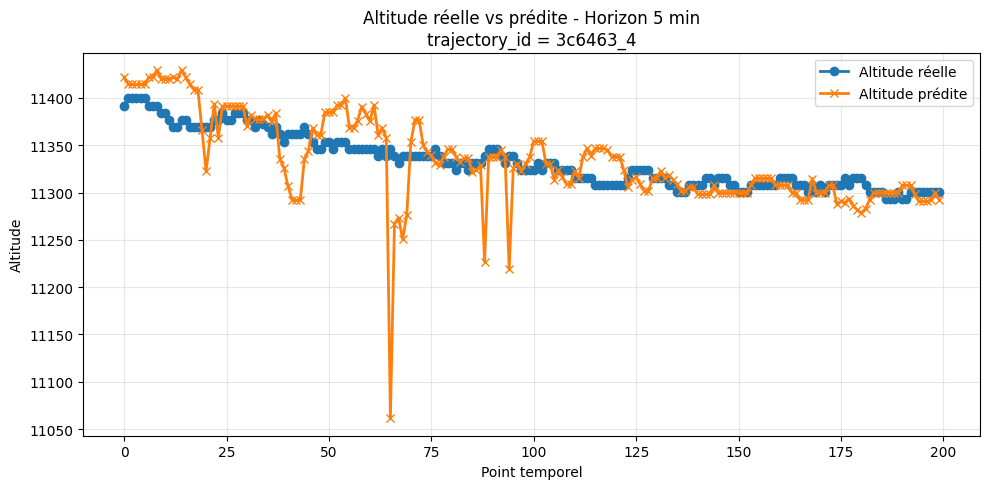

Figure altitude sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/altitude_real_vs_predicted_3c6463_4_5min.png


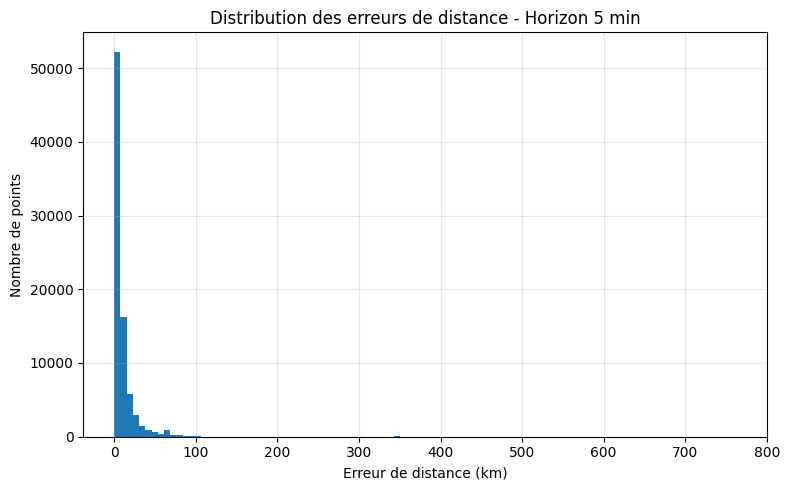

Distribution des erreurs sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/error_distribution_5min.png


Figure 3D sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/trajectory_3d_3c6463_4_5min.html
Top erreurs sauvegardées : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/top_errors_5min.csv
LabelEncoder 5min chargé depuis : label_encoder_5min.pkl
PCA SVM 5min chargé depuis : pca_svm_5min.pkl
SVM RBF PCA 5min chargé depuis : svm_rbf_5min.pkl
Résultats classification sauvegardés : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/classification_results_5min.csv


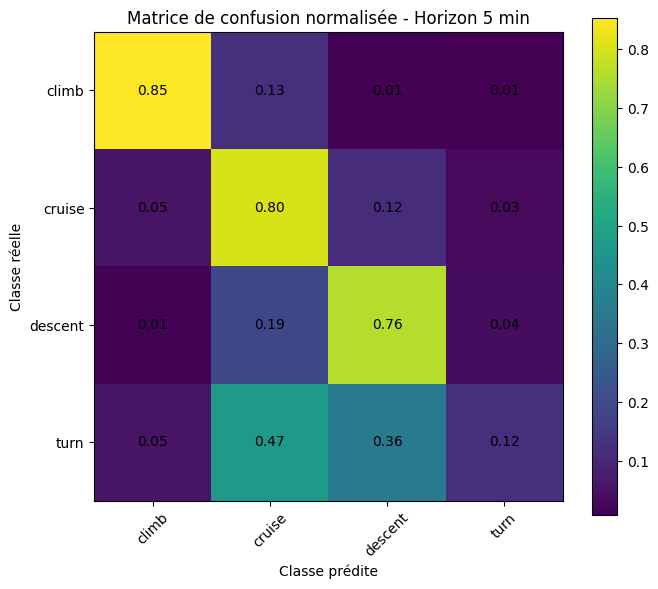

Matrice de confusion sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/confusion_matrix_normalized_5min.png

PIPELINE ML COMPLET — HORIZON 10 MIN
Chargement des splits pour l'horizon 10 min
Vérification des fichiers :
X_train_10min.csv                   => OK
X_val_10min.csv                     => OK
X_test_10min.csv                    => OK
y_train_reg_10min.csv               => OK
y_val_reg_10min.csv                 => OK
y_test_reg_10min.csv                => OK
y_train_clf_10min.csv               => OK
y_val_clf_10min.csv                 => OK
y_test_clf_10min.csv                => OK
Métadonnées test chargées : metadata_test_10min.csv

Dimensions chargées :
X_train      : (340162, 32)
X_val        : (66075, 32)
X_test       : (72783, 32)
y_train_reg  : (340162, 3)
y_val_reg    : (66075, 3)
y_test_reg   : (72783, 3)
y_train_clf  : (340162,)
y_val_clf    : (66075,)
y_test_clf   : (72783,)
test_metadata: (72783, 3)
Colonnes position utilisées :
lat :

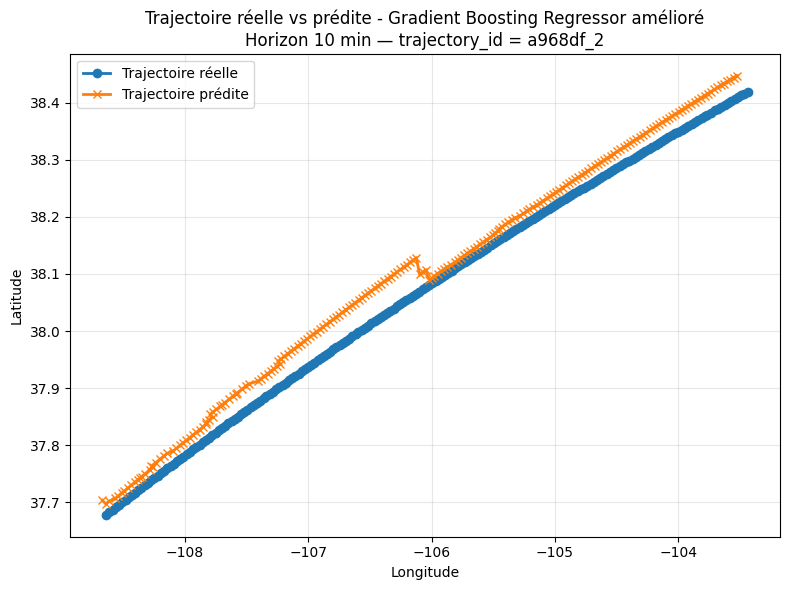

Figure 2D sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/trajectory_2d_best_a968df_2_10min.png


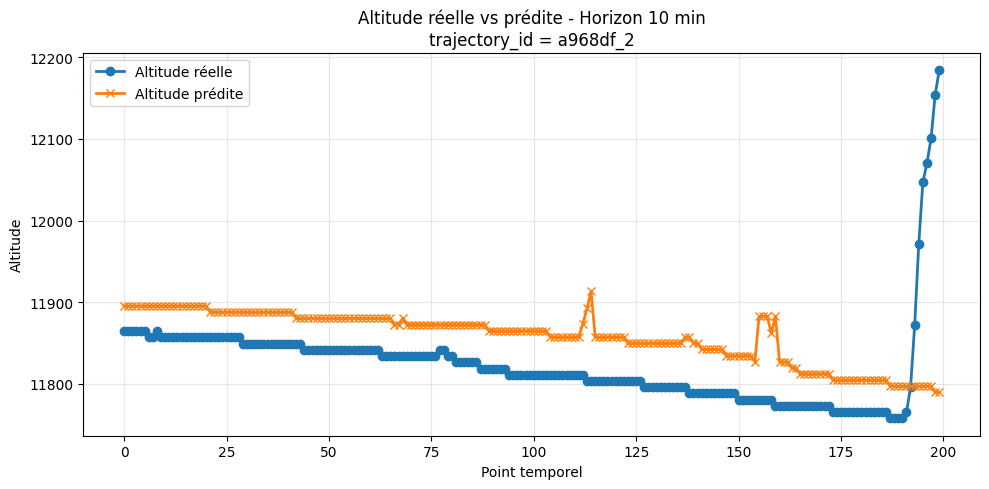

Figure altitude sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/altitude_real_vs_predicted_a968df_2_10min.png


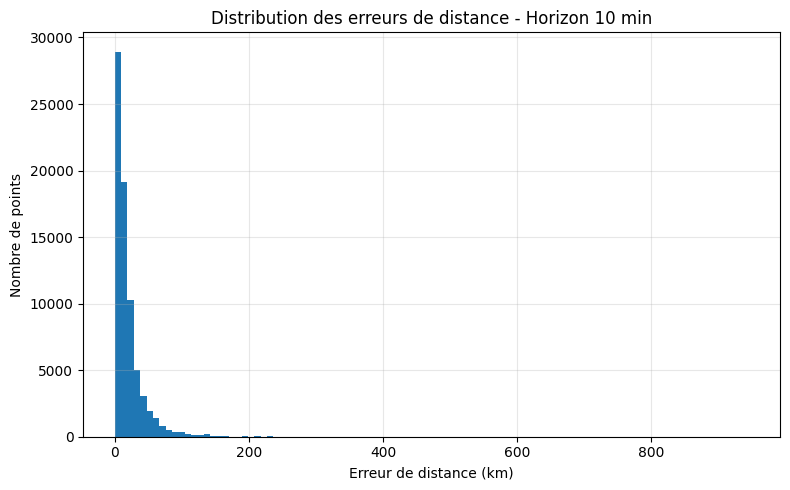

Distribution des erreurs sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/error_distribution_10min.png


Figure 3D sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/trajectory_3d_a968df_2_10min.html
Top erreurs sauvegardées : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/top_errors_10min.csv
LabelEncoder 10min chargé depuis : label_encoder_10min.pkl
PCA SVM 10min chargé depuis : pca_svm_10min.pkl
SVM RBF PCA 10min chargé depuis : svm_rbf_with_pca_10min.pkl
Résultats classification sauvegardés : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/classification_results_10min.csv


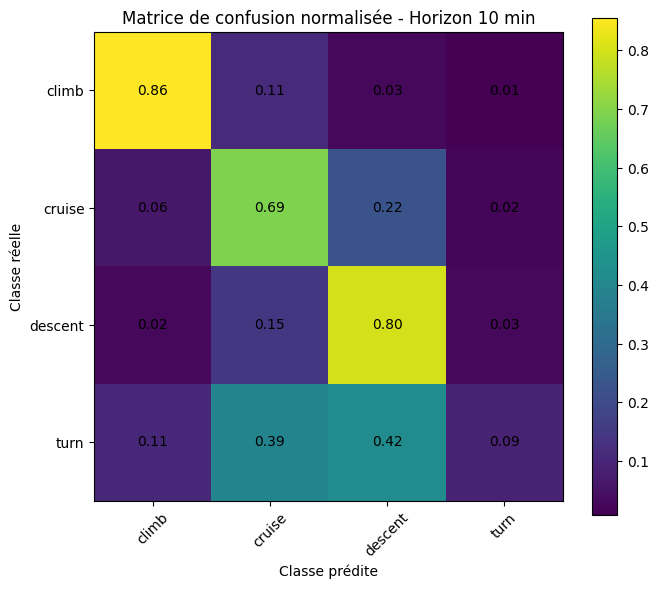

Matrice de confusion sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/confusion_matrix_normalized_10min.png
Expériences multi-horizons terminées.


In [13]:
# ============================================================
# C.7 — Exécution du pipeline sur 2, 5 et 10 minutes
# ============================================================

multi_horizon_outputs = []

for horizon_min in HORIZONS_TO_RUN:
    output = run_full_ml_pipeline_for_horizon(horizon_min)
    multi_horizon_outputs.append(output)

print("Expériences multi-horizons terminées.")

## C.6. Comparaison globale entre les horizons

Nous comparons maintenant les modèles selon :

- l’erreur moyenne de déviation ;
- l’erreur médiane ;
- les percentiles robustes ;
- le temps d’entraînement ;
- les résultats de classification.

In [17]:
# ============================================================
# C.6. Comparaison globale entre les horizons
# ============================================================

# ------------------------------------------------------------
# Vérification
# ------------------------------------------------------------

if "multi_horizon_outputs" not in globals():
    raise NameError("multi_horizon_outputs n'existe pas. Exécute d'abord la boucle multi-horizons.")

if len(multi_horizon_outputs) == 0:
    raise ValueError("multi_horizon_outputs est vide. La boucle multi-horizons n'a pas produit de résultats.")


# ------------------------------------------------------------
# Fonction utilitaire pour récupérer un DataFrame sans erreur
# ------------------------------------------------------------

def get_dataframe_from_output(output, possible_keys):
    """
    Récupère un DataFrame depuis un dictionnaire output.
    Accepte plusieurs noms possibles de clés pour éviter les KeyError.
    """

    for key in possible_keys:
        value = output.get(key, None)

        if isinstance(value, pd.DataFrame) and len(value) > 0:
            return value.copy()

    return pd.DataFrame()


# ------------------------------------------------------------
# 1. Regrouper les résultats de régression
# ------------------------------------------------------------

regression_parts = []

for out in multi_horizon_outputs:
    df_reg = get_dataframe_from_output(
        out,
        possible_keys=["regression_results"]
    )

    if len(df_reg) > 0:
        regression_parts.append(df_reg)

if len(regression_parts) == 0:
    raise ValueError("Aucun résultat de régression trouvé dans multi_horizon_outputs.")

all_regression_results = pd.concat(
    regression_parts,
    ignore_index=True
)


# ------------------------------------------------------------
# 2. Regrouper les résultats de classification
# ------------------------------------------------------------

classification_parts = []

for out in multi_horizon_outputs:
    df_clf = get_dataframe_from_output(
        out,
        possible_keys=["classification_results"]
    )

    if len(df_clf) > 0:
        classification_parts.append(df_clf)

if len(classification_parts) > 0:
    all_classification_results = pd.concat(
        classification_parts,
        ignore_index=True
    )
else:
    all_classification_results = pd.DataFrame()


# ------------------------------------------------------------
# 3. Regrouper les rapports de classification par classe
# ------------------------------------------------------------

class_report_parts = []

for out in multi_horizon_outputs:
    df_report = get_dataframe_from_output(
        out,
        possible_keys=[
            "classification_report",
            "class_report",
            "classification_report_df"
        ]
    )

    if len(df_report) > 0:
        class_report_parts.append(df_report)

if len(class_report_parts) > 0:
    all_class_reports = pd.concat(
        class_report_parts,
        ignore_index=False
    )
else:
    all_class_reports = pd.DataFrame()


# ------------------------------------------------------------
# 4. Sauvegarder les résultats globaux
# ------------------------------------------------------------

all_reg_path = METRICS_DIR / "multi_horizon_regression_results.csv"
all_regression_results.to_csv(all_reg_path, index=False)

print("Résultats globaux de régression sauvegardés :")
print("-", all_reg_path)

all_clf_path = METRICS_DIR / "multi_horizon_classification_results.csv"

if len(all_classification_results) > 0:
    all_classification_results.to_csv(all_clf_path, index=False)
    print("Résultats globaux de classification sauvegardés :")
    print("-", all_clf_path)
else:
    print("Aucun résultat de classification à sauvegarder.")

all_class_reports_path = METRICS_DIR / "multi_horizon_classification_report_by_class.csv"

if len(all_class_reports) > 0:
    all_class_reports.to_csv(all_class_reports_path)
    print("Rapport de classification par classe sauvegardé :")
    print("-", all_class_reports_path)
else:
    print("Aucun rapport de classification par classe à sauvegarder.")


# ------------------------------------------------------------
# 5. Affichage des résultats
# ------------------------------------------------------------

print("\nRésultats globaux de régression :")
display(all_regression_results)

if len(all_classification_results) > 0:
    print("\nRésultats globaux de classification :")
    display(all_classification_results)

if len(all_class_reports) > 0:
    print("\nRapports de classification par classe :")
    display(all_class_reports)


# ------------------------------------------------------------
# 6. Meilleur modèle de régression par horizon
# ------------------------------------------------------------

test_regression_results = all_regression_results[
    all_regression_results["dataset"] == "test"
].copy()

best_models_by_horizon = (
    test_regression_results
    .sort_values(["horizon_min", "mean_deviation_km"])
    .groupby("horizon_min")
    .head(1)
    .reset_index(drop=True)
)

best_models_path = METRICS_DIR / "best_models_by_horizon.csv"
best_models_by_horizon.to_csv(best_models_path, index=False)

print("\nMeilleur modèle de régression par horizon :")
display(best_models_by_horizon)

print("Meilleurs modèles sauvegardés :")
print("-", best_models_path)

Résultats globaux de régression sauvegardés :
- /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/multi_horizon_regression_results.csv
Résultats globaux de classification sauvegardés :
- /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/multi_horizon_classification_results.csv
Rapport de classification par classe sauvegardé :
- /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/multi_horizon_classification_report_by_class.csv

Résultats globaux de régression :


,model,dataset,RMSE_lat_future,MAE_lat_future,RMSE_lon_future,MAE_lon_future,RMSE_altitude_future,MAE_altitude_future,mean_deviation_km,median_deviation_km,max_deviation_km,p90_deviation_km,p95_deviation_km,p99_deviation_km,training_time_sec,horizon_min
0,Baseline naïve,test,0.171847,0.119610,0.237786,0.169353,917.265293,375.199433,21.012601,24.906460,705.564269,30.033103,32.119759,56.491778,0.0,2
1,Decision Tree Regressor amélioré,validation,0.156057,0.114805,0.317062,0.192934,894.091684,254.913837,21.428612,23.219576,729.691381,32.700884,34.829965,57.544884,0.0,2
2,Decision Tree Regressor amélioré,test,0.170687,0.118791,0.234584,0.165519,822.602270,244.202658,20.633522,23.111489,707.307113,31.593597,34.786225,56.382175,0.0,2
3,Random Forest Regressor amélioré,validation,0.129162,0.090641,0.285565,0.159616,727.388196,223.518808,17.499315,18.412549,726.596169,25.543483,27.565386,49.421668,0.0,2
4,Random Forest Regressor amélioré,test,0.144689,0.094409,0.199487,0.134855,704.092002,219.210135,16.757299,17.963060,699.089175,24.739602,27.098093,49.404465,0.0,2
5,Gradient Boosting Regressor amélioré,validation,0.072862,0.022877,0.219893,0.045858,739.062206,233.737302,4.879455,2.032933,746.011649,9.422846,19.528070,34.282138,0.0,2
6,Gradient Boosting Regressor amélioré,test,0.095894,0.025372,0.120481,0.035904,723.073060,232.390897,4.510742,2.017043,724.971553,9.174182,17.088891,33.489908,0.0,2
7,Random Forest optimisé,validation,0.112871,0.073723,0.263624,0.131224,733.257651,223.760874,14.438582,14.077497,724.374938,21.014302,23.781100,46.920616,0.0,2
8,Random Forest optimisé,test,0.129187,0.077852,0.174598,0.110673,702.241562,215.588020,13.814247,13.793565,694.588096,20.845010,23.396130,45.879272,0.0,2
9,Baseline naïve,test,0.381012,0.302162,0.615271,0.469883,1543.352491,812.779274,54.734110,63.636942,736.471148,75.690489,79.324395,108.955558,0.0,5



Résultats globaux de classification :


,horizon_min,model,dataset,accuracy,f1_macro,f1_weighted,training_time_sec
0,2,SVM RBF avec PCA,validation,0.844420,0.645100,0.860662,0.0
1,2,SVM RBF avec PCA,test,0.843090,0.650381,0.857524,0.0
2,5,SVM RBF avec PCA,validation,0.781397,0.597499,0.796881,0.0
3,5,SVM RBF avec PCA,test,0.794172,0.596184,0.806081,0.0
4,10,SVM RBF avec PCA,validation,0.696890,0.524547,0.715710,0.0
5,10,SVM RBF avec PCA,test,0.727038,0.538463,0.743906,0.0



Rapports de classification par classe :


,precision,recall,f1-score,support,horizon_min
climb,0.829327,0.905131,0.865573,12122.000000,2
cruise,0.928033,0.848238,0.886343,54546.000000,2
descent,0.765059,0.798498,0.781421,16908.000000,2
turn,0.039062,0.268041,0.068188,485.000000,2
accuracy,0.843090,0.843090,0.843090,0.843090,2
macro avg,0.640370,0.704977,0.650381,84061.000000,2
weighted avg,0.875889,0.843090,0.857524,84061.000000,2
climb,0.722807,0.854021,0.782955,9563.000000,5
cruise,0.900551,0.801205,0.847978,54624.000000,5
descent,0.669599,0.759529,0.711734,17840.000000,5



Meilleur modèle de régression par horizon :


,model,dataset,RMSE_lat_future,MAE_lat_future,RMSE_lon_future,MAE_lon_future,RMSE_altitude_future,MAE_altitude_future,mean_deviation_km,median_deviation_km,max_deviation_km,p90_deviation_km,p95_deviation_km,p99_deviation_km,training_time_sec,horizon_min
0,Gradient Boosting Regressor amélioré,test,0.095894,0.025372,0.120481,0.035904,723.073060,232.390897,4.510742,2.017043,724.971553,9.174182,17.088891,33.489908,0.0,2
1,Gradient Boosting Regressor amélioré,test,0.139692,0.055853,0.291714,0.097028,970.990545,445.850731,10.890140,5.269714,762.488283,22.870263,36.050088,70.595464,0.0,5
2,Gradient Boosting Regressor amélioré,test,0.197152,0.103136,0.310675,0.175605,1254.414684,732.524719,19.953734,12.244162,944.541587,43.825561,61.638806,117.894737,0.0,10


Meilleurs modèles sauvegardés :
- /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/best_models_by_horizon.csv


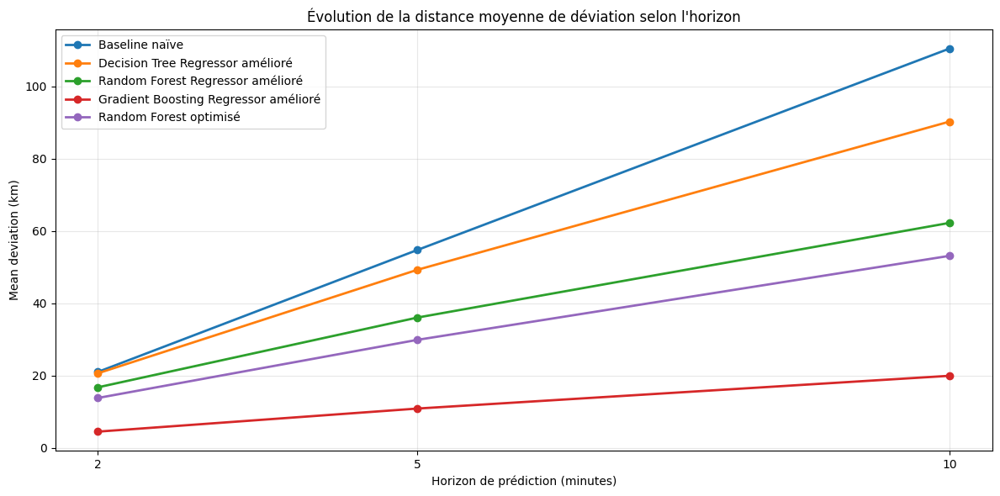

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/multi_horizon_mean_deviation_by_model.png


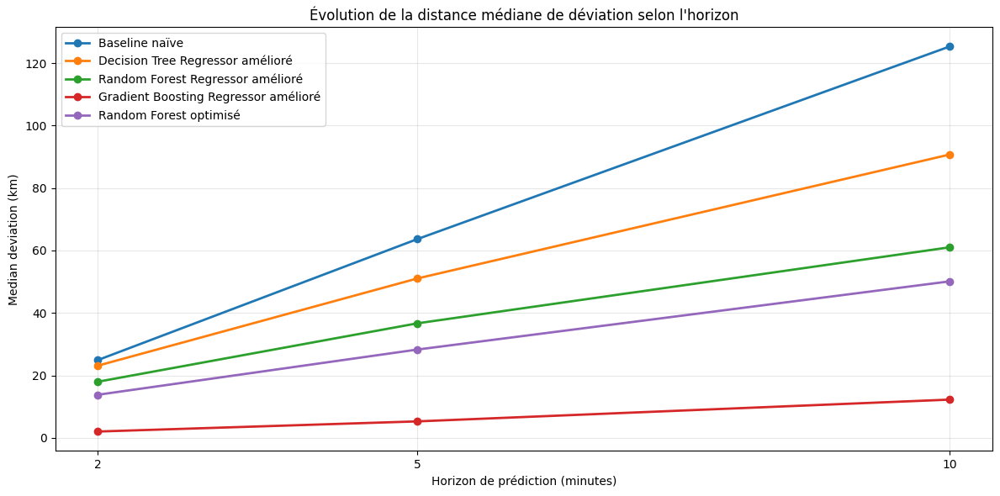

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/multi_horizon_median_deviation_by_model.png


,horizon_min,model,mean_deviation_km,median_deviation_km,p95_deviation_km,max_deviation_km
0,2,Gradient Boosting Regressor amélioré,4.510742,2.017043,17.088891,724.971553
1,5,Gradient Boosting Regressor amélioré,10.890140,5.269714,36.050088,762.488283
2,10,Gradient Boosting Regressor amélioré,19.953734,12.244162,61.638806,944.541587


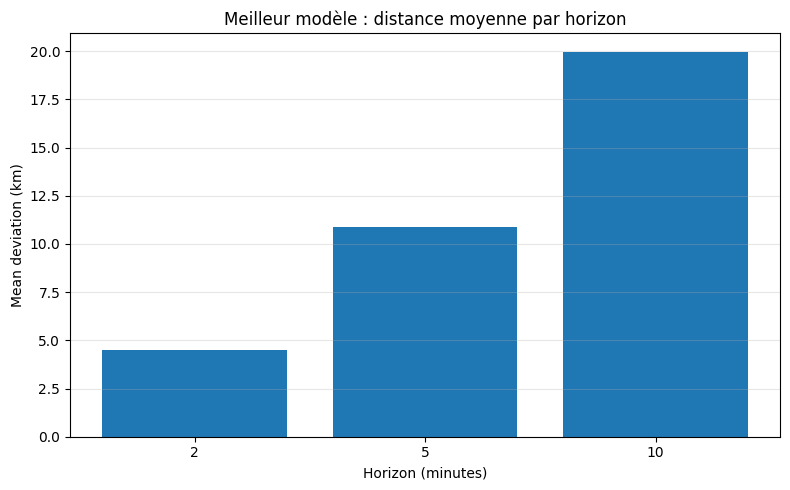

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/multi_horizon_best_model_mean_deviation.png


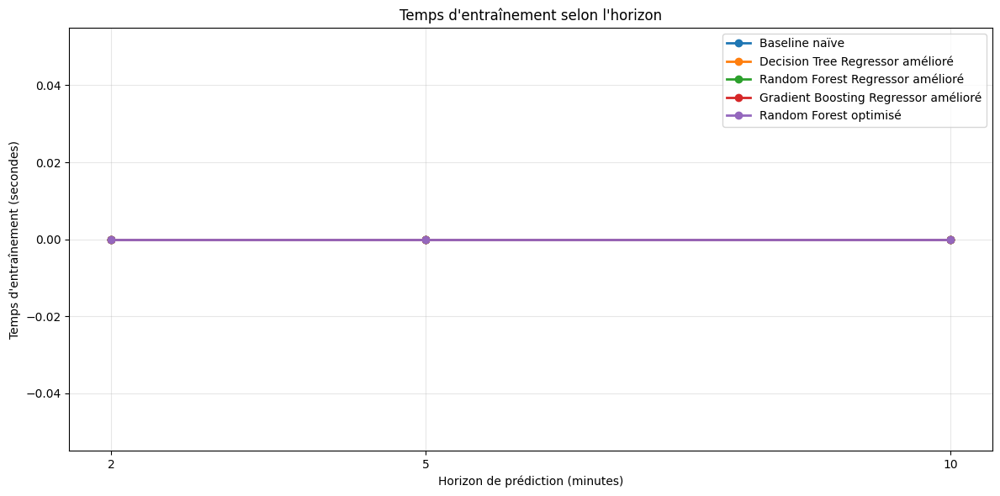

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/multi_horizon_training_time_by_model.png


In [18]:
# ============================================================
# C.7. Graphes de comparaison multi-horizons — régression
# ============================================================

test_reg = all_regression_results[all_regression_results["dataset"] == "test"].copy()

# 1. Erreur moyenne par modèle et horizon
plt.figure(figsize=(12, 6))

for model_name in test_reg["model"].unique():
    sub = test_reg[test_reg["model"] == model_name].sort_values("horizon_min")
    plt.plot(
        sub["horizon_min"],
        sub["mean_deviation_km"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.title("Évolution de la distance moyenne de déviation selon l'horizon")
plt.xlabel("Horizon de prédiction (minutes)")
plt.ylabel("Mean deviation (km)")
plt.xticks(HORIZONS_TO_RUN)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

fig_path = FIGURES_DIR / "multi_horizon_mean_deviation_by_model.png"
plt.savefig(fig_path, bbox_inches="tight", dpi=300)
plt.show()
print("Figure sauvegardée :", fig_path)

# 2. Erreur médiane par modèle et horizon
plt.figure(figsize=(12, 6))

for model_name in test_reg["model"].unique():
    sub = test_reg[test_reg["model"] == model_name].sort_values("horizon_min")
    plt.plot(
        sub["horizon_min"],
        sub["median_deviation_km"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.title("Évolution de la distance médiane de déviation selon l'horizon")
plt.xlabel("Horizon de prédiction (minutes)")
plt.ylabel("Median deviation (km)")
plt.xticks(HORIZONS_TO_RUN)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

fig_path = FIGURES_DIR / "multi_horizon_median_deviation_by_model.png"
plt.savefig(fig_path, bbox_inches="tight", dpi=300)
plt.show()
print("Figure sauvegardée :", fig_path)

# 3. Meilleur modèle par horizon
best_by_horizon = (
    test_reg
    .sort_values(["horizon_min", "mean_deviation_km"])
    .groupby("horizon_min")
    .first()
    .reset_index()
)

display(best_by_horizon[["horizon_min", "model", "mean_deviation_km", "median_deviation_km", "p95_deviation_km", "max_deviation_km"]])

plt.figure(figsize=(8, 5))
plt.bar(best_by_horizon["horizon_min"].astype(str), best_by_horizon["mean_deviation_km"])
plt.title("Meilleur modèle : distance moyenne par horizon")
plt.xlabel("Horizon (minutes)")
plt.ylabel("Mean deviation (km)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

fig_path = FIGURES_DIR / "multi_horizon_best_model_mean_deviation.png"
plt.savefig(fig_path, bbox_inches="tight", dpi=300)
plt.show()
print("Figure sauvegardée :", fig_path)

# 4. Temps d'entraînement
time_reg = test_reg.dropna(subset=["training_time_sec"]).copy()

plt.figure(figsize=(12, 6))

for model_name in time_reg["model"].unique():
    sub = time_reg[time_reg["model"] == model_name].sort_values("horizon_min")
    plt.plot(
        sub["horizon_min"],
        sub["training_time_sec"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.title("Temps d'entraînement selon l'horizon")
plt.xlabel("Horizon de prédiction (minutes)")
plt.ylabel("Temps d'entraînement (secondes)")
plt.xticks(HORIZONS_TO_RUN)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

fig_path = FIGURES_DIR / "multi_horizon_training_time_by_model.png"
plt.savefig(fig_path, bbox_inches="tight", dpi=300)
plt.show()
print("Figure sauvegardée :", fig_path)

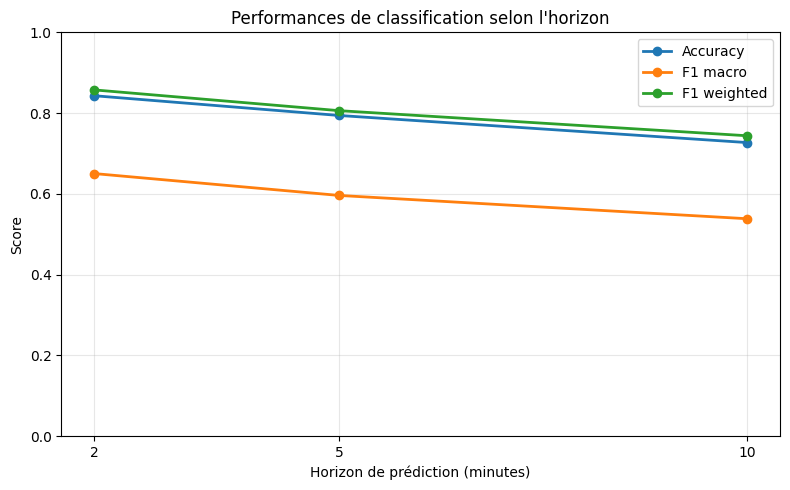

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/multi_horizon_classification_scores.png
Rapport de classification par classe nettoyé :


,class,precision,recall,f1-score,support,horizon_min
0,climb,0.829327,0.905131,0.865573,12122.0,2
1,cruise,0.928033,0.848238,0.886343,54546.0,2
2,descent,0.765059,0.798498,0.781421,16908.0,2
3,turn,0.039062,0.268041,0.068188,485.0,2
7,climb,0.722807,0.854021,0.782955,9563.0,5
8,cruise,0.900551,0.801205,0.847978,54624.0,5
9,descent,0.669599,0.759529,0.711734,17840.0,5
10,turn,0.025448,0.121272,0.042069,503.0,5
14,climb,0.585746,0.856059,0.695563,5933.0,10
15,cruise,0.916517,0.691230,0.788089,50157.0,10


Rapport nettoyé sauvegardé : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics/multi_horizon_classification_report_by_class_clean.csv
F1-score par classe et par horizon :


horizon_min,2,5,10
class,,,
climb,0.865573,0.782955,0.695563
cruise,0.886343,0.847978,0.788089
descent,0.781421,0.711734,0.640441
turn,0.068188,0.042069,0.029759


<Figure size 1000x600 with 0 Axes>

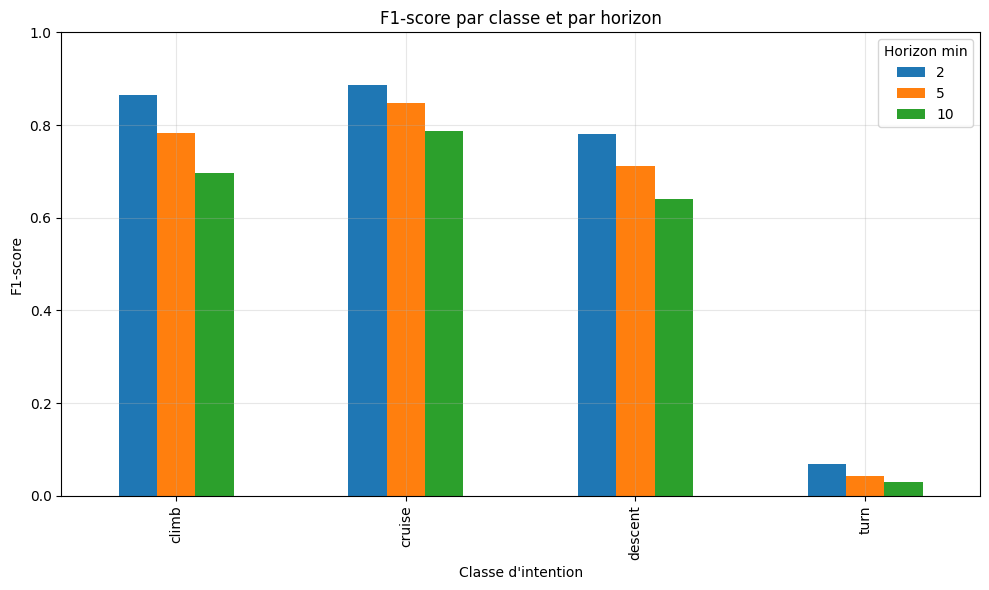

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/multi_horizon_f1_score_by_class.png


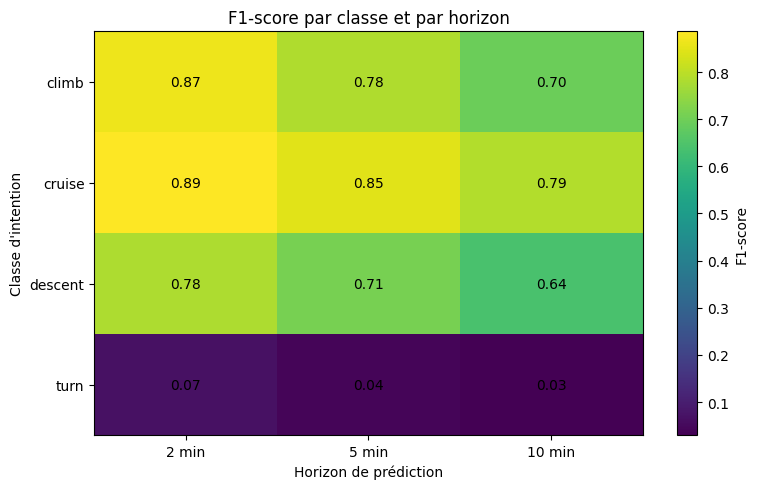

Figure sauvegardée : /content/drive/MyDrive/aircraft-trajectory-prediction/results/figures/multi_horizon_f1_score_by_class_heatmap.png


In [20]:
# ============================================================
# C.8. Graphes de comparaison multi-horizons — classification
# Version corrigée
# ============================================================

# ------------------------------------------------------------
# 1. Vérifier les résultats de classification
# ------------------------------------------------------------

if "all_classification_results" not in globals():
    print("all_classification_results n'existe pas. Exécute d'abord la cellule de comparaison globale.")

elif len(all_classification_results) == 0:
    print("Aucun résultat de classification disponible.")

else:
    # --------------------------------------------------------
    # 2. Graphe Accuracy / F1 selon l'horizon
    # --------------------------------------------------------

    test_clf = all_classification_results[
        all_classification_results["dataset"] == "test"
    ].copy()

    plt.figure(figsize=(8, 5))

    plt.plot(
        test_clf["horizon_min"],
        test_clf["accuracy"],
        marker="o",
        linewidth=2,
        label="Accuracy"
    )

    plt.plot(
        test_clf["horizon_min"],
        test_clf["f1_macro"],
        marker="o",
        linewidth=2,
        label="F1 macro"
    )

    plt.plot(
        test_clf["horizon_min"],
        test_clf["f1_weighted"],
        marker="o",
        linewidth=2,
        label="F1 weighted"
    )

    plt.title("Performances de classification selon l'horizon")
    plt.xlabel("Horizon de prédiction (minutes)")
    plt.ylabel("Score")
    plt.xticks(HORIZONS_TO_RUN)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    fig_path = FIGURES_DIR / "multi_horizon_classification_scores.png"
    plt.savefig(fig_path, bbox_inches="tight", dpi=300)
    plt.show()

    print("Figure sauvegardée :", fig_path)

    # --------------------------------------------------------
    # 3. Reconstruire proprement le rapport par classe
    # --------------------------------------------------------

    class_report_parts = []

    if "multi_horizon_outputs" in globals():
        for output in multi_horizon_outputs:

            horizon_min = output.get("horizon_min", None)

            report_df = output.get("classification_report", None)

            # Compatibilité avec d'autres noms possibles
            if report_df is None:
                report_df = output.get("class_report", None)

            if report_df is None:
                report_df = output.get("classification_report_df", None)

            if report_df is not None and isinstance(report_df, pd.DataFrame) and len(report_df) > 0:
                temp_report = report_df.copy()

                # Les classes sont souvent dans l'index, donc on les transforme en colonne
                if "class" not in temp_report.columns:
                    temp_report = temp_report.reset_index()

                    if "index" in temp_report.columns:
                        temp_report = temp_report.rename(columns={"index": "class"})
                    elif "level_0" in temp_report.columns:
                        temp_report = temp_report.rename(columns={"level_0": "class"})
                    else:
                        temp_report["class"] = temp_report.index.astype(str)

                # Ajouter horizon_min si absent
                if "horizon_min" not in temp_report.columns:
                    temp_report["horizon_min"] = horizon_min

                class_report_parts.append(temp_report)

    if len(class_report_parts) == 0:
        print("Aucun rapport de classification par classe disponible.")

    else:
        all_class_reports_clean = pd.concat(
            class_report_parts,
            ignore_index=True
        )

        # ----------------------------------------------------
        # 4. Nettoyer : garder seulement les vraies classes
        # ----------------------------------------------------

        rows_to_remove = ["accuracy", "macro avg", "weighted avg"]

        class_rows = all_class_reports_clean[
            ~all_class_reports_clean["class"].astype(str).isin(rows_to_remove)
        ].copy()

        # Conversion numérique
        for col in ["precision", "recall", "f1-score", "support"]:
            if col in class_rows.columns:
                class_rows[col] = pd.to_numeric(class_rows[col], errors="coerce")

        # Supprimer les lignes sans F1-score
        class_rows = class_rows.dropna(subset=["f1-score"])

        print("Rapport de classification par classe nettoyé :")
        display(class_rows)

        # Sauvegarde du rapport nettoyé
        clean_report_path = METRICS_DIR / "multi_horizon_classification_report_by_class_clean.csv"
        class_rows.to_csv(clean_report_path, index=False)

        print("Rapport nettoyé sauvegardé :", clean_report_path)

        # ----------------------------------------------------
        # 5. Tableau pivot F1-score par classe et horizon
        # ----------------------------------------------------

        pivot_f1 = class_rows.pivot_table(
            index="class",
            columns="horizon_min",
            values="f1-score",
            aggfunc="mean"
        )

        print("F1-score par classe et par horizon :")
        display(pivot_f1)

        # ----------------------------------------------------
        # 6. Graphe barplot F1-score par classe
        # ----------------------------------------------------

        plt.figure(figsize=(10, 6))
        pivot_f1.plot(kind="bar", figsize=(10, 6))

        plt.title("F1-score par classe et par horizon")
        plt.xlabel("Classe d'intention")
        plt.ylabel("F1-score")
        plt.ylim(0, 1)
        plt.grid(True, alpha=0.3)
        plt.legend(title="Horizon min")
        plt.tight_layout()

        fig_path = FIGURES_DIR / "multi_horizon_f1_score_by_class.png"
        plt.savefig(fig_path, bbox_inches="tight", dpi=300)
        plt.show()

        print("Figure sauvegardée :", fig_path)

        # ----------------------------------------------------
        # 7. Heatmap F1-score par classe et horizon
        # ----------------------------------------------------

        fig, ax = plt.subplots(figsize=(8, 5))

        im = ax.imshow(
            pivot_f1.values,
            aspect="auto"
        )

        ax.set_xticks(np.arange(len(pivot_f1.columns)))
        ax.set_xticklabels([f"{col} min" for col in pivot_f1.columns])

        ax.set_yticks(np.arange(len(pivot_f1.index)))
        ax.set_yticklabels(pivot_f1.index)

        for i in range(len(pivot_f1.index)):
            for j in range(len(pivot_f1.columns)):
                value = pivot_f1.values[i, j]

                if not pd.isna(value):
                    ax.text(
                        j,
                        i,
                        f"{value:.2f}",
                        ha="center",
                        va="center"
                    )

        plt.colorbar(im, ax=ax, label="F1-score")

        plt.title("F1-score par classe et par horizon")
        plt.xlabel("Horizon de prédiction")
        plt.ylabel("Classe d'intention")
        plt.tight_layout()

        fig_path = FIGURES_DIR / "multi_horizon_f1_score_by_class_heatmap.png"
        plt.savefig(fig_path, bbox_inches="tight", dpi=300)
        plt.show()

        print("Figure sauvegardée :", fig_path)

## C.9. Conclusion multi-horizons

Cette section permet de conclure sur l’effet de l’horizon de prédiction.

À commenter dans le rapport :

- les erreurs augmentent généralement lorsque l’horizon passe de 2 à 5 puis 10 minutes ;
- le modèle qui donne la meilleure performance doit être identifié pour chaque horizon ;
- la baseline naïve devient de plus en plus faible lorsque l’horizon augmente ;
- les visualisations de trajectoires montrent concrètement où le modèle suit bien la trajectoire et où il échoue ;
- les erreurs extrêmes doivent être discutées avec les percentiles P90/P95/P99, car le maximum est très sensible aux points aberrants.